# 생성모델-2 · cGAN과 생성 평가

**한 줄 요약** · 원하는 숫자를 지정해서 만들고(cGAN), 잘 만들었다는 근거를 점검한 측정 여러 개로 보임

- **조건 입력**(1 · 2장): 번호 · one-hot · Embedding · 노이즈 뒤에 라벨 줄 · 판별자에 라벨 판 · 조건부 두 차례
- **생성 평가**(3장): 도구 점검 · 베끼기 점검 · 라벨 안 다양성 · 일치율 · 혼동 행렬 · 꼼수 점검 · FID · IS(개념)
- **더 잘 만들기 · 다음**(4장): 손잡이는 한 번에 하나 · Diffusion 정방향(자세히는 생성모델-1 4장) · 세 축
- **종합 실습**(5장): 판별자 라벨 없음 vs 있음을 seed만 바꿔 다시 → 같은 판정표
- 코드 출처: 수업 Day01 D1-8 · Day02 장면은 **코드 재현**(수업 html은 출력만 있음), cGAN 구현하기 실습은 **실습 코드**

## 🎯 학습 목표

이 노트북을 끝내면 **자료를 보지 않고** 다음을 할 수 있어야 함

1. 라벨 번호를 번호 그대로 · one-hot · `nn.Embedding`으로 넣는 차이를 거리로 설명하고, 노이즈 뒤에 `torch.cat`으로 붙인다
2. 판별자에 라벨 판을 채널로 붙인 cGAN을 만들고, 조건부 두 차례(진짜 · 가짜의 라벨 짝)를 코드로 쓴다
3. 판별자에 라벨이 없으면 요청한 숫자가 나오지 않음을 격자와 일치율로 보인다
4. 생성 평가 측정(베끼기 · 다양성 · 일치율 · FID)을 먼저 점검하고, 측정 하나로 결론 내지 않고 판정표로 본다
5. 손잡이는 한 번에 하나만 바꾸고, seed만 바꿔 다시 해 결론이 유지되는지 확인한다

## 어디에 쓰나

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">실제 상황</th>
<th style="text-align: left;">이 권에서 배우는 것</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">"고양이만 · 운동화만" 처럼 종류를 지정해 생성해야 할 때</td>
<td style="text-align: left;">라벨 입력 · cGAN 생성자 · 판별자 (1 · 2장)</td>
</tr>
<tr>
<td style="text-align: left;">범주형 입력(종류 · 단어 번호)을 신경망에 넣을 때</td>
<td style="text-align: left;">번호 vs one-hot vs <code>nn.Embedding</code> (1-1)</td>
</tr>
<tr>
<td style="text-align: left;">생성 결과가 좋다는 근거를 보고서에 써야 할 때</td>
<td style="text-align: left;">점검한 측정 · 판정표 · FID의 한계 (3장)</td>
</tr>
<tr>
<td style="text-align: left;">결과를 더 좋게 하려고 설정을 바꿀 때</td>
<td style="text-align: left;">한 번에 하나 · 실험 기록 · seed 반복 (4 · 5장)</td>
</tr>
<tr>
<td style="text-align: left;">미션(FashionMNIST cGAN)을 시작할 때</td>
<td style="text-align: left;">학습 전 정할 것 · 평가 계획 · 첫 실험 (부록)</td>
</tr>
</tbody>
</table>

## 학습 지도

<img src="images/gen2_map.png" alt="생성모델-2 학습 지도 · 라벨 넣기 → cGAN 학습 → 생성 평가 → 더 잘 · 다음 → 종합 실습" width="941">

**예상 학습 시간** · 개념 3시간 + 실습 1시간 (GPU에서 본문 실행 약 20분 · 부록 전체 코드까지 돌리면 그 두 배 · CPU는 학습과 FID가 수십 분 ~ 몇 시간)

## 목차

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: center;">장</th>
<th style="text-align: left;">제목</th>
<th style="text-align: left;">이 장의 질문</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: center;">0</td>
<td style="text-align: left;">준비</td>
<td style="text-align: left;">라이브러리 · seed · 실행 장치 · MNIST와 라벨</td>
</tr>
<tr>
<td style="text-align: center;">1</td>
<td style="text-align: left;">원하는 숫자를 입력에 넣기</td>
<td style="text-align: left;">라벨 번호를 생성자 입력의 어디에 · 어떤 모양으로 넣을까?</td>
</tr>
<tr>
<td style="text-align: center;">2</td>
<td style="text-align: left;">cGAN 판별자 · 학습</td>
<td style="text-align: left;">판별자에도 라벨이 필요한가, 두 차례 학습은 Day1과 무엇이 다른가?</td>
</tr>
<tr>
<td style="text-align: center;">3</td>
<td style="text-align: left;">잘 만들었다는 근거 · 생성 평가</td>
<td style="text-align: left;">숫자 모양 · 다양성 · 지정을 무엇으로 재고, 그 측정을 믿어도 되는가?</td>
</tr>
<tr>
<td style="text-align: center;">4</td>
<td style="text-align: left;">더 잘 만들기 · Diffusion · 요즘 모델</td>
<td style="text-align: left;">무엇을 바꾸고 어떻게 비교하며, 겨루지 않는 방법은 무엇인가?</td>
</tr>
<tr>
<td style="text-align: center;">5</td>
<td style="text-align: left;">종합 실습</td>
<td style="text-align: left;">seed만 바꿔도 '판별자에 라벨이 있어야 한다'는 결론이 유지되는가?</td>
</tr>
<tr>
<td style="text-align: center;">—</td>
<td style="text-align: left;">마무리 · 부록</td>
<td style="text-align: left;">오늘 배운 것 · 기억 확인 · 오답 노트 · 면접 · 요약표 · 복습일 · 원본 대응표 · 미션 준비 · 전체 코드</td>
</tr>
</tbody>
</table>

---
## 0. 준비

- 라이브러리 · seed · 장치를 정하고, MNIST 학습 6만 장 · 시험 1만 장과 **라벨**(숫자 정답)을 불러옴
- 생성모델-1과 달리 사진을 판 모양 `(N, 1, 28, 28)`으로 둠 (DCGAN 판별자 · 라벨 판을 채널로 붙이기 위해)
- **셀은 위에서부터 차례로 실행** (앞 섹션의 변수를 이어서 씀)

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">항목</th>
<th style="text-align: left;">내용</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">재현성</td>
<td style="text-align: left;"><code>torch.manual_seed</code> · <code>cudnn.deterministic = True</code> + <code>torch.use_deterministic_algorithms(True)</code>, 데이터 · 노이즈 · 가짜 라벨도 seed 고정 생성기로</td>
</tr>
<tr>
<td style="text-align: left;">장치</td>
<td style="text-align: left;">GPU가 있으면 <code>cuda</code>(이때 CPU 스레드 1개), 없으면 <code>cpu</code>로 그대로 실행 (CPU에서는 학습 · FID가 수십 분)</td>
</tr>
<tr>
<td style="text-align: left;">내려받기</td>
<td style="text-align: left;">처음 실행 때만 <code>data/MNIST/</code>에 약 12MB · 3-5에서 InceptionV3 가중치 약 104MB (GitHub에는 올리지 않음)</td>
</tr>
<tr>
<td style="text-align: left;">코드 표시</td>
<td style="text-align: left;">첫 주석 <code>[수업 재현 …]</code> = 수업 장면을 코드로 다시 만듦 · <code>[실습 반영]</code> = cGAN 구현하기 실습 코드 · <code>[보강]</code> = 수업 · 실습에 없는 코드</td>
</tr>
</tbody>
</table>

In [1]:
# [보강] 라이브러리 · 재현성 · 장치 설정
import os                 # 환경 변수 설정
import random             # 파이썬 난수 seed
import warnings           # FID 행렬 제곱근 경고 숨김
from pathlib import Path  # 데이터 폴더 경로

if "KMP_DUPLICATE_LIB_OK" not in os.environ:           # Windows Anaconda 충돌 방지
    os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"        # numpy · torch OpenMP 중복
if "CUBLAS_WORKSPACE_CONFIG" not in os.environ:        # GPU 행렬 곱 결정적으로
    os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"  # torch 불러오기 전에

import matplotlib.pyplot as plt      # 격자 · 혼동 행렬 · 막대 그림
import numpy as np                   # FID 공분산 계산
import scipy.linalg                  # FID 행렬 제곱근
import torch                         # 텐서 · 자동 미분
import torch.nn.functional as F      # one_hot · cross_entropy · interpolate
import torchvision                   # MNIST · inception_v3
from matplotlib import font_manager  # 설치된 글꼴 목록
from torch import nn                 # 층 · 손실 함수

SEED = 42  # 모든 난수의 출발점


def set_seed(seed=SEED):                       # 실험마다 같은 출발점으로 되돌림
    random.seed(seed)                          # 파이썬 난수
    np.random.seed(seed)                       # numpy 난수
    torch.manual_seed(seed)                    # CPU · GPU 난수 모두 고정
    torch.cuda.manual_seed_all(seed)           # GPU가 여러 개여도 고정
    torch.backends.cudnn.deterministic = True  # 합성곱 결정적
    torch.backends.cudnn.benchmark = False     # 알고리즘 자동 선택 끔
    torch.use_deterministic_algorithms(True)   # 나머지 연산도 결정적


set_seed()                                              # 노트북 시작 상태 고정
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")  # GPU 없으면 cpu
if device.type == "cuda":                               # 계산은 GPU가 하므로 CPU 스레드는 1개로
    torch.set_num_threads(1)                            # 작은 CPU 연산의 스레드 경쟁 방지
print("torch", torch.__version__, "| device:", device)  # 실행 환경 확인

torch 2.11.0+cu128 | device: cuda


In [2]:
# [보강] 그림 한글 글꼴 · 공통 손실 · 격자 그림 함수
fonts = {f.name for f in font_manager.fontManager.ttflist}    # 설치된 글꼴 이름
for name in ["Malgun Gothic", "AppleGothic", "NanumGothic"]:  # Windows · Mac · Linux 순서
    if name in fonts:                                         # 있는 글꼴만
        plt.rcParams["font.family"] = name                    # 그림 제목의 한글이 깨지지 않게
        break                                                 # 첫 번째로 찾은 것 사용
plt.rcParams["axes.unicode_minus"] = False                    # 음수 부호 깨짐 방지
bce = nn.BCEWithLogitsLoss()                                  # 판별자 출력 = 로짓 (sigmoid 전 점수)


def grid(x, rows):  # 사진 묶음 (N, 1, 28, 28) → 줄 rows개짜리 한 장
    x = (x.detach().cpu().view(rows, -1, 28, 28) + 1) / 2  # -1 ~ 1 → 0 ~ 1
    return x.permute(0, 2, 1, 3).reshape(rows * 28, -1)    # 줄 · 칸 순서로 이어 붙임


def n_par(m):                                      # 가중치 개수 (학습으로 고치는 숫자의 개수)
    return sum(p.numel() for p in m.parameters())  # 층마다 가중치 · 편향 개수의 합

In [3]:
# [보강] MNIST: 없으면 내려받음 (약 12MB, 처음 1번) · 학습 6만 장 · 시험 1만 장
DATA = Path("data")                                                         # 노트북 옆 data/ 폴더
mnist = torchvision.datasets.MNIST(DATA, train=True, download=True)         # 학습용 6만 장
test = torchvision.datasets.MNIST(DATA, train=False, download=True)         # 시험용 1만 장
X = (mnist.data.float() / 255 * 2 - 1).view(-1, 1, 28, 28)  # -1 ~ 1 · 판 한 장 (생성자 Tanh와 맞춤)
Y = mnist.targets  # 라벨 = 사진이 어떤 숫자인지 (0 ~ 9)
X_te = (test.data.float() / 255 * 2 - 1).view(-1, 1, 28, 28)                # 시험 사진도 같은 범위
Y_te = test.targets                                                         # 시험 라벨
print("학습:", tuple(X.shape), "| 시험:", tuple(X_te.shape),                # 모양
      "| 범위:", X.min().item(), "~", X.max().item())
print("라벨 앞 10개", Y[:10].tolist(), "| 라벨 종류", Y.unique().tolist())  # 번호 0 ~ 9

학습: (60000, 1, 28, 28) | 시험: (10000, 1, 28, 28) | 범위: -1.0 ~ 1.0
라벨 앞 10개 [5, 0, 4, 1, 9, 2, 1, 3, 1, 4] | 라벨 종류 [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]


**결과** · 사진은 생성자 출력과 같은 범위, 라벨은 번호 0 ~ 9

- `학습: (60000, 1, 28, 28) | 시험: (10000, 1, 28, 28) | 범위: -1.0 ~ 1.0` — 판 한 장 모양 · 생성자 끝 `Tanh` 범위와 맞춤
- `라벨 앞 10개 [5, 0, 4, 1, 9, 2, 1, 3, 1, 4] | 라벨 종류 [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]` — 라벨 = 사진이 어떤 숫자인지 (1장에서 생성자 입력에 넣을 것)

> ⚠️ **주의**
>
> - 라벨은 **번호**일 뿐 크기 · 순서의 뜻이 없음 (1-1)
> - 생성 평가(3장)의 기준 사진은 학습에 안 쓴 시험 사진

---
## 1. 원하는 숫자를 입력에 넣기

**수업 Day01 D1-8 · Day02 D2-1**

> **이 장의 흐름**
>
> - 생성모델-1(Day1)의 생성자 입력은 노이즈 64칸뿐이라 '7을 줘'라고 할 수 없었음
> - 라벨 번호를 넣을 모양(번호 · one-hot · Embedding)을 고르고, 노이즈 뒤에 이어 붙인 생성자를 만듦.

**파이프라인 위치** · 조건부 생성의 출발점 — 라벨 번호 → 줄(Embedding) → 노이즈와 이어 붙이기 → 생성자

### 1-1. `A` 라벨 번호를 넣는 세 가지 모양 · `F.one_hot` · `nn.Embedding` <sub>수업 Day01 D1-8 · Day02 D2-1 · 코드 재현</sub>

> 🎯 **라벨 번호(0 ~ 9)를 생성자 입력에 넣을 때 번호 그대로 · one-hot · nn.Embedding은 무엇이 다른가?**

💡 **쉽게 말하면**

- 번호 7을 칸 하나에 그대로 넣으면 신경망은 **7이 3보다 크고 8과 가깝다**고 읽음.
- 숫자 종류에는 그런 크기가 없으니, one-hot(10칸 중 한 칸만 1)으로 크기를 없앰.
- nn.Embedding은 one-hot × 표와 같은 일을 **번호로 표의 한 줄을 꺼내** 바로 하고, 표 값은 학습으로 배움.

<img src="images/gen2_cond.png" alt="라벨 번호를 생성자 입력에 넣는 세 가지 · torch.cat" width="912">

**실행 흐름**

1. 어제 생성자 입력 확인
2. 번호 그대로의 거리
3. one-hot과 거리
4. 작은 표 W로 one-hot × W = 줄 꺼내기
5. 같은 표의 Embedding
6. Embedding(10, 10) 모양

**먼저 예측** · one-hot으로 바꾸면 7과 8의 거리, 7과 1의 거리는 각각 얼마일까? — 답은 코드 실행 결과 아래에

In [4]:
# [수업 재현 D1-8 · D2-1] 번호를 생성자 입력에 넣는 세 가지: 번호 그대로 · one-hot · Embedding
ZD = 64  # 노이즈(잠재 벡터) 길이 (생성모델-1과 같음)
z = torch.randn(1, ZD, generator=torch.Generator().manual_seed(SEED))  # 어제 생성자의 입력
print("어제 생성자 입력", tuple(z.shape), "· 64칸 어디에도 숫자를 정하는 자리가 없음")  # 노이즈뿐

num = torch.tensor([7.0, 8.0, 1.0])                                  # 번호를 칸 하나에 그대로
print("번호 그대로 · 7과 8의 거리", (num[0] - num[1]).abs().item(),  # 1
      "· 7과 1의 거리", (num[0] - num[2]).abs().item())              # 6 → 크기 · 순서가 뜻을 가짐
oh = F.one_hot(torch.tensor([7, 8, 1]), 10).float()                  # 10칸 중 그 번호 칸만 1
print("one-hot 1 →", oh[2].int().tolist())                           # 0번부터 세니 왼쪽에서 둘째 칸
print("one-hot 7 →", oh[0].int().tolist())                           # 여덟째 칸
print(f"one-hot 7과 8의 거리 {torch.dist(oh[0], oh[1]):.3f}"         # 어느 두 번호든
      f" · 7과 1의 거리 {torch.dist(oh[0], oh[2]):.3f}")             # 같은 거리 √2

# 작은 예: 번호 3종류 · 줄마다 2칸인 가중치 표 W
W = torch.tensor([[1.0, 2.0], [3.0, 4.0], [5.0, 6.0]])  # 3 × 2 표
pick = F.one_hot(torch.tensor([1]), 3).float() @ W  # one-hot [0, 1, 0] × W
emb = nn.Embedding(3, 2)                            # 번호 3종류 × 줄마다 2칸
with torch.no_grad():                               # 표 값을 직접 넣음 (학습 아님)
    emb.weight.copy_(W)                             # 같은 표로 맞춤
row = emb(torch.tensor([1]))                        # 번호 1로 줄 꺼내기
print("one-hot × W =", pick[0].tolist(), "· W의 1번 줄 =", W[1].tolist())  # 곱셈 = 줄 꺼내기
print("Embedding으로 번호 1 →", row[0].tolist(),    # 같은 줄
      "· one-hot × W와 같음:", torch.equal(row, pick))
set_seed()                                          # 표 초기값 고정
emb10 = nn.Embedding(10, 10)                        # 번호 10종류 × 줄마다 10칸 (생성자에 넣을 크기)
print("Embedding(10, 10)에 번호 7 → 모양", tuple(emb10(torch.tensor([7])).shape),  # (1, 10)
      "· 표의 가중치 개수", n_par(emb10))           # 10 × 10 = 100

어제 생성자 입력 (1, 64) · 64칸 어디에도 숫자를 정하는 자리가 없음
번호 그대로 · 7과 8의 거리 1.0 · 7과 1의 거리 6.0
one-hot 1 → [0, 1, 0, 0, 0, 0, 0, 0, 0, 0]
one-hot 7 → [0, 0, 0, 0, 0, 0, 0, 1, 0, 0]
one-hot 7과 8의 거리 1.414 · 7과 1의 거리 1.414
one-hot × W = [3.0, 4.0] · W의 1번 줄 = [3.0, 4.0]
Embedding으로 번호 1 → [3.0, 4.0] · one-hot × W와 같음: True
Embedding(10, 10)에 번호 7 → 모양 (1, 10) · 표의 가중치 개수 100


**결과** · 예측 정답은 둘 다 1.414 (√2) — 어느 두 번호든 같은 거리

- `어제 생성자 입력 (1, 64) · 64칸 어디에도 숫자를 정하는 자리가 없음` — 생성모델-1의 생성자 입력은 노이즈뿐 → '7을 줘'를 못 함 (D1-8)
- `번호 그대로 · 7과 8의 거리 1.0 · 7과 1의 거리 6.0` — 번호의 크기가 뜻을 가져 버림 (7은 1보다 8과 '가까움')
- `one-hot 7과 8의 거리 1.414 · 7과 1의 거리 1.414` — 크기 · 순서가 사라짐
- `one-hot × W = [3.0, 4.0] · W의 1번 줄 = [3.0, 4.0]` — 곱셈이 결국 표의 한 줄 꺼내기
- `Embedding으로 번호 1 → [3.0, 4.0] · one-hot × W와 같음: True` — Embedding = 번호로 그 줄을 바로 꺼내는 층
- `Embedding(10, 10)에 번호 7 → 모양 (1, 10) · 표의 가중치 개수 100` — 번호 10종류 × 줄마다 10칸, 이 100개를 학습으로 배움

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">번호 그대로 (칸 1개)</td>
<td style="text-align: left;">7이 3보다 '크고' 8과 '가까움' → 숫자 종류에 없는 크기 · 순서가 생김</td>
<td style="text-align: left;">순서가 뜻 있는 값 (나이 · 온도)</td>
</tr>
<tr>
<td style="text-align: left;">one-hot (칸 10개)</td>
<td style="text-align: left;">어느 두 번호든 거리 √2로 같음 · 종류가 많으면 칸도 많아짐</td>
<td style="text-align: left;">종류가 적고 따로 배울 필요가 없을 때</td>
</tr>
<tr>
<td style="text-align: left;">nn.Embedding (표의 한 줄)</td>
<td style="text-align: left;">one-hot × 표와 같은 결과 · 표 값을 학습으로 배움 · 줄 길이를 고름</td>
<td style="text-align: left;">라벨 · 단어처럼 번호로 된 입력 (cGAN · RNN)</td>
</tr>
</tbody>
</table>

> ⚠️ **주의**
>
> - Embedding 입력은 정수 번호(`torch.long`)여야 함
> - `float` 라벨을 넣으면 에러
> - one-hot을 Embedding에 넣는 것도 틀림

> ✅ **한 줄 정리** · 라벨 번호는 크기가 뜻을 갖지 않게 one-hot이나 nn.Embedding으로 바꾸며, Embedding은 one-hot × 표를 줄 꺼내기로 얻는다.

**딥러닝 코드에서는**

- 단어 번호 → 단어 벡터도 같은 nn.Embedding (RNN-2 참조)
- cGAN 생성자는 라벨 줄 10칸, 판별자는 784칸(2-1)

### 1-2. `A` 노이즈 뒤에 라벨 줄 · 라벨을 받는 생성자 · `torch.cat(dim=1)` · `CondG` <sub>수업 Day02 D2-1 · 코드 재현</sub>

> 🎯 **노이즈와 라벨 줄은 어느 방향으로 이어 붙이며, Day1 DCGAN 생성자에서 무엇이 바뀌는가?**

💡 **쉽게 말하면**

- 노이즈 64칸 뒤에 라벨 줄 10칸을 **칸 방향(dim=1)** 으로 붙여 74칸을 만듦.
- 생성자는 Day1 DCGAN 그대로이고 **다른 곳은 두 군데** — 안에 Embedding(10, 10)이 생기고, 첫 Linear 입력이 64 → 74.

**실행 흐름**

1. CondG 정의 (Embedding · 첫 Linear 74)
2. 노이즈 4개 · 라벨 4개
3. 이어 붙인 모양
4. 생성자 출력 모양
5. 가중치 개수

**먼저 예측** · Day1 DCGAN 생성자(540,225개)보다 가중치가 몇 개 늘어날까? — 답은 코드 실행 결과 아래에

In [5]:
# [수업 재현 D2-1] torch.cat으로 노이즈 뒤에 라벨 줄 이어 붙이기 → 라벨을 받는 생성자
class CondG(nn.Module):  # Day1 DCGAN 생성자 + 라벨 줄 (다른 곳 둘: Embedding · 첫 Linear 입력 74)
    def __init__(self, zd=ZD, ed=10):    # 노이즈 칸 수 · 라벨 줄 칸 수
        super().__init__()               # nn.Module 준비
        self.emb = nn.Embedding(10, ed)  # 라벨 번호 → 10칸 줄 (학습으로 배움)
        self.net = nn.Sequential(        # 이하 생성모델-1 2-7 DCGAN 생성자와 같음
            nn.Linear(zd + ed, 128 * 7 * 7), nn.Unflatten(1, (128, 7, 7)),  # 74 → 판 128개 7 × 7
            nn.BatchNorm2d(128), nn.ReLU(),
            nn.ConvTranspose2d(128, 64, 4, 2, 1), nn.BatchNorm2d(64), nn.ReLU(),  # 14 × 14
            nn.ConvTranspose2d(64, 1, 4, 2, 1), nn.Tanh())  # 28 × 28 · -1 ~ 1

    def forward(self, z, y):                                 # 노이즈 (N, 64) · 라벨 번호 (N,)
        return self.net(torch.cat([z, self.emb(y)], dim=1))  # 칸 방향으로 이어 붙여 넣음


gen = torch.Generator().manual_seed(SEED)                                     # 예시 노이즈 고정
z4 = torch.randn(4, ZD, generator=gen)                                        # 노이즈 4개
y4 = torch.tensor([7, 7, 1, 3])                                               # 라벨 4개
set_seed()                                                                    # 초기값 고정
G0 = CondG()                                                                  # 학습 전 생성자
print("노이즈", tuple(z4.shape), "+ 라벨 줄", tuple(G0.emb(y4).shape),        # (4, 64) + (4, 10)
      "→ 이어 붙임", tuple(torch.cat([z4, G0.emb(y4)], dim=1).shape))         # (4, 74)
print("입력 노이즈 (4, 64) + 라벨 4개 → 출력 모양", tuple(G0(z4, y4).shape))  # 사진 4장
print(f"가중치 개수 {n_par(G0):,} (DCGAN 생성자 540,225 + 라벨 표 100"        # 늘어난 몫
      f" + 첫 Linear 10칸 × 6,272 = 62,720)")

노이즈 (4, 64) + 라벨 줄 (4, 10) → 이어 붙임 (4, 74)
입력 노이즈 (4, 64) + 라벨 4개 → 출력 모양 (4, 1, 28, 28)
가중치 개수 603,045 (DCGAN 생성자 540,225 + 라벨 표 100 + 첫 Linear 10칸 × 6,272 = 62,720)


**결과** · 예측 정답은 62,820개 — 라벨 표 100 + 첫 Linear에 늘어난 입력 10칸 × 출력 6,272 = 62,720

- `노이즈 (4, 64) + 라벨 줄 (4, 10) → 이어 붙임 (4, 74)` — dim=1 = 칸 방향 (dim=0은 묶음 · 노이즈 개수 방향)
- `입력 노이즈 (4, 64) + 라벨 4개 → 출력 모양 (4, 1, 28, 28)` — 라벨 4개를 받아 사진 4장
- `가중치 개수 603,045` — 540,225 + 100 + 62,720 = 603,045

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">노이즈만 (Day1 생성자)</td>
<td style="text-align: left;">입력 64칸 · 무엇이 나올지 정할 자리가 없음</td>
<td style="text-align: left;">종류를 고르지 않는 생성</td>
</tr>
<tr>
<td style="text-align: left;">노이즈 + 라벨 줄 (cGAN 생성자)</td>
<td style="text-align: left;">torch.cat(dim=1)로 74칸 · 첫 Linear만 64 → 74</td>
<td style="text-align: left;">원하는 종류를 지정해서 생성</td>
</tr>
<tr>
<td style="text-align: left;">dim=0으로 이어 붙이기</td>
<td style="text-align: left;">묶음(장 수) 방향 → 사진 수가 늘어남 (틀린 방향)</td>
<td style="text-align: left;">묶음 두 개를 하나로 합칠 때</td>
</tr>
</tbody>
</table>

> ⚠️ **주의**
>
> - `torch.cat([z, e], dim=0)`은 에러 (칸 수 64 ≠ 10)
> - 칸 방향은 dim=1
> - 노이즈와 라벨의 장 수(묶음)는 같아야 함

> ✅ **한 줄 정리** · 라벨 번호를 Embedding 줄로 바꿔 노이즈 뒤에 dim=1로 이어 붙이면, Day1 DCGAN 생성자에서 첫 Linear 입력만 바꿔 라벨을 받는 생성자가 된다.

**딥러닝 코드에서는**

- 조건이 여러 개면 줄을 더 이어 붙임 (예: 종류 줄 + 색 줄)
- 텍스트 조건 생성도 '조건 벡터를 입력에 넣는다'는 같은 틀

---
## 2. cGAN 판별자 · 학습

**수업 Day02 D2-2 · D2-3**

> **이 장의 흐름**
>
> - 1장에서 생성자에 라벨을 넣었음
> - 생성자만 라벨을 받으면 요청한 숫자가 나올까? 판별자에 라벨 판을 붙이고, 조건부 두 차례로 학습해 판별자 라벨 있음 · 없음을 같은 조건에서 비교.

**파이프라인 위치** · cGAN 학습 흐름 — (사진, 라벨) 짝 → 판별자 → 조건부 두 차례 → 고정 노이즈 · 고정 라벨 격자

### 2-1. `A` 판별자에 라벨 판 붙이기 · `Embedding(10, 784)` · `cat(dim=1) 채널` <sub>수업 Day02 D2-2 · 코드 재현</sub>

> 🎯 **판별자는 라벨을 어떤 모양으로 받으며, 라벨 없는 판별자와 무엇이 다른가?**

💡 **쉽게 말하면**

- 판별자가 받는 사진은 **판 한 장**(채널 1 · 28 × 28).
- 라벨도 Embedding(10, 784)로 784칸 줄을 꺼내 **28 × 28 판 한 장**으로 접고, 사진 판 뒤에 채널로 붙임 → 채널 2.
- 첫 Conv2d 입력 채널만 1 → 2로 바뀜.

**실행 흐름**

1. 작은 예: 4 × 4 사진 + Embedding(10, 16) 판
2. 이어 붙인 모양
3. CondD(라벨 있음) · PlainD(라벨 없음) 정의
4. 두 판별자 출력 모양 · 가중치 개수

**먼저 예측** · 라벨 판을 붙인 판별자는 라벨 없는 판별자보다 가중치가 몇 개 많을까? — 답은 코드 실행 결과 아래에

In [6]:
# [수업 재현 D2-2] 라벨을 판 모양으로 만들어 사진 뒤에 채널로 이어 붙이기
img = torch.zeros(1, 1, 4, 4)  # 작은 예: 4 × 4 사진 한 장 (묶음 · 채널 · 높이 · 너비)
set_seed()                                                         # 표 초기값 고정
plate = nn.Embedding(10, 16)(torch.tensor([7])).view(1, 1, 4, 4)   # 줄 16칸 → 4 × 4 판
print("사진", tuple(img.shape), "+ 라벨 판", tuple(plate.shape),   # 같은 크기 판 두 장
      "→ 이어 붙임", tuple(torch.cat([img, plate], dim=1).shape))  # 채널 1 → 2


class CondD(nn.Module):  # Day1 DCGAN 판별자 + 라벨 판 (다른 곳: 첫 Conv2d 입력 채널 1 → 2)
    def __init__(self):                                    # 층 만들기
        super().__init__()                                 # nn.Module 준비
        self.emb = nn.Embedding(10, 784)                   # 라벨 번호 → 784칸 → 28 × 28 판
        self.net = nn.Sequential(                          # 이하 생성모델-1 2-7 DCGAN 판별자와 같음
            nn.Conv2d(2, 64, 4, 2, 1), nn.LeakyReLU(0.2),  # 사진 판 + 라벨 판 → 64판 14 × 14
            nn.Conv2d(64, 128, 4, 2, 1), nn.BatchNorm2d(128), nn.LeakyReLU(0.2),  # 128판 7 × 7
            nn.Flatten(), nn.Linear(128 * 7 * 7, 1))       # 값 하나 (로짓)

    def forward(self, x, y):  # 사진 (N, 1, 28, 28) · 라벨 번호 (N,)
        return self.net(torch.cat([x, self.emb(y).view(-1, 1, 28, 28)], dim=1))  # 채널로 이어 붙임


class PlainD(nn.Module):  # 비교용: 라벨을 받지만 쓰지 않는 판별자 (생성모델-1 DCGAN 판별자 그대로)
    def __init__(self):            # 층 만들기
        super().__init__()         # nn.Module 준비
        self.net = nn.Sequential(  # 사진 판 한 장만
            nn.Conv2d(1, 64, 4, 2, 1), nn.LeakyReLU(0.2),
            nn.Conv2d(64, 128, 4, 2, 1), nn.BatchNorm2d(128), nn.LeakyReLU(0.2),
            nn.Flatten(), nn.Linear(128 * 7 * 7, 1))

    def forward(self, x, y):  # 학습 코드를 똑같이 쓰려고 y도 받음
        return self.net(x)    # y는 버림 → 사진만 보고 판정


set_seed()                                                                # 초기값 고정
x4 = torch.zeros(4, 1, 28, 28)                                            # 사진 4장
for name, d in [("라벨 있음", CondD()), ("라벨 없음", PlainD())]:         # 두 판별자
    print(f"판별자 {name} · 사진 (4, 1, 28, 28) + 라벨 4개 → 출력 모양",  # 사진마다 값 하나
          tuple(d(x4, y4).shape), f"· 가중치 개수 {n_par(d):,}")

사진 (1, 1, 4, 4) + 라벨 판 (1, 1, 4, 4) → 이어 붙임 (1, 2, 4, 4)
판별자 라벨 있음 · 사진 (4, 1, 28, 28) + 라벨 4개 → 출력 모양 (4, 1) · 가중치 개수 147,681
판별자 라벨 없음 · 사진 (4, 1, 28, 28) + 라벨 4개 → 출력 모양 (4, 1) · 가중치 개수 138,817


**결과** · 예측 정답은 8,864개 — 라벨 표 10 × 784 = 7840 + 첫 Conv2d에 늘어난 채널 1개 × 64 × 4 × 4 = 1024

- `사진 (1, 1, 4, 4) + 라벨 판 (1, 1, 4, 4) → 이어 붙임 (1, 2, 4, 4)` — (묶음 · 채널 · 높이 · 너비)에서 채널이 1 → 2
- `판별자 라벨 있음 · 사진 (4, 1, 28, 28) + 라벨 4개 → 출력 모양 (4, 1) · 가중치 개수 147,681` — 사진마다 값 하나 (로짓)
- `판별자 라벨 없음 · 사진 (4, 1, 28, 28) + 라벨 4개 → 출력 모양 (4, 1) · 가중치 개수 138,817` — 생성모델-1 DCGAN 판별자와 같은 개수 · 라벨 있음과의 차이는 예측 정답 참조

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">판별자 라벨 없음</td>
<td style="text-align: left;">사진만 보고 진짜 같은지 판정</td>
<td style="text-align: left;">보통 GAN · 조건이 없을 때</td>
</tr>
<tr>
<td style="text-align: left;">판별자 라벨 있음 (채널로 이어 붙이기)</td>
<td style="text-align: left;">라벨을 28 × 28 판으로 만들어 사진 뒤에 · 첫 Conv2d 채널 1 → 2</td>
<td style="text-align: left;">cGAN · 사진과 라벨의 짝을 판정</td>
</tr>
<tr>
<td style="text-align: left;">다른 방법 (참고)</td>
<td style="text-align: left;">라벨 줄을 마지막 특징과 곱하기(projection) 등</td>
<td style="text-align: left;">큰 cGAN 논문 모델 (이 권에서는 다루지 않음)</td>
</tr>
</tbody>
</table>

> ⚠️ **주의**
>
> - 라벨 판을 사진과 같은 크기로 접지 않으면 채널로 못 붙임 (`view(-1, 1, 28, 28)`)
> - 사진과 라벨의 순서(묶음 안 짝)가 어긋나면 에러 없이 틀린 짝을 학습

> ✅ **한 줄 정리** · 판별자는 라벨을 Embedding 784칸 줄 → 28 × 28 판으로 바꿔 사진 뒤에 채널로 붙여 받으며, 라벨 없는 판별자와는 첫 Conv2d 입력 채널만 다르다.

**딥러닝 코드에서는**

- PlainD도 `forward(x, y)`로 y를 받게 해 두면 학습 코드 하나(`train_cgan`)로 두 판별자를 같은 조건에서 비교할 수 있음

### 2-2. `A` 조건부 두 차례 · 그림 그릴 때 eval · no_grad · `train_cgan` · `G.eval()` · `torch.no_grad()` <sub>수업 Day02 D2-3 · 코드 재현</sub>

> 🎯 **cGAN 두 차례 학습은 Day1 GAN과 무엇이 다르며, 그림을 그릴 때는 왜 g.eval() · no_grad를 쓰는가?**

💡 **쉽게 말하면**

- 틀은 Day1 두 차례 그대로.
- 다른 곳은 **라벨 짝** — 진짜 사진은 자기 라벨 y와, 가짜는 만들 때 넣은 라벨 yf와 함께 판별자에 넣음.
- 그림을 그릴 때는 BatchNorm이 그 묶음 대신 **모아 둔 평균 · 퍼짐**을 쓰게 eval, 기울기 기록은 꺼서 계산을 아낌.

<img src="images/gen2_turns.png" alt="판별자는 사진과 라벨의 짝을 판정 · 조건부 두 차례" width="912">

**실행 흐름**

1. 고정 노이즈 8개 × 라벨 0 ~ 9 = 격자 80칸
2. train_cgan 정의 (진짜 (x, y) → 1 · 가짜 (fake.detach(), yf) → 0 · 생성자 (fake, yf) → 1)
3. 학습 전 생성자로 train · eval 비교
4. no_grad 안팎 비교

**먼저 예측** · 학습 모드에서 같은 노이즈 · 같은 라벨인 첫 장도, 같은 묶음의 나머지 사진만 바꾸면 결과가 달라질까? — 답은 코드 실행 결과 아래에

In [7]:
# [수업 재현 D2-3] 조건부 두 차례: 진짜는 자기 라벨과 · 가짜는 넣은 라벨과 짝으로 판정
# 노이즈 8개
FIX_Z = torch.randn(8, ZD, generator=torch.Generator().manual_seed(SEED)).repeat(10, 1)
FIX_Y = torch.arange(10).repeat_interleave(8)  # 줄 = 라벨 0 ~ 9 · 열 = 같은 노이즈 8개


def train_cgan(D_cls, epochs, seed=SEED, keep=(), smooth=1.0):          # D_cls = CondD 또는 PlainD
    set_seed(seed)  # 같은 seed면 같은 초기값 · 같은 묶음 순서
    G, D = CondG().to(device), D_cls().to(device)                       # 생성자 · 판별자
    og = torch.optim.Adam(G.parameters(), lr=2e-4, betas=(0.5, 0.999))  # G만 고침
    od = torch.optim.Adam(D.parameters(), lr=2e-4, betas=(0.5, 0.999))  # D만 고침
    gen = torch.Generator().manual_seed(seed)  # 섞기 · 노이즈 · 가짜 라벨 고정
    Xd, Yd, B = X.to(device), Y.to(device), 128                         # 데이터 · 묶음 크기
    one = torch.ones(B, 1, device=device)                               # 정답 1
    log = {"d": [], "g": [], "grid": {}}                                # epoch별 기록
    for epoch in range(1, epochs + 1):                                  # epoch = 학습 사진 한 바퀴
        G.train()  # 학습 모드 (BatchNorm이 그 묶음의 평균 · 퍼짐을 씀)
        D.train()                                                       # 판별자도 학습 모드
        perm = torch.randperm(len(Xd), generator=gen).to(device)        # 섞은 번호
        for i in range(0, len(Xd) - B + 1, B):                          # 꽉 찬 묶음 468개
            x, y = Xd[perm[i:i + B]], Yd[perm[i:i + B]]                 # 진짜 사진 · 그 사진의 라벨
            yf = torch.randint(0, 10, (B,), generator=gen).to(device)   # 가짜에 넣을 라벨 (무작위)
            fake = G(torch.randn(B, ZD, generator=gen).to(device), yf)  # 넣은 라벨로 가짜
            # (진짜, y) 1 · (가짜, yf) 0
            d_loss = bce(D(x, y), smooth * one) + bce(D(fake.detach(), yf), 0 * one)
            od.zero_grad()                                              # 쌓인 기울기 비우기
            d_loss.backward()                                           # 기울기 계산
            od.step()                                                   # D만 고침
            g_loss = bce(D(fake, yf), one)  # 생성자 차례: (가짜, yf)를 1로
            og.zero_grad()                                              # 쌓인 기울기 비우기
            g_loss.backward()                                           # D를 지나 G까지
            og.step()                                                   # G만 고침
        log["d"].append(d_loss.item())  # 마지막 묶음 손실 (수업 기록과 같은 방식)
        log["g"].append(g_loss.item())                                  # 생성자 손실도 같은 방식
        if epoch in keep:                                               # 격자를 남길 epoch
            G.eval()  # 평가 모드: BatchNorm이 모아 둔 평균 · 퍼짐을 씀
            with torch.no_grad():                                       # 그림만 · 기울기 계산 끔
                log["grid"][epoch] = G(FIX_Z.to(device), FIX_Y.to(device)).cpu()  # 같은 고정 노이즈
    G.eval()  # 학습이 끝나면 평가 모드로 돌려줌
    return G, log                                                       # 학습된 생성자 · 기록

In [8]:
# [수업 재현 D2-3] 그림 그릴 때 g.eval() · no_grad가 필요한 이유 (학습 전 생성자로 확인)
set_seed()                                                                         # 초기값 고정
g = CondG().to(device)                                                             # 학습 전 생성자
z, y = FIX_Z[:8].to(device), torch.full((8,), 7, device=device)  # 같은 노이즈 8개 · 라벨 7
other = torch.randn(8, ZD, generator=torch.Generator().manual_seed(1)).to(device)  # 다른 노이즈 8개
with torch.no_grad():                                                              # 그림만 계산
    g.train()                                                                      # 학습 모드
    a = g(z, y)[0]                                                                 # 묶음 A의 첫 장
    b = g(torch.cat([z[:1], other[1:]]), y)[0]  # 첫 장은 같고 나머지만 바꾼 묶음 B의 첫 장
    # 묶음 구성에 흔들림
    print(f"학습 모드 · 같은 입력인데 첫 장 차이 {(a - b).abs().max().item():.3f}")
    g.eval()                                                                       # 평가 모드
    a, b = g(z, y)[0], g(torch.cat([z[:1], other[1:]]), y)[0]                      # 다시 두 묶음
    print(f"평가 모드 · 같은 입력 첫 장 차이 {(a - b).abs().max().item():.3f}")    # 0
    print("no_grad 안 출력이 기울기 기록을 갖나:", g(z, y).requires_grad)          # False
print("no_grad 밖 출력이 기울기 기록을 갖나:", g(z, y).requires_grad)  # True → 그림만 그릴 땐 낭비

학습 모드 · 같은 입력인데 첫 장 차이 0.376
평가 모드 · 같은 입력 첫 장 차이 0.000
no_grad 안 출력이 기울기 기록을 갖나: False
no_grad 밖 출력이 기울기 기록을 갖나: True


**결과** · 예측 정답은 달라짐 — 최대 0.376 차이, 평가 모드에서는 0.000

- `학습 모드 · 같은 입력인데 첫 장 차이 0.376` — BatchNorm이 그 묶음의 평균 · 퍼짐을 써서 다른 사진에 흔들림
- `평가 모드 · 같은 입력 첫 장 차이 0.000` — 모아 둔 값을 써서 묶음 구성과 무관
- `no_grad 안 출력이 기울기 기록을 갖나: False` — 그림만 계산
- `no_grad 밖 출력이 기울기 기록을 갖나: True` — 그림만 그릴 때는 쓸데없는 기록 (메모리 · 시간)

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">GAN 두 차례 (생성모델-1)</td>
<td style="text-align: left;">진짜 → 1 · 가짜 → 0, 생성자는 가짜 → 1</td>
<td style="text-align: left;">조건 없는 생성</td>
</tr>
<tr>
<td style="text-align: left;">cGAN 두 차례</td>
<td style="text-align: left;">(진짜, 자기 라벨) → 1 · (가짜, 넣은 라벨) → 0, 생성자는 (가짜, 넣은 라벨) → 1</td>
<td style="text-align: left;">라벨을 지정하는 생성</td>
</tr>
<tr>
<td style="text-align: left;">g.train()</td>
<td style="text-align: left;">BatchNorm이 그 묶음의 평균 · 퍼짐을 씀 → 같은 입력도 묶음 구성에 흔들림</td>
<td style="text-align: left;">학습할 때 (매 epoch 시작)</td>
</tr>
<tr>
<td style="text-align: left;">g.eval() + torch.no_grad()</td>
<td style="text-align: left;">모아 둔 평균 · 퍼짐을 씀 · 기울기 기록 없음</td>
<td style="text-align: left;">격자 그림 · 평가용 생성</td>
</tr>
</tbody>
</table>

> ⚠️ **주의**
>
> - eval로 그림을 그린 뒤 다음 epoch에서 `G.train()`을 다시 부르지 않으면 BatchNorm이 계속 평가 모드로 학습됨
> - train_cgan은 epoch마다 `G.train()` · `D.train()`

> ✅ **한 줄 정리** · cGAN은 진짜를 자기 라벨과, 가짜를 넣은 라벨과 짝지어 판별자에 넣는 것 말고는 Day1 두 차례와 같으며, 그림은 eval과 no_grad로 그린다.

**딥러닝 코드에서는**

- 가짜 라벨 yf를 고르는 다른 방식
- 진짜 묶음의 라벨을 그대로 쓰기 (실습 노트북 · 4-1 C)
- 어느 쪽이 낫다는 근거는 이 권에 없음

### 2-3. `A` 판별자 라벨 있는 cGAN 8 epoch · `train_cgan(CondD, 8)` · `고정 격자` <sub>수업 Day02 D2-3 · 코드 재현</sub>

> 🎯 **같은 고정 노이즈 · 고정 라벨 격자는 epoch마다 어떻게 변하며, 손실 숫자로 품질을 말할 수 있는가?**

💡 **쉽게 말하면**

- 줄 = 라벨 0 ~ 9, 열 = 같은 노이즈 8개인 격자를 epoch 1 · 2 · 4 · 8에 그림.
- 줄마다 요청한 숫자가 나오는지, 같은 열(같은 노이즈)이 줄을 따라 어떻게 바뀌는지를 **눈으로 먼저** 봄.
- 손실은 묶음 하나의 값이라 흔들림.

**실행 흐름**

1. train_cgan(CondD, 8)
2. epoch 1 · 2 · 4 · 8 마지막 묶음 손실
3. 같은 고정 격자 4장

**먼저 예측** · epoch 8 생성자 손실은 epoch 4보다 클까 작을까? 그림은 나빠졌을까? — 답은 코드 실행 결과 아래에

epoch 1 · 마지막 묶음 손실 판별자 0.780 · 생성자 2.197
epoch 2 · 마지막 묶음 손실 판별자 0.612 · 생성자 2.265
epoch 4 · 마지막 묶음 손실 판별자 0.578 · 생성자 2.669
epoch 8 · 마지막 묶음 손실 판별자 0.796 · 생성자 1.666


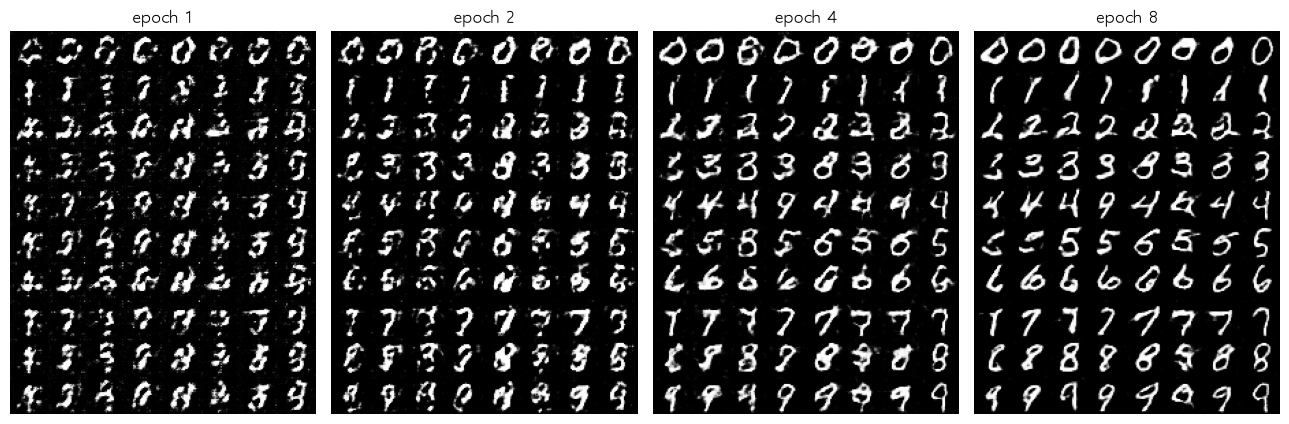

In [9]:
# [수업 재현 D2-3] 판별자에 라벨 있는 cGAN을 8 epoch · 고정 노이즈 격자 1 · 2 · 4 · 8 epoch
G_lab, log_lab = train_cgan(CondD, 8, keep=(1, 2, 4, 8))  # 라벨 있음 (수업 오늘 모델)
for e in (1, 2, 4, 8):                                    # 격자를 남긴 epoch
    print(f"epoch {e} · 마지막 묶음 손실 판별자 {log_lab['d'][e - 1]:.3f}"  # 두 손실
          f" · 생성자 {log_lab['g'][e - 1]:.3f}")
fig, ax = plt.subplots(1, 4, figsize=(13, 4.6))           # 격자 4장
for a, e in zip(ax, (1, 2, 4, 8)):                        # epoch마다
    a.imshow(grid(log_lab["grid"][e], 10), cmap="gray")   # 줄 = 라벨 0 ~ 9 · 열 = 같은 노이즈
    a.set_title(f"epoch {e}")                             # 칸 제목
    a.axis("off")                                         # 축 숨김
plt.tight_layout()                                        # 간격 정리
plt.show()                                                # 그림 표시

**결과** · 예측 정답은 작음 (2.669 → 1.666) — 손실이 내려갔다고 좋아진 것도, 올랐다고 나빠진 것도 아님 · 그림은 epoch 1부터 줄마다 요청한 숫자

- `epoch 1 · 마지막 묶음 손실 판별자 0.780 · 생성자 2.197` — 1 epoch만에 줄마다 숫자 모양 (DCGAN 생성자 + 라벨)
- `epoch 4 · 마지막 묶음 손실 판별자 0.578 · 생성자 2.669` — 생성자 손실이 가장 큰 무렵
- `epoch 8 · 마지막 묶음 손실 판별자 0.796 · 생성자 1.666` — 수업 1 epoch 값(0.727 · 1.480)과 같은 범위 · 흔들림

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">손실 기록 (마지막 묶음)</td>
<td style="text-align: left;">묶음 하나의 값이라 흔들림 · 품질을 직접 말하지 않음</td>
<td style="text-align: left;">학습이 터지지 않는지 확인</td>
</tr>
<tr>
<td style="text-align: left;">고정 노이즈 + 고정 라벨 격자</td>
<td style="text-align: left;">같은 입력의 epoch별 변화 · 줄 = 라벨이라 지정이 되는지 눈으로</td>
<td style="text-align: left;">epoch마다 저장해 나란히 비교</td>
</tr>
</tbody>
</table>

> ⚠️ **주의**
>
> - 손실 기록은 epoch 평균이 아니라 마지막 묶음 하나의 값 (수업과 같은 방식)
> - 생성모델-1 2-4의 epoch 평균과 숫자를 바로 비교하지 않음

> ✅ **한 줄 정리** · cGAN도 손실 숫자는 묶음마다 흔들려 품질을 말하지 못하므로, 고정 노이즈 · 고정 라벨 격자를 epoch마다 남겨 줄마다 요청한 숫자가 나오는지 본다.

**딥러닝 코드에서는**

- epoch마다 `log['grid'][epoch]`을 PNG로 저장하는 습관 → 미션 체크 카드의 '고정 노이즈 + 고정 라벨로 에폭마다 같은 격자'

### 2-4. `A` 판별자만 라벨 없음으로 바꾸면 · `train_cgan(PlainD, 8)` · `torch.pdist` <sub>수업 Day02 D2-2 · 코드 재현</sub>

> 🎯 **생성자만 라벨을 받고 판별자는 라벨을 받지 않으면, 요청한 숫자가 나오는가? 생성자는 라벨을 무시하는가?**

💡 **쉽게 말하면**

- 판별자 하나만 바꾸고 나머지(생성자 · 학습률 · 8 epoch · seed · 고정 격자)는 같게 함.
- 라벨 없는 판별자는 '진짜 같은 숫자인가'만 봐서, 생성자는 라벨마다 **다른 그림**을 내도 **요청한 숫자와 맞출 이유**가 없음.

**실행 흐름**

1. train_cgan(PlainD, 8)
2. 두 모델의 epoch 8 격자 나란히
3. 같은 노이즈 · 다른 라벨 사이 평균 거리

**먼저 예측** · 판별자에 라벨이 없으면 같은 노이즈 · 다른 라벨의 그림끼리 거리는 0(라벨 무시)에 가까울까? — 답은 코드 실행 결과 아래에

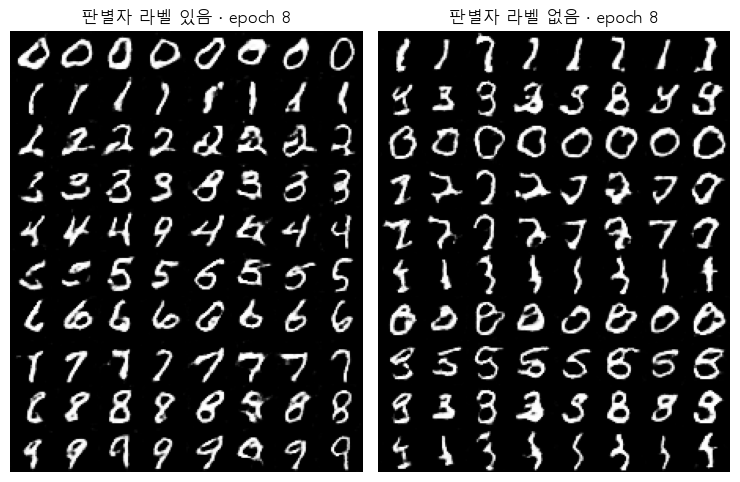

판별자 라벨 있음 · 같은 노이즈 · 다른 라벨 사이 평균 거리 17.55
판별자 라벨 없음 · 같은 노이즈 · 다른 라벨 사이 평균 거리 18.15


In [10]:
# [수업 재현 D2-2] 판별자만 라벨 없음으로 바꾸고 나머지는 같게 8 epoch → 같은 고정 노이즈 격자
G_nol, log_nol = train_cgan(PlainD, 8, keep=(8,))  # 생성자 · 학습률 · epoch · seed 같음
fig, ax = plt.subplots(1, 2, figsize=(7.5, 4.8))                       # 두 격자 나란히
pair = [("판별자 라벨 있음", log_lab), ("판별자 라벨 없음", log_nol)]  # 같은 epoch 8 격자
for a, (name, log) in zip(ax, pair):                                   # 왼쪽 · 오른쪽
    a.imshow(grid(log["grid"][8], 10), cmap="gray")                    # 줄 = 요청한 라벨 0 ~ 9
    a.set_title(f"{name} · epoch 8")                                   # 칸 제목
    a.axis("off")                                                      # 축 숨김
plt.tight_layout()                                                     # 간격 정리
plt.show()                                                             # 그림 표시
with torch.no_grad():  # 같은 노이즈 · 라벨만 바꾸면 그림이 바뀌나 (생성자가 라벨을 무시했나)
    for name, G in [("라벨 있음", G_lab), ("라벨 없음", G_nol)]:       # 두 생성자
        img = G(FIX_Z.to(device), FIX_Y.to(device)).view(10, 8, -1)    # 줄 = 라벨 · 열 = 노이즈
        gap = sum(torch.pdist(img[:, j]).mean().item() for j in range(8)) / 8  # 같은 열 안 줄끼리
        # 0이면 라벨 무시
        print(f"판별자 {name} · 같은 노이즈 · 다른 라벨 사이 평균 거리 {gap:.2f}")

**결과** · 예측 정답은 아님 — 18.15로 라벨 있음(17.55)과 비슷 · 라벨마다 다른 그림을 내지만 요청한 숫자가 아님

- `판별자 라벨 있음 · 같은 노이즈 · 다른 라벨 사이 평균 거리 17.55` — 줄(라벨)마다 다른 숫자
- `판별자 라벨 없음 · 같은 노이즈 · 다른 라벨 사이 평균 거리 18.15` — 생성자는 라벨을 무시하지 않음 · 그림에서 0 줄은 1, 2 줄은 0처럼 다른 숫자에 묶인 줄과 섞인 줄

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">판별자 라벨 있음</td>
<td style="text-align: left;">줄마다 요청한 숫자</td>
<td style="text-align: left;">요청한 숫자를 지정해야 할 때 (cGAN)</td>
</tr>
<tr>
<td style="text-align: left;">판별자 라벨 없음</td>
<td style="text-align: left;">같은 노이즈라도 라벨마다 다른 그림 · 다만 요청한 숫자와 맞지 않음</td>
<td style="text-align: left;">비교 실험 (생성자만 라벨을 받으면 부족함을 보임)</td>
</tr>
</tbody>
</table>

> ⚠️ **주의**
>
> - 격자에서 '이 줄은 대부분 1' 같은 판단은 눈 · 80장 기준 · 3-1
> - 3-3에서 점검한 분류기
> - 5,000장으로 다시 확인
> - 한 번 학습한 결과 (5장에서 seed를 바꿔 다시)

> ✅ **한 줄 정리** · 판별자에 라벨이 없으면 생성자는 라벨마다 다른 그림을 내지만 요청한 숫자와 맞추지 못하므로, 판별자에도 라벨을 넣어야 한다.

**딥러닝 코드에서는**

- 통제 비교의 기본형
- 바꾼 곳 하나(판별자) · 나머지 같음
- 같은 고정 격자
- 같은 측정 (4-1 · 5장 · 미션의 첫 실험)

---
## 3. 잘 만들었다는 근거 · 생성 평가

**수업 Day02 D2-2 · D2-4 + 실습 FID**

> **이 장의 흐름**
>
> - 2장 격자는 눈으로 본 것뿐
> - 확인할 세 가지(① 숫자처럼 보이나 ② 서로 다른 숫자가 나오나 ③ 원하는 숫자를 지정할 수 있나)를 숫자로 잼.
> - 측정마다 답을 아는 입력으로 먼저 점검(생성모델-1 3-1 순서 그대로).

**파이프라인 위치** · 평가 — 도구 점검 → 베끼기 · 다양성 · 일치율 · 혼동 행렬 → 꼼수 점검 → FID

### 3-1. `A` 세는 도구부터 점검 · 일치율 · `match(x, y)` · `답을 아는 입력` <sub>수업 Day02 D2-2 · 코드 재현</sub>

> 🎯 **숫자 분류기로 '요청한 숫자가 나왔는지'를 재기 전에 무엇을 점검하며, 점검을 통과하면 두 cGAN은 어떻게 나오는가?**

💡 **쉽게 말하면**

- 생성모델-1 3-1에서는 같은 분류기가 무작위 사진에도 '8'을 붙여 **숫자 종류 세기** 용도로는 실패했음.
- 이번 용도는 **요청한 라벨과 맞는지** — 답을 아는 입력 넷(진짜 + 맞는 라벨 · 같은 사진 반복 · 무작위 · 섞은 라벨)으로 다시 점검.

**실행 흐름**

1. 분류기 3 epoch 학습
2. read · match 정의
3. 점검 입력 네 가지 (라벨마다 100개)
4. 시험 1만 장 정확도
5. 두 cGAN 격자 80장 일치율

**먼저 예측** · 무작위 사진에 라벨 0 ~ 9를 100개씩 붙여 물으면 일치율은 얼마 근처일까? — 답은 코드 실행 결과 아래에

In [11]:
# [수업 재현 D2-2] 세는 도구부터 점검: 숫자 분류기의 '요청한 라벨과 맞는지' 용도
set_seed()                                         # 분류기 초기값 고정
clf = nn.Sequential(                               # 작은 CNN 분류기 (생성모델-1 3-1과 같은 구조)
    nn.Conv2d(1, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
    nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
    nn.Flatten(), nn.Linear(32 * 7 * 7, 10)).to(device)
opt = torch.optim.Adam(clf.parameters(), lr=1e-3)  # 분류기 옵티마이저
gen = torch.Generator().manual_seed(SEED)          # 섞는 순서 고정
for epoch in range(3):                             # 3 epoch
    perm = torch.randperm(len(X), generator=gen)   # 섞은 번호
    for i in range(0, len(X), 256):                # 묶음 256장씩
        b = perm[i:i + 256]                        # 이번 묶음 번호
        loss = F.cross_entropy(clf(X[b].to(device)), Y[b].to(device))  # 숫자 분류 손실
        opt.zero_grad()                            # 기울기 비우기
        loss.backward()                            # 기울기 계산
        opt.step()                                 # 분류기 고침
clf.eval()                                         # 평가 모드


def read(x):               # 사진 묶음 → 분류기가 본 숫자
    with torch.no_grad():  # 평가만
        return torch.cat([clf(x[i:i + 1000].to(device)).argmax(1).cpu()  # 1000장씩
                          for i in range(0, len(x), 1000)])


def match(x, y):  # 일치율 = 분류기가 본 숫자가 요청한 라벨과 같은 비율
    return (read(x) == y).float().mean().item()  # 1이면 모두 맞음 · 0.1 = 아무거나 골라 맞을 확률


lab = torch.arange(10).repeat_interleave(100)  # 점검용 라벨 1000개 (0 100개 · 1 100개 …)
gen = torch.Generator().manual_seed(SEED)                     # 점검 입력 고정
real = torch.cat([X_te[Y_te == d][:100] for d in range(10)])  # 진짜 사진 숫자마다 100장 (lab 순서)
checks = {"진짜 사진 + 맞는 라벨": (real, lab),               # 높아야 함
          "같은 사진 1000번": (X_te[:1].repeat(1000, 1, 1, 1), lab),  # 0.1 근처여야 함
          "무작위 사진": (torch.rand(1000, 1, 28, 28, generator=gen) * 2 - 1, lab),  # 0.1 근처
          "진짜 사진 + 섞은 라벨": (real, lab[torch.randperm(1000, generator=gen)])}  # 0.1 근처
print(f"시험 사진 1만 장 정확도 {match(X_te, Y_te):.3f}")     # 도구 자체의 정확도
for name, (x, y) in checks.items():                           # 답을 아는 입력 네 가지
    print(f"일치율 {match(x, y):.3f} · {name}")               # 기대와 맞나
for name, G in [("있음", G_lab), ("없음", G_nol)]:            # 2-4의 두 격자 80장
    with torch.no_grad():                                     # 생성만
        print(f"판별자에 라벨 {name} · 격자 80장 일치율",     # 요청한 숫자가 나왔나
              f"{match(G(FIX_Z.to(device), FIX_Y.to(device)).cpu(), FIX_Y):.3f}")

시험 사진 1만 장 정확도 0.983
일치율 0.979 · 진짜 사진 + 맞는 라벨
일치율 0.100 · 같은 사진 1000번
일치율 0.112 · 무작위 사진
일치율 0.118 · 진짜 사진 + 섞은 라벨
판별자에 라벨 있음 · 격자 80장 일치율 0.938
판별자에 라벨 없음 · 격자 80장 일치율 0.087


**결과** · 예측 정답은 0.1 근처 (0.112) — 분류기가 무엇으로 읽든 라벨이 고르게 섞여 있어 맞을 확률이 1/10

- `시험 사진 1만 장 정확도 0.983` — 도구 자체 (수업 0.989)
- `일치율 0.979 · 진짜 사진 + 맞는 라벨` — 높아야 함 → 통과
- `일치율 0.100 · 같은 사진 1000번` — 0.1 근처여야 함 → 통과
- `일치율 0.112 · 무작위 사진` — 0.1 근처 → 통과 (숫자 이름을 붙여도 일치율은 속지 않음)
- `일치율 0.118 · 진짜 사진 + 섞은 라벨` — 0.1 근처 → 통과
- `판별자에 라벨 있음 · 격자 80장 일치율 0.938` — 줄마다 요청한 숫자
- `판별자에 라벨 없음 · 격자 80장 일치율 0.087` — 0.1 근처 = 아무거나 고른 것과 비슷

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">진짜 사진 + 맞는 라벨</td>
<td style="text-align: left;">높아야 함</td>
<td style="text-align: left;">도구가 제대로 읽는지</td>
</tr>
<tr>
<td style="text-align: left;">같은 사진 반복 · 무작위 사진 · 섞은 라벨</td>
<td style="text-align: left;">셋 다 0.1 근처여야 함 (아무거나 골라 맞을 확률)</td>
<td style="text-align: left;">도구가 '요청과 맞는지'에 속지 않는지</td>
</tr>
<tr>
<td style="text-align: left;">생성모델-1 3-1 점검 (숫자 종류 세기)</td>
<td style="text-align: left;">무작위 사진도 높은 확신으로 '8' → 그 용도로는 실패</td>
<td style="text-align: left;">같은 도구라도 용도마다 따로 점검</td>
</tr>
</tbody>
</table>

> ⚠️ **주의**
>
> - 점검 입력의 라벨이 고르지 않으면(예: 모두 7) 무작위 사진도 우연히 높게 나올 수 있음
> - 라벨을 숫자마다 같은 수로

> ✅ **한 줄 정리** · 같은 분류기라도 용도마다 답을 아는 입력으로 다시 점검하며, '요청한 라벨과 맞는지' 용도로는 통과해 두 cGAN의 일치율 차이(0.938 vs 0.087)를 믿을 수 있다.

**딥러닝 코드에서는**

- 평가용 분류기는 학습 데이터와 따로 저장해 두고 모든 실험에 같은 것을 씀
- 미션(FashionMNIST)에서는 그 데이터로 분류기를 새로 학습 · 점검

### 3-2. `A` ① 숫자 모양 · 베끼기 점검 · `nearest(x)` · `torch.cdist` <sub>수업 Day02 D2-4 · 코드 재현</sub>

> 🎯 **생성 사진이 학습 사진을 그대로 베낀 것은 아닌지 어떻게 점검하며, 이 점검으로 말할 수 없는 것은?**

💡 **쉽게 말하면**

- 눈으로 숫자처럼 보여도 **학습 사진을 거의 그대로 베꼈을** 수 있음.
- 생성 사진마다 학습 6만 장 중 **가장 가까운 한 장**까지 거리(784칸 픽셀 거리)를 재고, 학습에 안 쓴 진짜 시험 사진과 비교.

**실행 흐름**

1. make: 라벨마다 500장씩 5,000장 (두 모델)
2. nearest 정의 (250장씩 cdist)
3. 1,000장씩 네 묶음 거리 평균 · 최소

**먼저 예측** · 학습 사진을 그대로 넣으면 거리는 0이 나올 것이다. 학습 사진을 2칸만 옆으로 옮기면? — 답은 코드 실행 결과 아래에

In [12]:
# [수업 재현 D2-4] 평가용 생성 5,000장 · ① 베끼기 점검 (가장 가까운 학습 사진)
def make(G, n_per=500, seed=SEED, zd=ZD):           # 라벨 0 ~ 9마다 n_per장 (zd = 노이즈 칸 수)
    yy = torch.arange(10).repeat_interleave(n_per)  # 요청한 라벨
    zz = torch.randn(len(yy), zd, generator=torch.Generator().manual_seed(seed))  # 노이즈 고정
    with torch.no_grad():                           # 생성만
        xx = torch.cat([G(zz[i:i + 1000].to(device), yy[i:i + 1000].to(device)).cpu()  # 1000장씩
                        for i in range(0, len(yy), 1000)])
    return xx, yy                                   # 사진 · 요청한 라벨


GEN = {"있음": make(G_lab), "없음": make(G_nol)}                      # 판별자 라벨 있음 · 없음
print("생성 사진 · 판별자에 라벨 있음", tuple(GEN["있음"][0].shape),  # (5000, 1, 28, 28)
      "· 라벨 없음", tuple(GEN["없음"][0].shape))
Xflat = X.view(len(X), -1).to(device)                                 # 학습 사진 6만 장 (784칸)


def nearest(x):  # 사진마다 학습 6만 장 중 가장 가까운 한 장까지의 거리 (-1 ~ 1 픽셀 거리)
    x = x.reshape(len(x), -1).to(device)                                    # 784칸으로 펼침
    return torch.cat([torch.cdist(x[i:i + 250], Xflat).min(1).values.cpu()  # 250장씩
                      for i in range(0, len(x), 250)])


sub = slice(0, 5000, 5)                                                # 1,000장만 (라벨마다 100장)
rows = {"생성 (판별자 라벨 있음)": GEN["있음"][0][sub], "진짜 시험 사진": X_te[:1000],  # 기준 비교
        "점검 · 학습 사진 그대로": X[:1000],                           # 0이어야 함
        "점검 · 학습 사진 2칸 옮김": torch.roll(X[:1000], 2, dims=3)}  # 베낀 것인데 옮김
for name, x in rows.items():                                           # 네 묶음
    d = nearest(x)                                                     # 1,000개 거리
    print(f"가장 가까운 학습 사진까지 · {name}",                       # 평균 · 최소
          f"평균 {d.mean():.2f} (최소 {d.min():.2f})")

생성 사진 · 판별자에 라벨 있음 (5000, 1, 28, 28) · 라벨 없음 (5000, 1, 28, 28)
가장 가까운 학습 사진까지 · 생성 (판별자 라벨 있음) 평균 10.00 (최소 2.88)
가장 가까운 학습 사진까지 · 진짜 시험 사진 평균 8.48 (최소 2.20)


가장 가까운 학습 사진까지 · 점검 · 학습 사진 그대로 평균 0.02 (최소 0.00)
가장 가까운 학습 사진까지 · 점검 · 학습 사진 2칸 옮김 평균 12.16 (최소 6.90)


**결과** · 예측 정답은 12.16 — 생성 사진(10.00)이나 진짜 시험 사진(8.48)보다 오히려 큼 → 픽셀 거리는 '조금 옮긴 베끼기'를 못 잡음

- `생성 사진 · 판별자에 라벨 있음 (5000, 1, 28, 28) · 라벨 없음 (5000, 1, 28, 28)` — 라벨마다 500장 (3 ~ 5장 공통 평가 재료)
- `생성 (판별자 라벨 있음) 평균 10.00 (최소 2.88)` — 가장 가까운 학습 사진과도 거리가 있음
- `진짜 시험 사진 평균 8.48 (최소 2.20)` — 학습에 안 쓴 진짜도 거리 8 ~ 10 → 생성과 비슷한 범위
- `점검 · 학습 사진 그대로 평균 0.02 (최소 0.00)` — 그대로 베끼면 0 → 이 점검으로 잡힘 (0.02는 MNIST 안 중복 사진)
- `점검 · 학습 사진 2칸 옮김 평균 12.16 (최소 6.90)` — 옮긴 베끼기는 못 잡음

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">가장 가까운 학습 사진 거리</td>
<td style="text-align: left;">그대로 베낀 사진은 0으로 잡음</td>
<td style="text-align: left;">베끼기 점검 (외우지 않았다는 증명은 아님)</td>
</tr>
<tr>
<td style="text-align: left;">진짜 시험 사진의 같은 거리</td>
<td style="text-align: left;">학습에 안 쓴 진짜도 거리가 있음 → 비교 기준</td>
<td style="text-align: left;">생성 거리가 이상하게 작은지 판단</td>
</tr>
<tr>
<td style="text-align: left;">2칸 옮긴 베끼기</td>
<td style="text-align: left;">픽셀 거리가 커져 못 잡음</td>
<td style="text-align: left;">특징 공간 거리 등 다른 방법이 필요함을 기억</td>
</tr>
</tbody>
</table>

> ⚠️ **주의**
>
> - 거리는 -1 ~ 1 범위 784칸의 픽셀 거리
> - 0 ~ 1로 재면 값이 절반 · 다른 범위
> - 다른 장 수의 값과 바로 비교하지 않음

> ✅ **한 줄 정리** · 가장 가까운 학습 사진 거리는 그대로 베낀 사진은 잡지만 조금 옮긴 베끼기는 못 잡으므로, '그대로 베낀 사진은 없었다'까지만 말할 수 있다.

**딥러닝 코드에서는**

- 큰 데이터에서는 픽셀 대신 특징(분류기 · Inception) 공간에서 가장 가까운 이웃을 찾음
- 그래도 '외우지 않았다는 증명'은 아님

### 3-3. `A` ② 라벨 안 다양성 · ③ 일치율 · 혼동 행렬 · `diversity` · `confusion` <sub>수업 Day02 D2-4 · 코드 재현</sub>

> 🎯 **같은 라벨 안에서 서로 다른 숫자를 만드는지, 요청한 숫자를 지정할 수 있는지를 각각 어떻게 재는가?**

💡 **쉽게 말하면**

- ② 같은 라벨 사진 100장끼리 **모든 짝의 거리 평균** (한 장 반복이면 0).
- 클수록 좋은 게 아니라 **진짜와 비슷한지** 봄.
- ③ 요청한 숫자(줄) × 분류기가 본 숫자(칸) 표 = **혼동 행렬**, 대각선 평균 = 일치율.

**실행 흐름**

1. diversity 정의
2. 진짜 · 두 cGAN · 점검 둘의 다양성
3. confusion 정의
4. 진짜 · 두 cGAN 일치율
5. 라벨 없음이 2를 요청받았을 때
6. 혼동 행렬 그림

**먼저 예측** · 무작위 사진의 다양성은 진짜 시험 사진보다 클까 작을까? — 답은 코드 실행 결과 아래에

In [13]:
# [수업 재현 D2-4] ② 같은 라벨 안의 다양성 · ③ 원하는 숫자 지정 (일치율 · 혼동 행렬)
def diversity(x, y, n=100):  # 라벨마다 n장끼리 모든 짝의 거리 평균 → 라벨 평균
    return sum(torch.pdist(x[y == d][:n].reshape(n, -1)).mean().item()  # 라벨 d 안의 평균 거리
               for d in range(10)) / 10


lab5 = torch.arange(10).repeat_interleave(500)                 # 점검용 라벨 5,000개
real5 = torch.cat([X_te[Y_te == d][:500] for d in range(10)])  # 진짜 시험 사진 라벨마다 500장
gen = torch.Generator().manual_seed(SEED)                      # 무작위 사진 고정
div_rows = {"진짜 시험 사진": real5, "cGAN 라벨 있음": GEN["있음"][0],  # 비교 대상
            "cGAN 라벨 없음": GEN["없음"][0],
            "점검: 라벨마다 한 장 반복": real5[::500].repeat_interleave(500, 0),  # 0이어야 함
            "점검: 무작위 사진": torch.rand(5000, 1, 28, 28, generator=gen) * 2 - 1}  # 가장 큼
for name, x in div_rows.items():                               # 다섯 묶음
    print(f"다양성 {diversity(x, lab5):5.2f} · {name}")        # 진짜와 비슷한지를 봄


def confusion(x, y):  # 줄 = 요청한 숫자 · 칸 = 분류기가 본 숫자 · 값 = 그 줄에서의 비율
    m = torch.zeros(10, 10)                                          # 10 × 10 표
    m.index_put_((y, read(x)), torch.ones(len(y)), accumulate=True)  # (요청, 본 것) 칸에 1씩
    return m / m.sum(1, keepdim=True)                                # 줄마다 비율


print(f"일치율 {match(X_te, Y_te):.3f} · 진짜 시험 사진 1만 장")     # 기준
CM = {}                                                              # 두 모델의 혼동 행렬
for name in ("있음", "없음"):                                        # 판별자 라벨 있음 · 없음
    CM[name] = confusion(*GEN[name])                                 # 5,000장
    print(f"일치율 {CM[name].diag().mean().item():.3f} · cGAN 라벨 {name} 5,000장")  # 대각선 평균
seen = read(GEN["없음"][0][lab5 == 2]).bincount(minlength=10)        # 라벨 없음 · 2를 요청한 500장
print("라벨 없음 · 2를 요청한 500장 중 분류기가 가장 많이 본 숫자",  # 어느 숫자로 묶였나
      f"{seen.argmax().item()} · {seen.max().item()}장")

다양성 17.53 · 진짜 시험 사진
다양성 17.55 · cGAN 라벨 있음


다양성 16.43 · cGAN 라벨 없음
다양성  0.00 · 점검: 라벨마다 한 장 반복
다양성 22.85 · 점검: 무작위 사진


일치율 0.983 · 진짜 시험 사진 1만 장
일치율 0.967 · cGAN 라벨 있음 5,000장
일치율 0.051 · cGAN 라벨 없음 5,000장
라벨 없음 · 2를 요청한 500장 중 분류기가 가장 많이 본 숫자 0 · 493장


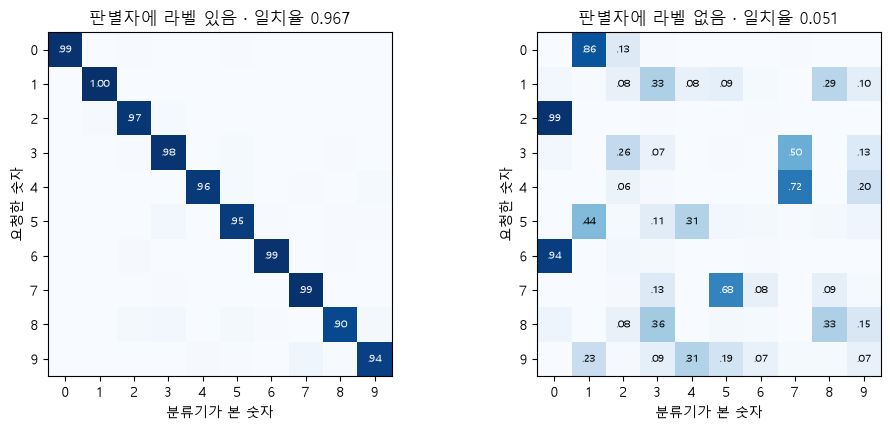

In [14]:
# [수업 재현 D2-4] 혼동 행렬 두 장 (줄 = 요청한 숫자 · 칸 = 분류기가 본 숫자)
fig, ax = plt.subplots(1, 2, figsize=(10, 4.4))       # 두 모델 나란히
for a, name in zip(ax, ("있음", "없음")):             # 판별자 라벨 있음 · 없음
    a.imshow(CM[name], cmap="Blues", vmin=0, vmax=1)  # 진할수록 비율이 큼
    for r in range(10):                               # 줄마다
        for c in range(10):                           # 칸마다
            if CM[name][r, c] >= 0.05:                # 5% 이상만 숫자로
                a.text(c, r, f"{CM[name][r, c]:.2f}".lstrip("0"), ha="center", va="center",  # 칸 값
                       fontsize=7, color="white" if CM[name][r, c] > 0.5 else "black")
    a.set_title(f"판별자에 라벨 {name} · 일치율 {CM[name].diag().mean().item():.3f}")  # 칸 제목
    a.set_xlabel("분류기가 본 숫자")                  # 칸
    a.set_ylabel("요청한 숫자")                       # 줄
    a.set_xticks(range(10))                           # 0 ~ 9
    a.set_yticks(range(10))                           # 0 ~ 9
plt.tight_layout()                                    # 간격 정리
plt.show()                                            # 그림 표시

**결과** · 예측 정답은 큼 (22.85 vs 17.53) — 다양성이 클수록 좋은 것이 아님

- `다양성 17.53 · 진짜 시험 사진` — 기준
- `다양성 17.55 · cGAN 라벨 있음` — 진짜와 거의 같음
- `다양성 16.43 · cGAN 라벨 없음` — 조금 작음
- `다양성 0.00 · 점검: 라벨마다 한 장 반복` — 0 → 점검 통과
- `다양성 22.85 · 점검: 무작위 사진` — 가장 큼 → 클수록 좋은 것 아님
- `일치율 0.983 · 진짜 시험 사진 1만 장` — 기준
- `일치율 0.967 · cGAN 라벨 있음 5,000장` — 대각선이 진함
- `일치율 0.051 · cGAN 라벨 없음 5,000장` — 0.1보다도 낮음 = 요청과 다른 숫자에 묶임
- `라벨 없음 · 2를 요청한 500장 중 분류기가 가장 많이 본 숫자 0 · 493장` — 2를 달라면 0을 냄 (수업에서도 2 줄이 0)

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">라벨 안 다양성 (픽셀 거리 평균)</td>
<td style="text-align: left;">한 장 반복은 0 · 무작위가 가장 큼 → 클수록 좋은 것 아님</td>
<td style="text-align: left;">진짜 시험 사진 값과 비슷한지</td>
</tr>
<tr>
<td style="text-align: left;">일치율</td>
<td style="text-align: left;">요청한 라벨과 분류기가 본 숫자가 같은 비율 (0.1 = 아무거나)</td>
<td style="text-align: left;">③ 원하는 숫자를 지정할 수 있는지 한 숫자로</td>
</tr>
<tr>
<td style="text-align: left;">혼동 행렬</td>
<td style="text-align: left;">줄 = 요청 · 칸 = 본 숫자 · 어느 숫자가 어디로 갔는지</td>
<td style="text-align: left;">일치율이 낮을 때 원인 보기</td>
</tr>
</tbody>
</table>

> ⚠️ **주의**
>
> - 혼동 행렬은 분류기가 붙인 이름
> - 눈과 갈릴 수 있음 (수업의 5 줄)
> - 표는 격자 그림과 같이 봄

> ✅ **한 줄 정리** · 라벨 안 다양성은 진짜와 비슷한지를, 일치율과 혼동 행렬은 요청한 숫자를 지정할 수 있는지를 보여 주며, 판별자에 라벨이 없으면 일치율이 0.051로 떨어진다.

**딥러닝 코드에서는**

- 라벨별 다양성
- 일치율을 따로 보면 어느 라벨이 약한지 보임 (예: 8 줄 0.90)
- 미션의 클래스별 판정표

### 3-4. `B` 지표 하나로는 못 막는 꼼수 · `cheats` · `판정표` <sub>수업 Day02 D2-4 · 코드 재현</sub>

> 🎯 **일부러 만든 꼼수 네 가지를 세 측정(일치율 · 다양성 · 가장 가까운 거리)은 각각 잡아내는가?**

💡 **쉽게 말하면**

- 점수를 높게 받는 **가짜 정답**을 일부러 만들어 넣어 봄.
- 측정 하나는 반드시 어딘가 속지만, **여러 측정을 같이 보면** 대부분 잡힘.
- 그래도 못 막는 꼼수가 남음.

**실행 흐름**

1. 학습 사진 라벨마다 500장
2. 꼼수 넷(한 장 반복 · 평균 사진 반복 · 그대로 복사 · 2칸 옮김)
3. 세 측정 표
4. 진짜 시험 사진 기준 줄

**먼저 예측** · 라벨마다 한 장만 반복한 5,000장의 일치율은? — 답은 코드 실행 결과 아래에

In [15]:
# [수업 재현 D2-4] 지표 하나로는 못 막는 꼼수 네 가지를 일부러 만들어 세 측정에 넣기
tr5 = torch.cat([X[Y == d][:500] for d in range(10)])              # 학습 사진 라벨마다 500장
cheats = {"라벨마다 한 장만 반복": tr5[::500].repeat_interleave(500, 0),  # 같은 그림 500번
          "라벨별 평균 사진 반복": torch.stack([X[Y == d].mean(0) for d in range(10)])  # 흐린 평균
          .repeat_interleave(500, 0),
          "학습 사진 그대로 복사": tr5,                            # 외운 것
          "학습 사진 2칸 옮김": torch.roll(tr5, 2, dims=3)}        # 외운 것을 살짝 옮김
print(f"{'꼼수':14} | 일치율 | 다양성 | 가장 가까운 거리")         # 표 머리
for name, x in cheats.items():                                     # 네 꼼수
    near = nearest(x[::5]).mean().item()                           # 1,000장만
    print(f"{name:14} | {match(x, lab5):6.3f}",                    # 일치율
          f"| {diversity(x, lab5):6.2f} | {near:6.2f}")
real_near = nearest(real5[::5]).mean().item()                      # 비교 기준: 진짜 시험 사진
print(f"{'기준: 진짜 시험 사진':14} | {match(real5, lab5):6.3f}",  # 같은 세 측정
      f"| {diversity(real5, lab5):6.2f} | {real_near:6.2f}")

꼼수             | 일치율 | 다양성 | 가장 가까운 거리
라벨마다 한 장만 반복   |  1.000 |   0.00 |   0.02
라벨별 평균 사진 반복   |  1.000 |   0.00 |   9.27


학습 사진 그대로 복사   |  0.984 |  17.68 |   0.02
학습 사진 2칸 옮김    |  0.948 |  17.68 |  12.29
기준: 진짜 시험 사진   |  0.975 |  17.53 |   8.58


**결과** · 예측 정답은 1.000 — 만점처럼 보임 · 다양성 0.00이 잡음

- `라벨마다 한 장만 반복` — 일치율 1.000 · 다양성 0.00 · 거리 0.02 (다양성 · 거리가 잡음)
- `라벨별 평균 사진 반복` — 일치율 1.000 · 다양성 0.00 (다양성이 잡음)
- `학습 사진 그대로 복사` — 일치율 0.984 · 다양성 17.68로 진짜 같음 · 거리 0.02가 잡음
- `학습 사진 2칸 옮김` — 일치율 0.948 · 다양성 17.68 · 거리 12.29 → 세 측정 모두 못 잡음
- `기준: 진짜 시험 사진` — 일치율 0.975 · 다양성 17.53 · 거리 8.58

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">한 장 반복 · 평균 사진</td>
<td style="text-align: left;">일치율 1.0 (만점처럼 보임)</td>
<td style="text-align: left;">다양성 0이 잡음</td>
</tr>
<tr>
<td style="text-align: left;">학습 사진 그대로 복사</td>
<td style="text-align: left;">일치율 · 다양성이 진짜와 같음</td>
<td style="text-align: left;">가장 가까운 거리 0이 잡음</td>
</tr>
<tr>
<td style="text-align: left;">학습 사진 2칸 옮김</td>
<td style="text-align: left;">세 측정 모두 진짜와 비슷하게 보임</td>
<td style="text-align: left;">이 판정표로도 못 막음 → 한계로 적어 둠</td>
</tr>
</tbody>
</table>

> ⚠️ **주의**
>
> - 판정표가 통과해도 '외우지 않았다'를 증명한 것은 아님
> - 보고서에는 무엇을 점검했고 무엇을 못 막는지 함께 적기

> ✅ **한 줄 정리** · 측정마다 속는 꼼수가 있어 판정표로 같이 봐야 하며, 2칸 옮긴 복사처럼 판정표로도 못 막는 것이 남는다.

**딥러닝 코드에서는**

- 평가 코드를 만들면 꼼수 입력으로 먼저 돌려 보는 습관 (단위 테스트처럼)
- 미션 평가 계획의 '지표를 어떻게 먼저 점검할지'

### 3-5. `A` FID · IS · `inception_v3` · `fid(fa, fb)` <sub>수업 Day02 D2-4 · cGAN 실습 9 · 실습 코드</sub>

> 🎯 **FID는 무엇을 재며, 두 cGAN의 FID는 일치율과 같은 이야기를 하는가?**

💡 **쉽게 말하면**

- FID는 큰 분류 모델(InceptionV3)로 사진마다 **특징 2,048개**를 뽑고, 진짜 묶음과 생성 묶음의 **가운데(평균) · 퍼짐(공분산)** 차이를 숫자 하나로 냄.
- 작을수록 비슷.
- 같은 분포 두 묶음끼리 잰 **기준선**이 바닥값.
- 전체 묶음 비교라 **요청한 숫자와 맞는지는 안 봄**.

<img src="images/gen2_fid.png" alt="FID 절차: 사진 → Inception 특징 2,048개 → 가운데 · 퍼짐 → 거리" width="912">

**실행 흐름**

1. InceptionV3 불러와 fc 떼기
2. features (3겹 · 299 · ImageNet 규격)
3. fid 정의
4. 기준 = 시험 5,000장
5. 기준선(시험 뒤 5,000장)
6. 두 cGAN · 점검 둘
7. 일치율과 나란히

**먼저 예측** · 두 cGAN의 FID 차이는 일치율 차이(0.967 vs 0.051)만큼 클까? — 답은 코드 실행 결과 아래에

In [16]:
# [실습 반영] FID: InceptionV3(ImageNet 학습)의 특징 2,048개로 두 묶음의 가운데 · 퍼짐 차이
from torchvision.models import Inception_V3_Weights, inception_v3  # 사전학습 분류 모델

W_INC = Inception_V3_Weights.IMAGENET1K_V1                # ImageNet으로 학습한 가중치
inc = inception_v3(weights=W_INC, transform_input=False)  # 처음 1번 약 104MB 내려받음
inc.fc = nn.Identity()                                    # 마지막 분류층을 떼어 특징 2,048개를 꺼냄
inc = inc.eval().to(device)                               # 평가 모드
MEAN = torch.tensor([0.485, 0.456, 0.406], device=device).view(1, 3, 1, 1)  # ImageNet 평균
STD = torch.tensor([0.229, 0.224, 0.225], device=device).view(1, 3, 1, 1)  # ImageNet 퍼짐


def features(x, bs=100):  # -1 ~ 1 흑백 → 0 ~ 1 → 세 겹 → 299 × 299 → 특징 2,048개
    out = []                                                  # 묶음별 특징
    with torch.no_grad():                                     # 평가만
        for i in range(0, len(x), bs):                        # 100장씩
            v = (x[i:i + bs].to(device) + 1) / 2              # 0 ~ 1
            # 3채널 · 키우기
            v = F.interpolate(v.repeat(1, 3, 1, 1), size=(299, 299), mode="bilinear",
                              align_corners=False)
            out.append(inc((v - MEAN) / STD).double().cpu())  # ImageNet 규격으로 맞춰 넣음
    return torch.cat(out).numpy()                             # (N, 2048)


def fid(fa, fb):  # 두 특징 묶음의 Fréchet 거리 (작을수록 비슷 · 0 = 가운데 · 퍼짐이 같음)
    mu_a, mu_b = fa.mean(0), fb.mean(0)                          # 가운데 (평균)
    ca, cb = np.cov(fa, rowvar=False), np.cov(fb, rowvar=False)  # 퍼짐 (공분산 2,048 × 2,048)
    # 특징 2,048개 중 거의 안 움직이는 칸이 있어 '특이 행렬' 경고가 남
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", scipy.linalg.LinAlgWarning)  # 값은 그대로 · 경고만 숨김
        root = scipy.linalg.sqrtm(ca @ cb).real                  # 행렬 제곱근 (작은 허수부는 버림)
    # 가운데 차이 + 퍼짐 차이
    return float(((mu_a - mu_b) ** 2).sum() + np.trace(ca + cb - 2 * root))


F_REF = features(X_te[:5000])                 # 기준 묶음 = MNIST 시험 사진 5,000장
print("특징 모양", F_REF.shape)               # (5000, 2048)
FID_BASE = fid(F_REF, features(X_te[5000:]))  # 같은 분포 두 묶음 → 내려갈 수 있는 바닥값
print(f"FID {FID_BASE:6.2f} · 기준선:",       # 바닥값
      "진짜 vs 진짜 (시험 앞 · 뒤 5,000장)")

특징 모양 (5000, 2048)


FID   8.37 · 기준선: 진짜 vs 진짜 (시험 앞 · 뒤 5,000장)


In [17]:
# [수업 재현 D2-4] 두 cGAN · 점검 입력 두 가지의 FID (기준 = 시험 사진 5,000장)
gen = torch.Generator().manual_seed(SEED)                               # 무작위 사진 고정
fid_rows = {"cGAN 라벨 있음": GEN["있음"][0], "cGAN 라벨 없음": GEN["없음"][0],  # 두 모델
            # 크게 나와야 함
            "점검: 무작위 사진": torch.rand(5000, 1, 28, 28, generator=gen) * 2 - 1,
            "점검: 한 장 반복": X_te[5000:5001].repeat(5000, 1, 1, 1)}  # 크게 나와야 함
FID = {}                                                                # 결과 모음
for name, x in fid_rows.items():                                        # 네 묶음
    FID[name] = fid(F_REF, features(x))                                 # 5,000장씩
    print(f"FID {FID[name]:6.2f} · {name}")                             # 작을수록 진짜 묶음과 비슷
print("일치율과 나란히 · 라벨 있음", f"{CM['있음'].diag().mean().item():.3f}",  # FID는 가깝고
      "| 라벨 없음", f"{CM['없음'].diag().mean().item():.3f}")          # 일치율은 크게 다름

FID  21.54 · cGAN 라벨 있음


FID  26.65 · cGAN 라벨 없음


FID 493.30 · 점검: 무작위 사진


FID 174.52 · 점검: 한 장 반복
일치율과 나란히 · 라벨 있음 0.967 | 라벨 없음 0.051


**결과** · 예측 정답은 아님 — 21.54 vs 26.65로 가까움 (수업 21.5 vs 23.2)

- `특징 모양 (5000, 2048)` — 사진마다 특징 2,048개
- `FID 8.37 · 기준선: 진짜 vs 진짜 (시험 앞 · 뒤 5,000장)` — 이 설정에서 내려갈 수 있는 바닥 (실습 노트북은 학습 사진끼리 2.60)
- `FID 21.54 · cGAN 라벨 있음` — 기준선보다 큼
- `FID 26.65 · cGAN 라벨 없음` — 라벨 있음과 가까움
- `FID 493.30 · 점검: 무작위 사진` — 크게 나옴 → 점검 통과
- `FID 174.52 · 점검: 한 장 반복` — 퍼짐이 0 → 크게 나옴 → 통과
- `일치율과 나란히 · 라벨 있음 0.967 | 라벨 없음 0.051` — FID는 가까운데 일치율은 크게 다름 = FID는 조건을 못 봄

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">눈으로 보기 (격자)</td>
<td style="text-align: left;">가장 빠름 · 사람마다 갈림</td>
<td style="text-align: left;">학습 중 매 epoch</td>
</tr>
<tr>
<td style="text-align: left;">다양성 (라벨 안 거리)</td>
<td style="text-align: left;">한 장 반복 · 붕괴를 잡음 · 픽셀 거리라 옮긴 베끼기는 못 잡음</td>
<td style="text-align: left;">② 서로 다른 숫자인지</td>
</tr>
<tr>
<td style="text-align: left;">일치율 · 혼동 행렬</td>
<td style="text-align: left;">점검한 분류기 필요 · 조건(요청과 맞나)을 봄</td>
<td style="text-align: left;">③ 지정 (cGAN의 핵심)</td>
</tr>
<tr>
<td style="text-align: left;">FID</td>
<td style="text-align: left;">진짜 묶음과 특징 분포 차이 · 조건은 보지 않음 · 설정마다 값이 달라짐</td>
<td style="text-align: left;">같은 설정 안 상대 비교 · 보고서</td>
</tr>
<tr>
<td style="text-align: left;">IS (개념만)</td>
<td style="text-align: left;">한 장은 확신 · 전체는 고르게 · ImageNet 종류로 해석 · 진짜와 비교 안 함</td>
<td style="text-align: left;">자연 이미지 · 미션에서는 선택 사항</td>
</tr>
</tbody>
</table>

> ⚠️ **주의**
>
> - FID는 장 수 · 기준 묶음
> - 이미지 크기 조정
> - 모델에 따라 값이 바뀜
> - 다른 설정의 FID(실습 15.17 · 수업 21.5)와 숫자를 바로 비교하지 않음
> - 5,000장에 GPU로 1분 남짓

> ✅ **한 줄 정리** · FID는 진짜 묶음과의 특징 분포 차이를 재는 표준 지표지만 요청한 숫자와 맞는지는 보지 않으므로, cGAN은 일치율과 따로 같이 본다.

**딥러닝 코드에서는**

- `torchmetrics.image.fid.FrechetInceptionDistance`로도 계산 (같은 절차)
- IS는 진짜와 비교하지 않고 ImageNet 종류로 해석해 숫자
- 흑백에서는 의미가 약함 (미션에서 선택 사항)

---
## 4. 더 잘 만들기 · Diffusion · 요즘 모델

**수업 Day02 D2-5 ~ D2-7 + 실습 코드**

> **이 장의 흐름**
>
> - 3장에서 재는 방법을 갖춤
> - 결과가 마음에 안 들면 무엇을 바꾸고 어떻게 비교할까?
> - 손잡이 하나만 바꾼 비교 vs 여러 곳을 바꾼 비교(실습 노트북 설정)
> - 겨루지 않는 방법(Diffusion)과 요즘 모델의 세 축.

**파이프라인 위치** · 개선 — 손잡이 하나 → 같은 판정표 → 실험 기록 · 다음 방법 (Diffusion)

### 4-1. `A` 손잡이는 한 번에 하나 · 실습 노트북 설정과 비교 · `smooth=0.9` · `train_nb` · `judge` <sub>수업 Day02 D2-5 · cGAN 실습 4 ~ 7 · 실습 코드</sub>

> 🎯 **라벨 스무딩 하나만 바꾼 비교와, 실습 노트북처럼 여러 곳을 한꺼번에 바꾼 비교는 각각 무엇을 말할 수 있는가?**

💡 **쉽게 말하면**

- 손잡이(학습률 · 크기 · 노이즈 칸 · epoch · 라벨 스무딩 · 증강)는 많음.
- **하나만 바꾸고 나머지는 같게** 하면 차이를 그 손잡이 탓으로 말할 수 있음.
- 실습 노트북 설정(C)은 여섯 곳이 동시에 달라, 좋아져도 무엇 때문인지 모름.

**실행 흐름**

1. 실습 Generator · Discriminator(NbG · NbD) · 학습 루프(train_nb: 스무딩 0.9 · D lr 1e-4 · G 2번 · 가짜 라벨 = 묶음 라벨)
2. judge 정의
3. B(A + 스무딩) · C(실습) 8 epoch
4. 판정표 세 줄

**먼저 예측** · 여러 곳을 바꾼 C는 A보다 모든 측정이 좋아질까? — 답은 코드 실행 결과 아래에

In [18]:
# [실습 반영] 실습 노트북의 cGAN: 노이즈 100 · Embedding 생성자 · BatchNorm 없는 판별자
class NbG(nn.Module):                               # 실습 Generator (라벨 줄 10칸 · 노이즈 100)
    def __init__(self):                             # 층 만들기
        super().__init__()                          # nn.Module 준비
        self.emb = nn.Embedding(10, 10)             # 라벨 → 10칸
        self.fc = nn.Linear(100 + 10, 128 * 7 * 7)  # 노이즈 100 + 라벨 10 → 7 × 7 판 128개
        self.net = nn.Sequential(                   # 7 × 7 → 14 × 14 → 28 × 28
            nn.BatchNorm2d(128), nn.ReLU(True),
            nn.ConvTranspose2d(128, 64, 4, 2, 1), nn.BatchNorm2d(64), nn.ReLU(True),
            nn.ConvTranspose2d(64, 1, 4, 2, 1), nn.Tanh())  # 28 × 28

    def forward(self, z, y):  # 노이즈 · 라벨
        # 이어 붙여 펼침
        return self.net(self.fc(torch.cat([z, self.emb(y)], 1)).view(-1, 128, 7, 7))


class NbD(nn.Module):  # 실습 Discriminator (라벨 판 이어 붙이기 · BatchNorm 없음)
    def __init__(self):                                                    # 층 만들기
        super().__init__()                                                 # nn.Module 준비
        self.emb = nn.Embedding(10, 784)                                   # 라벨 → 28 × 28 판
        self.net = nn.Sequential(nn.Conv2d(2, 64, 4, 2, 1), nn.LeakyReLU(0.2, True),  # 채널 2
                                 nn.Conv2d(64, 128, 4, 2, 1), nn.LeakyReLU(0.2, True),
                                 nn.Flatten(), nn.Linear(128 * 7 * 7, 1))  # 값 하나

    def forward(self, x, y):                                                 # 사진 · 라벨
        return self.net(torch.cat([x, self.emb(y).view(-1, 1, 28, 28)], 1))  # 채널로 이어 붙임


def train_nb(epochs, seed=SEED):  # 실습 학습 루프: 라벨 스무딩 0.9 · D 학습률 절반 · G 2번
    set_seed(seed)                                                      # 초기값 고정
    G, D = NbG().to(device), NbD().to(device)                           # 실습 모델
    og = torch.optim.Adam(G.parameters(), lr=2e-4, betas=(0.5, 0.999))  # G 2e-4
    od = torch.optim.Adam(D.parameters(), lr=1e-4, betas=(0.5, 0.999))  # D 1e-4 (덜 빨리 강해지게)
    gen, B = torch.Generator().manual_seed(seed), 128  # 섞기 · 노이즈 고정 · 묶음 크기
    Xd, Yd = X.to(device), Y.to(device)                                 # 데이터
    one = torch.ones(B, 1, device=device)                               # 정답 1
    for epoch in range(epochs):                                         # epoch 반복
        G.train()                                                       # 학습 모드
        perm = torch.randperm(len(Xd), generator=gen).to(device)        # 섞은 번호
        for i in range(0, len(Xd) - B + 1, B):                          # 꽉 찬 묶음
            # 가짜도 이 묶음의 라벨 y로 (Day02는 무작위)
            x, y = Xd[perm[i:i + B]], Yd[perm[i:i + B]]
            fake = G(torch.randn(B, 100, generator=gen).to(device), y)  # 가짜
            d_loss = bce(D(x, y), 0.9 * one) + bce(D(fake.detach(), y), 0 * one)  # 진짜 정답 0.9
            od.zero_grad()                                              # 기울기 비우기
            d_loss.backward()                                           # 기울기 계산
            od.step()                                                   # D만 고침
            for _ in range(2):                                          # 생성자는 2번 (g_steps = 2)
                fake = G(torch.randn(B, 100, generator=gen).to(device), y)  # 새 노이즈
                g_loss = bce(D(fake, y), one)                           # 가짜를 1로
                og.zero_grad()                                          # 기울기 비우기
                g_loss.backward()                                       # 기울기 계산
                og.step()                                               # G만 고침
    G.eval()                                                            # 평가 모드
    return G  # 학습된 실습 생성자 (노이즈 100칸)

In [19]:
# [수업 재현 D2-5] 손잡이 바꾸기: 하나만 바꾼 비교 vs 여러 곳을 한꺼번에 바꾼 비교
JUDGED = {}  # 생성자 → 판정표 한 줄 (FID는 5,000장에 1분 남짓이라 한 번만 계산)


def judge(G, zd=ZD):           # 판정표 한 줄: 일치율 · 다양성 · FID (5,000장)
    if G not in JUDGED:        # 처음 재는 생성자만
        x, y = make(G, zd=zd)  # 라벨마다 500장 (노이즈 seed 42 고정)
        JUDGED[G] = match(x, y), diversity(x, y), fid(F_REF, features(x))  # 세 측정
    return JUDGED[G]           # 같은 생성자는 저장한 값


for G, name in [(G_lab, "있음"), (G_nol, "없음")]:  # 3장에서 잰 값 재사용 (make 노이즈 같음)
    m = CM[name].diag().mean().item()               # 3-3 일치율
    JUDGED[G] = m, diversity(*GEN[name]), FID[f"cGAN 라벨 {name}"]  # 3-3 다양성 · 3-5b FID


G_smooth, _ = train_cgan(CondD, 8, smooth=0.9)             # A에서 진짜 정답 1 → 0.9 하나만 바꿈
G_nb = train_nb(8)  # 실습 설정: 노이즈 · 모델 · 학습률 · G 횟수 · 스무딩 · 가짜 라벨 여러 곳이 다름
print(f"{'모델':22} | 일치율 | 다양성 |   FID")            # 표 머리
models = [("A 오늘 cGAN (2-3)", G_lab, ZD), ("B A + 라벨 스무딩 0.9", G_smooth, ZD),  # 세 모델
          ("C 실습 노트북 설정", G_nb, 100)]               # C만 노이즈 100칸
for name, G, zd in models:                                 # 같은 판정표
    m, dv, f = judge(G, zd)                                # 같은 방법으로 잼
    print(f"{name:22} | {m:6.3f} | {dv:6.2f} | {f:6.2f}")  # 한 줄

모델                     | 일치율 | 다양성 |   FID
A 오늘 cGAN (2-3)        |  0.967 |  17.55 |  21.54


B A + 라벨 스무딩 0.9       |  0.973 |  17.52 |  20.73


C 실습 노트북 설정            |  0.979 |  18.22 |  24.24


**결과** · 예측 정답은 아님 — 일치율 0.979 · 다양성 18.22는 높지만 FID 24.24는 A(21.54)보다 나쁨 · 원인은 말할 수 없음

- `A 오늘 cGAN (2-3)` — 일치율 0.967 · 다양성 17.55 · FID 21.54 (3장 값 재사용)
- `B A + 라벨 스무딩 0.9` — 0.973 · 17.52 · 20.73 → 이 한 번에서는 세 측정 모두 A와 비슷하거나 조금 나음
- `C 실습 노트북 설정` — 0.979 · 18.22 · 24.24 → 일치율 · 다양성은 높고 FID는 나쁨

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">하나만 바꾼 비교 (A vs B)</td>
<td style="text-align: left;">다른 곳이 라벨 스무딩 하나 → 차이를 그 원인으로 말할 수 있음 (한 번 학습 기준)</td>
<td style="text-align: left;">손잡이의 효과를 알고 싶을 때</td>
</tr>
<tr>
<td style="text-align: left;">여러 곳을 바꾼 비교 (A vs C)</td>
<td style="text-align: left;">노이즈 · 모델 · 학습률 · 횟수 · 스무딩 · 가짜 라벨이 동시에 다름</td>
<td style="text-align: left;">좋은 설정을 찾기만 할 때 (원인은 모름)</td>
</tr>
<tr>
<td style="text-align: left;">시작값만 바꿔 다시 (5장)</td>
<td style="text-align: left;">같은 비교를 seed만 바꿔 반복</td>
<td style="text-align: left;">한 번 결과가 우연인지 확인</td>
</tr>
</tbody>
</table>

> ⚠️ **주의**
>
> - B의 차이(일치율 +0.006 · FID -0.81)는 한 번 학습한 결과
> - seed만 바꿔 다시 하기 전에는 '스무딩이 낫다'고 확정하지 않음
> - 데이터 증강은 판별자가 증강된 사진을 진짜로 배워 생성자도 그런 사진을 만들 수 있어 주의

> ✅ **한 줄 정리** · 손잡이는 한 번에 하나만 바꿔야 차이의 원인을 말할 수 있고, 여러 곳을 바꾼 설정은 측정마다 엇갈려도 무엇 때문인지 알 수 없다.

**딥러닝 코드에서는**

- 실험 기록 한 장: 목표 → 설계(무엇 하나 · 나머지 같게) → 예상 → 관찰(그림 + 잰 숫자) → 해석(말할 수 있는 것 · 없는 것) → 다음

### 4-2. `B` Diffusion 정방향 · 요즘 생성 모델의 세 축 · `torch.cumprod` · `세 축` <sub>수업 Day02 D2-6 · D2-7 · 코드 재현</sub>

> 🎯 **판별자와 겨루지 않고 새 사진을 만드는 Diffusion은 무엇을 배우며, 요즘 생성 모델은 어떤 방향으로 발전했는가?**

💡 **쉽게 말하면**

- Diffusion은 사진에 노이즈를 **1000단계 동안 조금씩** 섞는 길을 정해 두고, 그 길을 **거꾸로 걷는 법**(섞인 노이즈 맞히기)을 배움.
- 판별자가 없어 겨루지 않는 대신 만들 때 단계가 많음.
- 식 · 역방향 실험은 생성모델-1 4장.

<img src="images/gen2_axes.png" alt="요즘 생성 모델의 세 축" width="912">

**실행 흐름**

1. DDPM 노이즈 일정 β
2. 누적 곱 ᾱ
3. 남기는 비율 √ᾱ · 노이즈 비율 √(1 - ᾱ)
4. 시험 사진 한 장에 노이즈 하나로 6단계
5. 마지막 단계 비율
6. 처음 0.5 아래로 가는 단계

**먼저 예측** · 사진을 남기는 비율이 처음 0.5 아래로 떨어지는 단계는 1000단계의 가운데(500) 근처일까? — 답은 코드 실행 결과 아래에

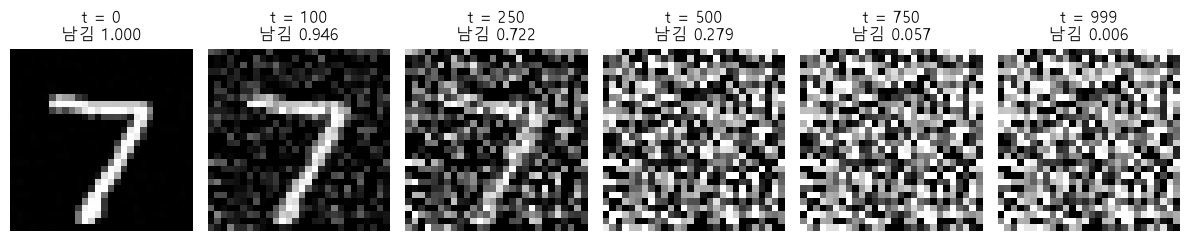

마지막 단계 · 사진을 남기는 비율 0.006 · 노이즈 비율 1.000
사진 비율이 처음 0.5 아래로 · t = 368 (1000단계 중 앞쪽 37%)


In [20]:
# [수업 재현 D2-6] Diffusion 정방향: 남기는 비율 · 노이즈 비율 (식 · 역방향은 생성모델-1 4장)
betas = torch.linspace(1e-4, 0.02, 1000)                  # 1000단계 동안 섞을 노이즈 양 (DDPM 일정)
abar = torch.cumprod(1 - betas, 0)                        # t단계까지 사진이 남은 정도 (누적 곱)
keep, noise = abar.sqrt(), (1 - abar).sqrt()              # 사진을 남기는 비율 · 노이즈 비율
x0 = X_te[:1]                                             # 시험 사진 한 장 (숫자 7)
# 노이즈 하나를 모든 단계에
eps = torch.randn(1, 1, 28, 28, generator=torch.Generator().manual_seed(SEED))
steps = [0, 100, 250, 500, 750, 999]                      # 보여 줄 단계
fig, ax = plt.subplots(1, len(steps), figsize=(12, 2.4))  # 한 줄
for a, t in zip(ax, steps):  # 단계마다 한 번에 계산 (단계마다 새로 더해 간 기록은 아님)
    xt = keep[t] * x0 + noise[t] * eps                    # t단계의 사진
    a.imshow(((xt[0, 0] + 1) / 2).clamp(0, 1), cmap="gray")  # 0 ~ 1로 그림
    a.set_title(f"t = {t}\n남김 {keep[t]:.3f}")           # 단계 · 남기는 비율
    a.axis("off")                                         # 축 숨김
plt.tight_layout()                                        # 간격 정리
plt.show()                                                # 그림 표시
# 거의 노이즈만
print(f"마지막 단계 · 사진을 남기는 비율 {keep[999]:.3f} · 노이즈 비율 {noise[999]:.3f}")
half = int((keep < 0.5).nonzero()[0])                     # 남기는 비율이 처음 0.5 아래로 가는 단계
# 앞에서 빨리 줄어듦
print(f"사진 비율이 처음 0.5 아래로 · t = {half} (1000단계 중 앞쪽 {half / 10:.0f}%)")

**결과** · 예측 정답은 아님 — t = 368, 앞쪽 37%에서 이미 절반 아래 (생성모델-1 변형 문제 2와 같은 값)

- `마지막 단계 · 사진을 남기는 비율 0.006 · 노이즈 비율 1.000` — 끝에는 거의 노이즈만 (수업과 같은 값)
- `사진 비율이 처음 0.5 아래로 · t = 368 (1000단계 중 앞쪽 37%)` — 앞에서 빨리 줄어듦

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">GAN · cGAN</td>
<td style="text-align: left;">생성자 · 판별자가 겨룸 · 만들 때 한 번 · 균형 · 쏠림이 어려움</td>
<td style="text-align: left;">빠른 생성 · 작은 데이터 실습</td>
</tr>
<tr>
<td style="text-align: left;">Diffusion</td>
<td style="text-align: left;">섞인 노이즈 맞히기(MSE) · 판별자 없음 · 만들 때 여러 단계(느림)</td>
<td style="text-align: left;">고품질 · 다양성 (요즘 이미지 생성)</td>
</tr>
</tbody>
</table>

> ⚠️ **주의**
>
> - 그림은 노이즈 하나를 모든 단계에 같이 써서 단계마다 비율로 한 번에 계산한 모습
> - 단계마다 새 노이즈를 더해 간 기록은 아님

> ✅ **한 줄 정리** · Diffusion은 판별자 없이 섞인 노이즈를 맞히며 여러 단계로 만들고, 요즘 모델은 안정 · 지정 · 겨루지 않기 세 축으로 발전했다.

**딥러닝 코드에서는**

- 새 모델을 만나면 이름을 외우기보다 '세 축 중 무엇을 바꿨나'를 물음 (예: 텍스트 조건 Diffusion = ② + ③)

---
## 5. 종합 실습 · 판별자 라벨 없음 vs 있음, seed만 바꿔 다시

> **이 장의 흐름**
>
> - 2 · 3장 비교(판별자 라벨 있음 vs 없음)는 한 번 학습한 결과
> - 수업 D2-5 "같은 비교를 시작값만 바꿔 다시 해 보는 것이 다음 단계"를 직접 해 봄
> - 3장에서 점검한 측정으로 **같은 판정표**(일치율 · 라벨 안 다양성 · FID)를 seed 42 · 43 두 번

**파이프라인 위치** · 같은 조건 학습 → 같은 생성 노이즈 → 판정표 → 결론이 유지되는지

> 🎯 **seed만 바꿔 다시 학습해도 '판별자에 라벨이 있어야 요청한 숫자가 나온다'는 결론이 유지되는가?**

💡 **쉽게 말하면**

- 한 번 해 본 실험은 우연일 수 있음 → **나머지는 모두 같게, 시작값(seed)만** 바꿔 다시 함.
- 측정 숫자가 조금씩 달라도 **결론의 방향**이 같으면 믿을 근거가 늘어남.

<img src="images/gen2_judge.png" alt="판정표: 측정마다 잡는 것 · 못 잡는 것" width="912">

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">같은 조건</th>
<th style="text-align: left;">값</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">모델 · 학습</td>
<td style="text-align: left;">CondG + CondD / PlainD · Adam 2e-4 · β₁ 0.5 · 묶음 128 · 8 epoch (2-2 <code>train_cgan</code>)</td>
</tr>
<tr>
<td style="text-align: left;">평가</td>
<td style="text-align: left;">라벨마다 500장 · 생성 노이즈 seed 42 고정 · 3-1 분류기 · 기준 = 시험 5,000장</td>
</tr>
<tr>
<td style="text-align: left;">다른 점</td>
<td style="text-align: left;">학습 seed 42(2장 모델) vs 43(새로 학습)</td>
</tr>
</tbody>
</table>

**실행 흐름**

1. seed 43으로 판별자 라벨 있음 · 없음 두 모델을 새로 학습 → seed 42 두 모델과 함께 판정표 네 줄 + 진짜 기준 줄 (5-1)
2. seed 43 격자 두 장 · 측정 세 가지 막대 그림 (5-2)

**먼저 예측** · seed 43에서 판별자 라벨 없음 모델의 일치율은 0.1 근처를 벗어날까? — 답은 코드 실행 결과 아래에

In [21]:
# [보강] 종합 실습: 판별자 라벨 없음 vs 있음을 seed만 바꿔(43) 다시 학습 → 같은 판정표
G_lab2, _ = train_cgan(CondD, 8, seed=43)                                    # 라벨 있음 · seed 43
G_nol2, _ = train_cgan(PlainD, 8, seed=43)                                   # 라벨 없음 · seed 43
TABLE = {}  # (모델, seed) → 일치율 · 다양성 · FID
for (name, seed), G in {("라벨 있음", 42): G_lab, ("라벨 없음", 42): G_nol,  # 2장 모델
                        ("라벨 있음", 43): G_lab2, ("라벨 없음", 43): G_nol2}.items():  # 새 모델
    TABLE[name, seed] = judge(G)  # 4-1b와 같은 방법 (생성 노이즈도 같은 seed 42)
print(f"{'판별자':8} | seed | 일치율 | 다양성 |   FID")                      # 표 머리
for (name, seed), (m, dv, f) in TABLE.items():                               # 네 줄
    print(f"{name:8} | {seed:4} | {m:6.3f} | {dv:6.2f} | {f:6.2f}")          # 한 줄
print(f"{'진짜 시험':8} |    - | {match(real5, lab5):6.3f} | {diversity(real5, lab5):6.2f}"  # 기준
      f" | {FID_BASE:6.2f}")                                                 # 3-5 기준선

판별자      | seed | 일치율 | 다양성 |   FID
라벨 있음    |   42 |  0.967 |  17.55 |  21.54
라벨 없음    |   42 |  0.051 |  16.43 |  26.65
라벨 있음    |   43 |  0.976 |  17.90 |  22.55
라벨 없음    |   43 |  0.102 |  16.58 |  31.98
진짜 시험    |    - |  0.975 |  17.53 |   8.37


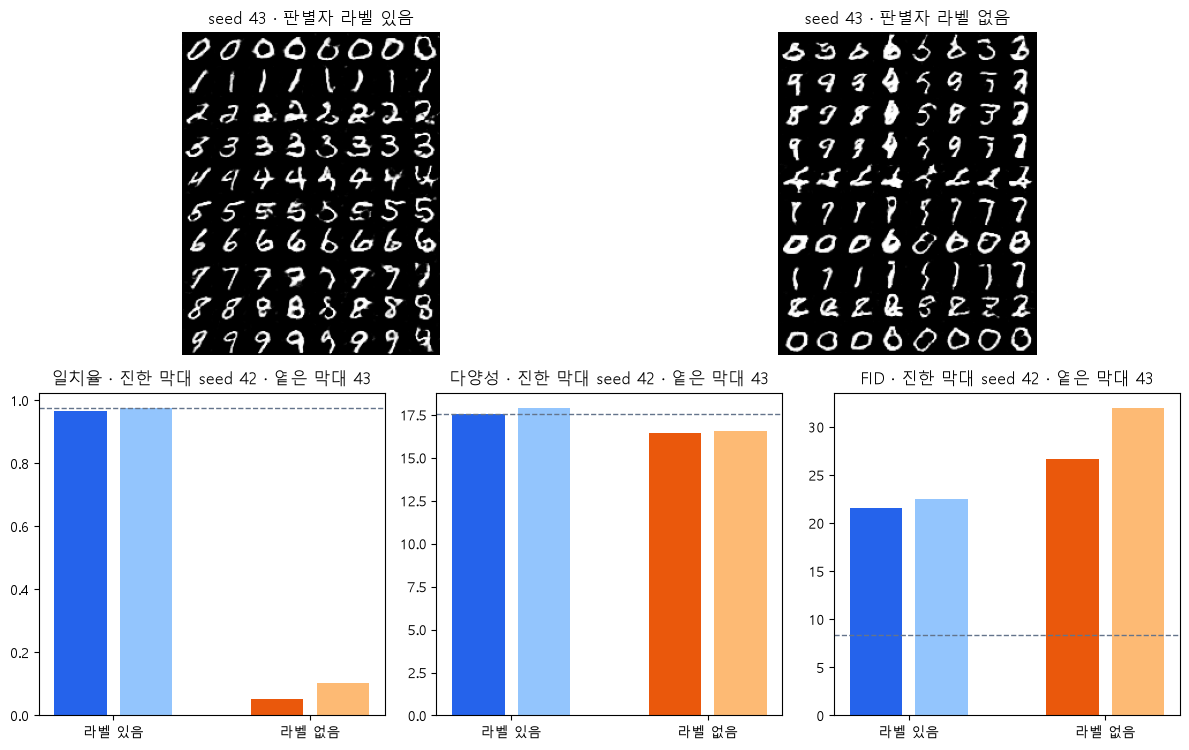

In [22]:
# [보강] 종합 실습 그림: seed 43 격자 두 장 + 측정 세 가지 막대 (seed 42 · 43)
fig = plt.figure(figsize=(12, 7.6))                                 # 위 = 격자 · 아래 = 막대
gs = fig.add_gridspec(2, 6)  # 6칸 바둑판: 위는 3칸씩 · 아래는 2칸씩
with torch.no_grad():                                               # 생성만
    # seed 43 두 모델
    for c, (name, G) in enumerate([("라벨 있음", G_lab2), ("라벨 없음", G_nol2)]):
        a = fig.add_subplot(gs[0, c * 3:c * 3 + 3])                 # 위 칸
        a.imshow(grid(G(FIX_Z.to(device), FIX_Y.to(device)), 10), cmap="gray")  # 같은 고정 노이즈
        a.set_title(f"seed 43 · 판별자 {name}")                     # 칸 제목
        a.axis("off")                                               # 축 숨김
# 진함 42 · 옅음 43
COLORS = {"라벨 있음": ["#2563eb", "#93c5fd"], "라벨 없음": ["#ea580c", "#fdba74"]}
for k, (metric, ref) in enumerate([("일치율", match(real5, lab5)),  # 아래 막대 3개
                                   ("다양성", diversity(real5, lab5)), ("FID", FID_BASE)]):
    a = fig.add_subplot(gs[1, k * 2:k * 2 + 2])                     # 아래 칸
    for j, name in enumerate(COLORS):                               # 모델마다 막대 두 개(seed)
        vals = [TABLE[name, s][k] for s in (42, 43)]                # seed 42 · 43
        a.bar([j * 3, j * 3 + 1], vals, color=COLORS[name])         # 같은 모델은 같은 색 계열
    a.axhline(ref, color="#64748b", ls="--", lw=1)  # 점선 = 진짜 시험 사진 (FID는 진짜 vs 진짜)
    a.set_xticks([0.5, 3.5], list(COLORS))                          # 모델 이름
    a.set_title(f"{metric} · 진한 막대 seed 42 · 옅은 막대 43")     # 칸 제목
plt.tight_layout()                                                  # 간격 정리
plt.show()                                                          # 그림 표시

**결과** · 예측 정답은 **벗어나지 않음** (0.102)

- 일치율은 seed와 상관없이 라벨 있음 0.97 안팎 · 라벨 없음 0.1 이하 → 결론 유지
- FID는 seed 43에서 차이가 더 벌어짐 (22.55 vs 31.98) → FID의 차이 크기는 학습마다 달라짐
- GPU(RTX 3060)에서 실행한 값 · 같은 seed로 두 번 실행해 같은 값 확인

- `라벨 있음 | 42 | 0.967 | 17.55 | 21.54` — 2 · 3장 모델 (3장 값 재사용)
- `라벨 없음 | 42 | 0.051 | 16.43 | 26.65` — 2 · 3장 모델
- `라벨 있음 | 43 | 0.976 | 17.90 | 22.55` — seed만 바꿔 새로 학습
- `라벨 없음 | 43 | 0.102 | 16.58 | 31.98` — 일치율은 여전히 아무거나 고른 수준
- `진짜 시험 | - | 0.975 | 17.53 | 8.37` — 기준 (FID는 진짜 vs 진짜 기준선)

**판정표 읽기**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">측정</th>
<th style="text-align: left;">라벨 있음 (42 · 43)</th>
<th style="text-align: left;">라벨 없음 (42 · 43)</th>
<th style="text-align: left;">진짜</th>
<th style="text-align: left;">읽는 법</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">일치율</td>
<td style="text-align: left;">0.967 · 0.976</td>
<td style="text-align: left;">0.051 · 0.102</td>
<td style="text-align: left;">0.975</td>
<td style="text-align: left;"><strong>두 seed 모두 큰 차이 → 결론 유지</strong></td>
</tr>
<tr>
<td style="text-align: left;">라벨 안 다양성</td>
<td style="text-align: left;">17.55 · 17.90</td>
<td style="text-align: left;">16.43 · 16.58</td>
<td style="text-align: left;">17.53</td>
<td style="text-align: left;">라벨 있음이 진짜에 더 가까움 · 차이는 작음</td>
</tr>
<tr>
<td style="text-align: left;">FID</td>
<td style="text-align: left;">21.54 · 22.55</td>
<td style="text-align: left;">26.65 · 31.98</td>
<td style="text-align: left;">8.37</td>
<td style="text-align: left;">라벨 있음이 두 번 다 낮음 · 차이 크기는 seed마다 다름</td>
</tr>
</tbody>
</table>

**그림 읽는 법**

- 위 = seed 43 두 모델의 같은 고정 격자 (줄 = 요청한 라벨) · 라벨 없음은 seed 42와 **다른 숫자에 묶인 줄**이 생김
- 아래 = 측정 세 가지 · 진한 막대 seed 42 · 옅은 막대 seed 43 · 점선 = 진짜 시험 사진 (FID는 진짜 vs 진짜 기준선)

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">한 번 학습한 비교</td>
<td style="text-align: left;">빠름 · 우연인지 모름</td>
<td style="text-align: left;">아이디어를 고를 때</td>
</tr>
<tr>
<td style="text-align: left;">seed만 바꿔 반복</td>
<td style="text-align: left;">결론의 방향이 같은지 확인 · 학습 횟수만큼 시간</td>
<td style="text-align: left;">보고서 · 미션에 결론을 쓸 때</td>
</tr>
<tr>
<td style="text-align: left;">판정표 (여러 측정)</td>
<td style="text-align: left;">측정마다 속는 꼼수를 서로 막음 · 그래도 못 막는 것이 남음</td>
<td style="text-align: left;">생성 결과를 근거로 보일 때</td>
</tr>
</tbody>
</table>

> ⚠️ **주의**
>
> - seed 두 번은 여전히 적은 횟수 → '두 번 다 같은 방향'까지만 말함
> - 라벨 없음 모델이 어느 숫자에 묶이는지는 seed마다 다름 → 특정 숫자 결과를 일반화하지 않기

> ✅ **한 줄 정리** · seed만 바꿔 다시 학습해도 판별자에 라벨이 없으면 일치율이 아무거나 고른 수준이라는 결론은 유지되고, FID 차이의 크기는 학습마다 달라진다.

**딥러닝 코드에서는**

- 실험 함수에 `seed` 인자를 두고 같은 비교를 반복하는 습관 (`train_cgan(D_cls, epochs, seed)`)
- 판정표를 seed별로 쌓아 평균 · 범위로 보고

---
## 그래서 오늘 무엇을 배웠는가?

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">학습 목표</th>
<th style="text-align: left;">할 수 있게 된 것</th>
<th style="text-align: left;">확인 위치</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">1. 라벨 넣기</td>
<td style="text-align: left;">번호 그대로 거리 1 · 6 → one-hot 1.414 · 1.414 · Embedding = one-hot × 표 (True) · 74칸</td>
<td style="text-align: left;">1-1 · 1-2</td>
</tr>
<tr>
<td style="text-align: left;">2. cGAN 두 차례</td>
<td style="text-align: left;">라벨 판 채널 1 → 2 (가중치 +8,864) · 진짜 (x, y) · 가짜 (fake, yf) 짝 · eval 차이 0.000</td>
<td style="text-align: left;">2-1 · 2-2</td>
</tr>
<tr>
<td style="text-align: left;">3. 판별자 라벨 필요</td>
<td style="text-align: left;">격자 일치율 0.938 vs 0.087 · 5,000장 0.967 vs 0.051 · 라벨 없음은 2를 달라면 0 (493장)</td>
<td style="text-align: left;">2-4 · 3-1 · 3-3</td>
</tr>
<tr>
<td style="text-align: left;">4. 점검한 측정 · 판정표</td>
<td style="text-align: left;">반복 · 무작위 · 섞은 라벨 → 0.1 근처 · 복사 거리 0.02 · 2칸 옮김은 못 잡음 · FID 21.54 vs 26.65는 조건을 못 봄</td>
<td style="text-align: left;">3-1 ~ 3-5</td>
</tr>
<tr>
<td style="text-align: left;">5. 하나씩 · seed 반복</td>
<td style="text-align: left;">스무딩만 바꾼 B는 원인을 말할 수 있음 · 여섯 곳 바꾼 C는 FID 24.24로 엇갈림 · seed 43도 0.976 vs 0.102</td>
<td style="text-align: left;">4-1 · 5</td>
</tr>
</tbody>
</table>

### 주제별 한 줄 · 반드시 기억할 것

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: center;">등급</th>
<th style="text-align: left;">주제</th>
<th style="text-align: left;">반드시 기억할 것</th>
<th style="text-align: left;">코드에서</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: center;"><code>A</code></td>
<td style="text-align: left;">라벨 모양</td>
<td style="text-align: left;">번호 그대로는 크기가 생김 · one-hot · Embedding</td>
<td style="text-align: left;"><code>nn.Embedding(10, 10)(y)</code></td>
</tr>
<tr>
<td style="text-align: center;"><code>A</code></td>
<td style="text-align: left;">생성자 조건</td>
<td style="text-align: left;">노이즈 뒤에 라벨 줄 (칸 방향)</td>
<td style="text-align: left;"><code>torch.cat([z, emb(y)], dim=1)</code></td>
</tr>
<tr>
<td style="text-align: center;"><code>A</code></td>
<td style="text-align: left;">판별자 조건</td>
<td style="text-align: left;">라벨 판을 사진 뒤 채널로 (1 → 2)</td>
<td style="text-align: left;"><code>torch.cat([x, emb(y).view(-1, 1, 28, 28)], 1)</code></td>
</tr>
<tr>
<td style="text-align: center;"><code>A</code></td>
<td style="text-align: left;">조건부 두 차례</td>
<td style="text-align: left;">(진짜, y) 1 · (가짜, yf) 0 · 생성자 (가짜, yf) 1</td>
<td style="text-align: left;"><code>bce(D(fake.detach(), yf), 0)</code></td>
</tr>
<tr>
<td style="text-align: center;"><code>A</code></td>
<td style="text-align: left;">그림 그리기</td>
<td style="text-align: left;">eval + no_grad, 학습 때 다시 train</td>
<td style="text-align: left;"><code>G.eval()</code> · <code>torch.no_grad()</code></td>
</tr>
<tr>
<td style="text-align: center;"><code>A</code></td>
<td style="text-align: left;">판별자 라벨</td>
<td style="text-align: left;">없으면 요청한 숫자가 안 나옴</td>
<td style="text-align: left;">일치율 · 혼동 행렬</td>
</tr>
<tr>
<td style="text-align: center;"><code>A</code></td>
<td style="text-align: left;">도구 점검</td>
<td style="text-align: left;">용도마다 답을 아는 입력으로 먼저</td>
<td style="text-align: left;">반복 · 무작위 · 섞은 라벨 → 0.1</td>
</tr>
<tr>
<td style="text-align: center;"><code>A</code></td>
<td style="text-align: left;">판정표</td>
<td style="text-align: left;">베끼기 · 다양성 · 일치율 · FID를 같이</td>
<td style="text-align: left;"><code>judge(G)</code></td>
</tr>
<tr>
<td style="text-align: center;"><code>A</code></td>
<td style="text-align: left;">비교</td>
<td style="text-align: left;">손잡이는 한 번에 하나 · seed 바꿔 다시</td>
<td style="text-align: left;"><code>train_cgan(..., smooth=0.9)</code> · <code>seed=43</code></td>
</tr>
<tr>
<td style="text-align: center;"><code>B</code></td>
<td style="text-align: left;">FID</td>
<td style="text-align: left;">특징 가운데 · 퍼짐 차이 · 조건은 못 봄</td>
<td style="text-align: left;"><code>inception_v3</code> · <code>scipy.linalg.sqrtm</code></td>
</tr>
<tr>
<td style="text-align: center;"><code>B</code></td>
<td style="text-align: left;">IS</td>
<td style="text-align: left;">한 장 확신 · 전체 고르게 · 진짜와 비교 안 함</td>
<td style="text-align: left;">개념만</td>
</tr>
<tr>
<td style="text-align: center;"><code>B</code></td>
<td style="text-align: left;">Diffusion</td>
<td style="text-align: left;">섞인 노이즈 맞히기 · 여러 단계 · 판별자 없음</td>
<td style="text-align: left;"><code>torch.cumprod(1 - betas, 0)</code></td>
</tr>
</tbody>
</table>

---
## 기억 확인 문제

- 위 내용을 **보지 않고** 답한 뒤, ✅ 한 줄 정리와 비교해 ○ (정확) · △ (일부) · × (모름)를 표시
- △ · ×인 섹션만 다시 보기

### 1. 질문에 답하기

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">섹션</th>
<th style="text-align: left;">🎯 질문</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">1-1</td>
<td style="text-align: left;">라벨 번호를 그대로 넣으면 무엇이 문제이고, one-hot · Embedding은 어떻게 해결하는가?</td>
</tr>
<tr>
<td style="text-align: left;">1-2</td>
<td style="text-align: left;">노이즈와 라벨 줄은 어느 방향으로 붙이고, 생성자에서 바뀌는 곳은?</td>
</tr>
<tr>
<td style="text-align: left;">2-1</td>
<td style="text-align: left;">판별자는 라벨을 어떤 모양으로 받는가?</td>
</tr>
<tr>
<td style="text-align: left;">2-2</td>
<td style="text-align: left;">cGAN 두 차례는 Day1과 무엇이 다르고, 그림은 왜 eval · no_grad로 그리는가?</td>
</tr>
<tr>
<td style="text-align: left;">2-3</td>
<td style="text-align: left;">손실 기록으로 cGAN 품질을 말할 수 있는가?</td>
</tr>
<tr>
<td style="text-align: left;">2-4</td>
<td style="text-align: left;">판별자에 라벨이 없으면 생성자는 라벨을 무시하는가?</td>
</tr>
<tr>
<td style="text-align: left;">3-1</td>
<td style="text-align: left;">분류기로 일치율을 재기 전에 무엇을 점검했나?</td>
</tr>
<tr>
<td style="text-align: left;">3-2</td>
<td style="text-align: left;">가장 가까운 학습 사진 거리는 무엇을 잡고 무엇을 못 잡는가?</td>
</tr>
<tr>
<td style="text-align: left;">3-3</td>
<td style="text-align: left;">라벨 안 다양성은 클수록 좋은가? 일치율은 두 모델에서 어땠나?</td>
</tr>
<tr>
<td style="text-align: left;">3-4</td>
<td style="text-align: left;">한 장 반복 · 복사 · 2칸 옮긴 복사는 각각 어느 측정이 잡는가?</td>
</tr>
<tr>
<td style="text-align: left;">3-5</td>
<td style="text-align: left;">FID로 cGAN의 조건(요청한 숫자)을 평가할 수 있는가?</td>
</tr>
<tr>
<td style="text-align: left;">4-1</td>
<td style="text-align: left;">실습 노트북 설정(C)이 더 좋게 나오면 무엇 때문이라고 말할 수 있는가?</td>
</tr>
<tr>
<td style="text-align: left;">4-2</td>
<td style="text-align: left;">Diffusion은 GAN과 무엇이 다른가?</td>
</tr>
<tr>
<td style="text-align: left;">5</td>
<td style="text-align: left;">seed만 바꿔 다시 하면 결론이 유지되었나?</td>
</tr>
</tbody>
</table>

#### 내 답 · 이 셀을 더블클릭해서 작성

**1-1** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**1-2** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**2-1** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**2-2** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**2-3** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**2-4** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**3-1** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**3-2** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**3-3** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**3-4** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**3-5** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**4-1** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**4-2** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**5** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

### 2. 코드로 답하기

아래 빈 셀에 직접 작성 후 실행.

1. `F.one_hot(torch.tensor([3]), 10)`을 리스트로 출력
2. `nn.Embedding(5, 3)`의 가중치 개수를 출력
3. 노이즈 `torch.zeros(2, 64)`와 라벨 줄 `torch.zeros(2, 10)`을 칸 방향으로 이어 붙인 모양을 출력
4. 사진 `torch.zeros(2, 1, 28, 28)` 뒤에 라벨 판 `torch.zeros(2, 1, 28, 28)`을 채널로 이어 붙인 모양을 출력
5. 요청 라벨 `torch.tensor([1, 2, 3, 4])`와 분류기가 본 숫자 `torch.tensor([1, 2, 0, 4])`의 일치율을 출력

In [23]:
# 코드 문제 직접 작성

### 3. 변형 문제 · 조건을 바꿔 다시 풀기

1. 1-1의 one-hot 거리를 **번호 20종류**(`F.one_hot(..., 20)`)로 바꾸면 3과 17의 거리는? 예측 → 실행
2. 1-2의 생성자에서 라벨 줄을 **16칸**(`CondG(ed=16)`)으로 바꾸면 가중치는 603,045에서 몇 개 늘어날까? 손으로 먼저 계산
3. 3-3의 `diversity`에 **라벨마다 두 장만 번갈아 반복**한 사진을 넣으면 0보다 클까? 진짜보다 클까 작을까?
4. 3-1 점검에서 **같은 사진 1000번**을 그 사진의 정답 라벨(7)로만 물으면 일치율은? 이 점검이 왜 쓸모없어지는지 설명

In [24]:
# 변형 문제 직접 작성

### 4. 모범 답안 · 1 ~ 3을 다 푼 뒤에 보기

#### 질문 답

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">섹션</th>
<th style="text-align: left;">답</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">1-1</td>
<td style="text-align: left;">번호의 크기 · 거리가 뜻을 가짐(7과 8 거리 1, 7과 1 거리 6) → one-hot은 모든 거리 1.414, Embedding은 one-hot × 표를 줄 꺼내기로</td>
</tr>
<tr>
<td style="text-align: left;">1-2</td>
<td style="text-align: left;">dim=1(칸 방향)으로 64 + 10 = 74칸 · Embedding이 생기고 첫 Linear 입력이 64 → 74</td>
</tr>
<tr>
<td style="text-align: left;">2-1</td>
<td style="text-align: left;">Embedding(10, 784) 줄을 28 × 28 판으로 접어 사진 뒤에 채널로 · 첫 Conv2d 채널 1 → 2</td>
</tr>
<tr>
<td style="text-align: left;">2-2</td>
<td style="text-align: left;">진짜는 자기 라벨, 가짜는 넣은 라벨과 짝 · eval은 BatchNorm이 묶음 구성에 흔들리지 않게(차이 0.376 → 0.000), no_grad는 기록 낭비 없게</td>
</tr>
<tr>
<td style="text-align: left;">2-3</td>
<td style="text-align: left;">아님. 마지막 묶음 값이라 흔들림(생성자 2.669 → 1.666) → 고정 노이즈 · 고정 라벨 격자로 확인</td>
</tr>
<tr>
<td style="text-align: left;">2-4</td>
<td style="text-align: left;">아님. 같은 노이즈 · 다른 라벨 거리 18.15로 다른 그림을 내지만, 요청한 숫자와 맞추지 못함</td>
</tr>
<tr>
<td style="text-align: left;">3-1</td>
<td style="text-align: left;">진짜 + 맞는 라벨(0.979) · 같은 사진 반복 · 무작위 · 섞은 라벨(셋 다 0.1 근처) → 통과</td>
</tr>
<tr>
<td style="text-align: left;">3-2</td>
<td style="text-align: left;">그대로 베끼기는 잡음(0.02) · 2칸 옮긴 베끼기는 못 잡음(12.16) → 외우지 않았다는 증명은 아님</td>
</tr>
<tr>
<td style="text-align: left;">3-3</td>
<td style="text-align: left;">아님, 진짜(17.53)와 비슷한지를 봄(무작위 22.85) · 일치율은 라벨 있음 0.967 · 없음 0.051</td>
</tr>
<tr>
<td style="text-align: left;">3-4</td>
<td style="text-align: left;">반복 = 다양성 0 · 복사 = 가장 가까운 거리 0 · 2칸 옮긴 복사 = 세 측정 모두 못 잡음</td>
</tr>
<tr>
<td style="text-align: left;">3-5</td>
<td style="text-align: left;">없음. 21.54 vs 26.65로 가깝지만 일치율은 0.967 vs 0.051 → 일치율과 따로 봄</td>
</tr>
<tr>
<td style="text-align: left;">4-1</td>
<td style="text-align: left;">말할 수 없음. 여섯 곳이 동시에 달라 원인을 모름 · 측정도 엇갈림 (일치율 0.979 높음 · FID 24.24 나쁨)</td>
</tr>
<tr>
<td style="text-align: left;">4-2</td>
<td style="text-align: left;">판별자 없이 섞인 노이즈를 맞히도록 학습 · 만들 때 여러 단계를 거꾸로(느림) · 어려운 점이 균형 대신 단계 수 · 계산량</td>
</tr>
<tr>
<td style="text-align: left;">5</td>
<td style="text-align: left;">유지. seed 43도 일치율 0.976 vs 0.102 · FID 차이 크기는 달라짐(22.55 vs 31.98)</td>
</tr>
</tbody>
</table>

#### 코드 문제 답

```python
# 1. 10칸 중 3번 칸만 1
print(F.one_hot(torch.tensor([3]), 10)[0].tolist())  # [0, 0, 0, 1, 0, 0, 0, 0, 0, 0]

# 2. 번호 5종류 × 줄마다 3칸
print(nn.Embedding(5, 3).weight.numel())  # 15

# 3. 칸 방향으로 64 + 10
print(tuple(torch.cat([torch.zeros(2, 64), torch.zeros(2, 10)], dim=1).shape))  # (2, 74)

# 4. 채널 방향으로 1 + 1
img = torch.zeros(2, 1, 28, 28)
print(tuple(torch.cat([img, torch.zeros(2, 1, 28, 28)], dim=1).shape))  # (2, 2, 28, 28)

# 5. 넷 중 셋이 맞음
print((torch.tensor([1, 2, 3, 4]) == torch.tensor([1, 2, 0, 4])).float().mean().item())  # 0.75
```

#### 변형 문제 답

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">문제</th>
<th style="text-align: left;">답</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">1</td>
<td style="text-align: left;">1.414 — 종류 수와 상관없이 one-hot의 두 번호 거리는 늘 √2</td>
</tr>
<tr>
<td style="text-align: left;">2</td>
<td style="text-align: left;">37,692개 — 라벨 표 10 × 6 = 60 + 첫 Linear에 늘어난 입력 6칸 × 출력 6,272 = 37,632 (편향은 그대로)</td>
</tr>
<tr>
<td style="text-align: left;">3</td>
<td style="text-align: left;">0보다 큼 (두 장 사이 거리) · 진짜보다 작음 → 반복이 많으면 다양성이 작게 나와 잡힘</td>
</tr>
<tr>
<td style="text-align: left;">4</td>
<td style="text-align: left;">1.0 근처 (그 사진을 7로 읽으면) — 답을 아는 '틀린 짝'이 없어 측정이 속는지 볼 수 없음 → 점검은 일부러 맞지 않는 짝으로</td>
</tr>
</tbody>
</table>

---
## 오답 노트

- 틀린 문제는 정답을 베끼지 말고 **원인**을 적음
- 다음 복습 때 이 표의 "재발 방지 질문"부터 스스로에게 물어보기

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">틀린 내용</th>
<th style="text-align: left;">틀린 이유</th>
<th style="text-align: left;">올바른 원칙</th>
<th style="text-align: left;">재발 방지 질문</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">(예) FID가 비슷하니 두 cGAN 모두 잘 된다고 답함</td>
<td style="text-align: left;">FID가 조건까지 본다고 착각</td>
<td style="text-align: left;">FID는 전체 분포 차이, 지정은 일치율로</td>
<td style="text-align: left;">요청한 숫자가 나왔는지 따로 쟀나?</td>
</tr>
<tr>
<td style="text-align: left;"></td>
<td style="text-align: left;"></td>
<td style="text-align: left;"></td>
<td style="text-align: left;"></td>
</tr>
<tr>
<td style="text-align: left;"></td>
<td style="text-align: left;"></td>
<td style="text-align: left;"></td>
<td style="text-align: left;"></td>
</tr>
</tbody>
</table>

---
## 면접 30초 답변

**Q1. cGAN은 GAN과 무엇이 다른가요?**
> - 생성자와 판별자 모두에 조건(라벨)을 넣습니다.
> - 생성자는 노이즈 뒤에 라벨 Embedding 줄을 이어 붙이고, 판별자는 라벨을 사진과 같은 크기의 판으로 만들어 채널로 붙입니다.
> - 판별자는 진짜 사진은 그 라벨과, 가짜는 만들 때 넣은 라벨과 짝지어 판정합니다.
> - 제 MNIST 실험에서 판별자에만 라벨을 빼자 일치율이 0.967에서 0.051로 떨어져, 판별자에도 라벨이 필요함을 확인했습니다.

**Q2. 라벨을 one-hot이 아니라 Embedding으로 넣는 이유는요?**
> - 번호를 그대로 넣으면 7이 1보다 8에 가깝다는 뜻 없는 크기가 생깁니다.
> - one-hot은 이를 없애고, Embedding은 one-hot × 가중치 표와 같은 결과를 번호로 줄을 꺼내 바로 얻습니다.
> - 표 값을 학습으로 배우고 줄 길이를 고를 수 있어, 종류가 많아도 입력이 커지지 않습니다.

**Q3. 생성 모델이 잘 만들었는지 어떻게 보이나요?**
> - 숫자 모양 · 다양성 · 지정 세 가지를 따로 재고, 측정마다 답을 아는 입력으로 먼저 점검합니다.
> - 가장 가까운 학습 사진 거리로 베끼기를, 같은 라벨 안 거리로 다양성을, 점검한 분류기의 일치율 · 혼동 행렬로 지정을 봅니다.
> - FID는 진짜와의 전체 분포 차이라 함께 보지만, 조건은 보지 않아 일치율과 따로 봅니다.
> - 같은 실험에서 두 모델의 FID는 21.54와 26.65로 가까웠지만 일치율은 0.967과 0.051로 크게 달랐습니다.

**Q4. 결과를 개선할 때 어떻게 실험하나요?**
> - 손잡이는 한 번에 하나만 바꾸고 나머지는 같게 둡니다.
> - 여러 곳을 한꺼번에 바꾸면 좋아져도 원인을 말할 수 없습니다.
> - 목표 · 설계 · 예상 · 관찰 · 해석 · 다음을 한 장에 기록하고, seed만 바꿔 다시 해 결론이 유지되는지 봅니다.
> - 판별자 라벨 비교를 seed만 바꿔 다시 했을 때도 일치율 차이의 방향이 같아 결론을 유지했습니다.

---
## 최종 요약표

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">함수·문법</th>
<th style="text-align: left;">소속</th>
<th style="text-align: left;">역할</th>
<th style="text-align: left;">코드에서 사용한 위치</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;"><code>F.one_hot(y, 10)</code></td>
<td style="text-align: left;">torch.nn.functional</td>
<td style="text-align: left;">번호 → 그 칸만 1인 10칸 (크기 · 순서 없음)</td>
<td style="text-align: left;">1-1 <code>oh = F.one_hot(torch.tensor([7, 8, 1]), 10).float()</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>nn.Embedding(10, d)</code></td>
<td style="text-align: left;">torch.nn</td>
<td style="text-align: left;">번호로 표의 한 줄(d칸)을 꺼내는 층 · 표 값은 학습</td>
<td style="text-align: left;">1-1 <code>emb = nn.Embedding(3, 2)</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>torch.cat([z, emb(y)], dim=1)</code></td>
<td style="text-align: left;">torch</td>
<td style="text-align: left;">노이즈 뒤에 라벨 줄 이어 붙이기 (칸 방향)</td>
<td style="text-align: left;">1-2 <code>return self.net(torch.cat([z, self.emb(y)], dim=1))</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>CondG</code></td>
<td style="text-align: left;">이 권 모델</td>
<td style="text-align: left;">Day1 DCGAN 생성자 + 라벨 줄 (첫 Linear 74칸)</td>
<td style="text-align: left;">1-2 <code>class CondG(nn.Module):</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>emb(y).view(-1, 1, 28, 28)</code></td>
<td style="text-align: left;">torch.nn · Tensor</td>
<td style="text-align: left;">라벨 줄 784칸 → 28 × 28 판</td>
<td style="text-align: left;">2-1 <code>self.emb = nn.Embedding(10, 784)</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>torch.cat([x, plate], dim=1)</code></td>
<td style="text-align: left;">torch</td>
<td style="text-align: left;">사진 판 뒤에 라벨 판을 채널로 (채널 1 → 2)</td>
<td style="text-align: left;">2-1 <code>"→ 이어 붙임", tuple(torch.cat([img, plate], dim=1).sh…</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>CondD</code> · <code>PlainD</code></td>
<td style="text-align: left;">이 권 모델</td>
<td style="text-align: left;">판별자 라벨 있음 · 없음 (나머지는 같음)</td>
<td style="text-align: left;">2-1 <code>class CondD(nn.Module):</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>train_cgan(D_cls, epochs, seed)</code></td>
<td style="text-align: left;">이 권 함수</td>
<td style="text-align: left;">조건부 두 차례 · 고정 격자 · 마지막 묶음 손실</td>
<td style="text-align: left;">2-2 <code>def train_cgan(D_cls, epochs, seed=SEED, keep=(), …</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>G.train()</code> · <code>G.eval()</code></td>
<td style="text-align: left;">torch.nn.Module</td>
<td style="text-align: left;">BatchNorm이 묶음 값 · 모아 둔 값을 씀</td>
<td style="text-align: left;">2-2 <code>G.train()</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>torch.no_grad()</code></td>
<td style="text-align: left;">torch</td>
<td style="text-align: left;">그림만 계산 · 기울기 기록 끔</td>
<td style="text-align: left;">2-2 <code>with torch.no_grad():</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>match(x, y)</code></td>
<td style="text-align: left;">이 권 함수</td>
<td style="text-align: left;">일치율: 분류기가 본 숫자 = 요청한 라벨인 비율</td>
<td style="text-align: left;">3-1 <code>def match(x, y):</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>nearest(x)</code> · <code>torch.cdist</code></td>
<td style="text-align: left;">이 권 함수 · torch</td>
<td style="text-align: left;">가장 가까운 학습 사진까지 거리 (베끼기 점검)</td>
<td style="text-align: left;">3-2 <code>def nearest(x):</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>diversity(x, y)</code> · <code>torch.pdist</code></td>
<td style="text-align: left;">이 권 함수 · torch</td>
<td style="text-align: left;">같은 라벨 안 모든 짝의 거리 평균</td>
<td style="text-align: left;">3-3 <code>def diversity(x, y, n=100):</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>confusion(x, y)</code> · <code>index_put_</code></td>
<td style="text-align: left;">이 권 함수 · torch</td>
<td style="text-align: left;">혼동 행렬 (줄 = 요청 · 칸 = 본 숫자)</td>
<td style="text-align: left;">3-3 <code>def confusion(x, y):</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>inception_v3(weights=...)</code> · <code>fc = nn.Identity()</code></td>
<td style="text-align: left;">torchvision.models</td>
<td style="text-align: left;">특징 2,048개 추출기</td>
<td style="text-align: left;">3-5 <code>from torchvision.models import Inception_V3_Weight…</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>fid(fa, fb)</code> · <code>scipy.linalg.sqrtm</code></td>
<td style="text-align: left;">이 권 함수 · scipy</td>
<td style="text-align: left;">두 특징 묶음의 Fréchet 거리</td>
<td style="text-align: left;">3-5 <code>def fid(fa, fb):</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>judge(G)</code></td>
<td style="text-align: left;">이 권 함수</td>
<td style="text-align: left;">판정표 한 줄: 일치율 · 다양성 · FID</td>
<td style="text-align: left;">4-1b <code>def judge(G, zd=ZD):</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>smooth * one</code> (라벨 스무딩)</td>
<td style="text-align: left;">학습 손잡이</td>
<td style="text-align: left;">진짜 정답 1 대신 0.9</td>
<td style="text-align: left;">2-2 <code>d_loss = bce(D(x, y), smooth * one) + bce(D(fake.d…</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>NbG</code> · <code>NbD</code> · <code>train_nb</code></td>
<td style="text-align: left;">실습 노트북 모델 · 함수</td>
<td style="text-align: left;">노이즈 100 · D 학습률 1e-4 · G 2번 · 스무딩</td>
<td style="text-align: left;">4-1 <code>class NbG(nn.Module):</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>torch.cumprod(1 - betas, 0)</code></td>
<td style="text-align: left;">torch</td>
<td style="text-align: left;">Diffusion: t단계까지 사진이 남은 정도</td>
<td style="text-align: left;">4-2 <code>abar = torch.cumprod(1 - betas, 0)</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>train_cgan(..., seed=43)</code></td>
<td style="text-align: left;">이 권 함수</td>
<td style="text-align: left;">같은 조건 · 시작값만 바꿔 다시 학습</td>
<td style="text-align: left;">5-1 <code>G_lab2, _ = train_cgan(CondD, 8, seed=43)</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>TABLE[name, seed]</code></td>
<td style="text-align: left;">이 권 변수</td>
<td style="text-align: left;">판정표 (일치율 · 다양성 · FID)</td>
<td style="text-align: left;">5-1 <code>TABLE = {}</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>fig.add_gridspec(2, 6)</code></td>
<td style="text-align: left;">matplotlib</td>
<td style="text-align: left;">위 2칸 · 아래 3칸 배치</td>
<td style="text-align: left;">5-2 <code>gs = fig.add_gridspec(2, 6)</code></td>
</tr>
</tbody>
</table>

### 할 것 · 하지 말 것

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">✅ 할 것</th>
<th style="text-align: left;">⚠️ 하지 말 것</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">라벨은 one-hot 또는 <code>nn.Embedding</code></td>
<td style="text-align: left;">번호를 칸 하나에 그대로</td>
</tr>
<tr>
<td style="text-align: left;">노이즈 뒤에 라벨 줄은 <code>dim=1</code></td>
<td style="text-align: left;">묶음 방향 <code>dim=0</code>으로 붙이기</td>
</tr>
<tr>
<td style="text-align: left;">판별자에도 라벨 (사진 + 라벨 판)</td>
<td style="text-align: left;">생성자에만 라벨</td>
</tr>
<tr>
<td style="text-align: left;">진짜는 자기 라벨 · 가짜는 넣은 라벨과 짝</td>
<td style="text-align: left;">가짜를 다른 라벨과 판정</td>
</tr>
<tr>
<td style="text-align: left;">그림은 <code>G.eval()</code> + <code>no_grad</code>, 학습 때 <code>G.train()</code></td>
<td style="text-align: left;">평가 모드인 채로 다음 epoch 학습</td>
</tr>
<tr>
<td style="text-align: left;">측정은 답을 아는 입력으로 먼저 점검</td>
<td style="text-align: left;">분류기 · FID 값을 그대로 믿기</td>
</tr>
<tr>
<td style="text-align: left;">판정표로 여러 측정을 같이</td>
<td style="text-align: left;">FID 하나로 성공 판정</td>
</tr>
<tr>
<td style="text-align: left;">손잡이는 한 번에 하나 · seed 바꿔 다시</td>
<td style="text-align: left;">여러 곳을 한꺼번에 바꾸고 원인 단정</td>
</tr>
</tbody>
</table>

### 헷갈리는 짝 한눈에 보기

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">짝</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">결론</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">번호 그대로 vs one-hot</td>
<td style="text-align: left;">크기 · 순서가 생김 vs 모든 번호 거리 같음</td>
<td style="text-align: left;">종류 번호는 one-hot 또는 Embedding</td>
</tr>
<tr>
<td style="text-align: left;">one-hot × 표 vs nn.Embedding</td>
<td style="text-align: left;">곱셈으로 줄 꺼내기 vs 번호로 바로 꺼내기</td>
<td style="text-align: left;">같은 결과 · Embedding이 빠르고 간단</td>
</tr>
<tr>
<td style="text-align: left;">torch.cat dim=1 vs dim=0</td>
<td style="text-align: left;">칸 방향(64 + 10 = 74) vs 묶음 방향(장 수)</td>
<td style="text-align: left;">노이즈 뒤에 라벨은 dim=1</td>
</tr>
<tr>
<td style="text-align: left;">판별자 라벨 없음 vs 있음</td>
<td style="text-align: left;">사진만 vs 사진 + 라벨 판(채널 2)</td>
<td style="text-align: left;">있어야 요청한 숫자가 나옴 (일치율)</td>
</tr>
<tr>
<td style="text-align: left;">진짜의 라벨 vs 가짜의 라벨</td>
<td style="text-align: left;">그 사진의 정답 y vs 생성할 때 넣은 yf</td>
<td style="text-align: left;">판별자는 둘 다 짝으로 판정</td>
</tr>
<tr>
<td style="text-align: left;">g.train() vs g.eval()</td>
<td style="text-align: left;">묶음 평균 · 퍼짐 vs 모아 둔 값 (BatchNorm)</td>
<td style="text-align: left;">그림 · 평가는 eval + no_grad</td>
</tr>
<tr>
<td style="text-align: left;">일치율 vs FID</td>
<td style="text-align: left;">요청과 맞는 비율 vs 전체 분포 차이</td>
<td style="text-align: left;">cGAN은 둘 다 · FID만으로는 조건을 못 봄</td>
</tr>
<tr>
<td style="text-align: left;">다양성 큼 vs 진짜와 비슷</td>
<td style="text-align: left;">무작위가 가장 큼 vs 진짜 시험 사진 값 근처</td>
<td style="text-align: left;">진짜와 비슷한지를 봄</td>
</tr>
<tr>
<td style="text-align: left;">FID vs IS</td>
<td style="text-align: left;">진짜와 비교함 vs 진짜와 비교 안 함</td>
<td style="text-align: left;">FID가 표준 · IS는 개념만</td>
</tr>
<tr>
<td style="text-align: left;">GAN vs Diffusion</td>
<td style="text-align: left;">겨루기 · 한 번에 생성 vs 노이즈 맞히기 · 여러 단계</td>
<td style="text-align: left;">생성모델-1 4장 · 이 권 4-2</td>
</tr>
</tbody>
</table>

---
## 다음 복습일

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">언제</th>
<th style="text-align: left;">할 일</th>
<th style="text-align: left;">걸리는 시간</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">내일</td>
<td style="text-align: left;">기억 확인 문제 1을 자료 없이 다시 답하고 오답 노트 갱신</td>
<td style="text-align: left;">15분</td>
</tr>
<tr>
<td style="text-align: left;">3일 뒤</td>
<td style="text-align: left;">변형 문제 4개를 새로 풀기 · 2-2 <code>train_cgan</code>의 한 묶음 부분을 빈 셀에 직접 다시 쓰기</td>
<td style="text-align: left;">20분</td>
</tr>
<tr>
<td style="text-align: left;">7일 뒤</td>
<td style="text-align: left;">4-1에서 다른 손잡이 하나(예: 라벨 줄 10 → 32칸)만 바꿔 판정표가 어디쯤 올지 예측 → 실행</td>
<td style="text-align: left;">30분</td>
</tr>
<tr>
<td style="text-align: left;">14일 뒤</td>
<td style="text-align: left;">오답 노트에 남은 문제만 다시 풀기 · 그림 6장(학습 지도 · 세 가지 · 두 차례 · FID · 판정표 · 세 축)만 보고 설명해 보기</td>
<td style="text-align: left;">15분</td>
</tr>
</tbody>
</table>

---
## 부록

### 이 노트북을 만든 방법

- 수업 Day01 D1-8 + Day02(이미지 생성 2일차 html · D2-1 ~ D2-7) + 코드잇 cGAN 구현하기 실습 노트북을 정리
- **5개 대단원 · 13개 섹션** + 마지막 **종합 실습**(판별자 라벨 없음 vs 있음을 seed만 바꿔 다시)
- **수업 장면은 코드 재현** · 수업 html에는 실행 코드가 없고 출력 · 그림만 있어, 같은 실험을 코드로 다시 만듦
  - 같은 구조(생성자 603,045 · 판별자 147,681 · 138,817)와 같은 설정을 쓰되, 학습 수치는 수업과 조금 다름
- **실습 코드** · cGAN 구현하기 노트북의 FID 계산(3-5)과 모델 · 학습 설정(4-1 C)
- 섹션 제목의 <sub>… · 코드 재현</sub> · <sub>… · 실습 코드</sub> · <sub>… · 코드 보강</sub> 표시, 코드 첫 주석의 `[수업 재현 …]` · `[실습 반영]` · `[보강]`
- 생성모델-1과 겹치는 GAN 기본 · DCGAN 구조 · Diffusion 식은 다시 설명하지 않고 참조
- D2-8 미션 안내는 부록 '미션 준비'에 요약만 (미션 데이터 · 풀이는 넣지 않음)

### 읽는 법

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">표시</th>
<th style="text-align: left;">의미</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;"><code>A</code> · <code>B</code></td>
<td style="text-align: left;"><strong>A</strong> cGAN · 생성 평가 코드에 바로 나오는 필수 · <strong>B</strong> 알아두면 되는 것</td>
</tr>
<tr>
<td style="text-align: left;">🎯</td>
<td style="text-align: left;">이번 섹션에서 답해야 할 질문</td>
</tr>
<tr>
<td style="text-align: left;">💡</td>
<td style="text-align: left;">쉬운 설명 · 비유</td>
</tr>
<tr>
<td style="text-align: left;">⚠️</td>
<td style="text-align: left;">자주 하는 실수</td>
</tr>
<tr>
<td style="text-align: left;">✅</td>
<td style="text-align: left;">기억할 결론 = 🎯 질문의 답</td>
</tr>
<tr>
<td style="text-align: left;"><sub>수업 … · 코드 재현</sub></td>
<td style="text-align: left;">수업 장면을 코드로 다시 만든 섹션</td>
</tr>
<tr>
<td style="text-align: left;"><sub>실습 … · 실습 코드</sub></td>
<td style="text-align: left;">cGAN 구현하기 실습 노트북의 코드를 옮긴 섹션</td>
</tr>
</tbody>
</table>

- **섹션 구성** · 🎯 질문 → 💡 쉬운 설명 → 실행 흐름 → 먼저 예측 → 코드 → 결과 → 차이 · 언제 쓰나 → ⚠️ 주의 → ✅ 한 줄 정리
- **코드 주석** · 셀 첫 줄 = 이 셀이 하는 일, 블록 머리 = 이 블록이 하는 일, 오른쪽 = 그 줄이 필요한 이유

### 원본 → 섹션 대응표

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">원본</th>
<th style="text-align: left;">내용</th>
<th style="text-align: left;">섹션</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">수업 D1-8</td>
<td style="text-align: left;">'7 을 줘' · 생성자 입력은 노이즈뿐 · 확인할 세 가지</td>
<td style="text-align: left;">1-1 · 3장 흐름</td>
</tr>
<tr>
<td style="text-align: left;">수업 Day02 앞부분</td>
<td style="text-align: left;">어제 마지막 질문 · 조건부 생성 · cGAN</td>
<td style="text-align: left;">1장 흐름</td>
</tr>
<tr>
<td style="text-align: left;">수업 D2-1</td>
<td style="text-align: left;">번호 그대로 · one-hot · one-hot × W · nn.Embedding · torch.cat · 라벨 받는 생성자</td>
<td style="text-align: left;">1-1 · 1-2</td>
</tr>
<tr>
<td style="text-align: left;">수업 D2-2</td>
<td style="text-align: left;">판별자 라벨 있음 · 없음 비교 · 도구 점검 · 일치율 · 라벨 판 · 판별자가 판정하는 짝</td>
<td style="text-align: left;">2-1 · 2-4 · 3-1</td>
</tr>
<tr>
<td style="text-align: left;">수업 D2-3</td>
<td style="text-align: left;">조건부 두 차례 · g.eval · no_grad · 8 epoch 격자 · 손실</td>
<td style="text-align: left;">2-2 · 2-3</td>
</tr>
<tr>
<td style="text-align: left;">수업 D2-4</td>
<td style="text-align: left;">베끼기 점검 · 라벨 안 다양성 · 혼동 행렬 · 꼼수 점검표 · FID · IS · 판정표</td>
<td style="text-align: left;">3-2 ~ 3-5</td>
</tr>
<tr>
<td style="text-align: left;">수업 D2-5</td>
<td style="text-align: left;">손잡이 · 라벨 스무딩 · 증강 주의 · 통제 비교 · 실험 기록 한 장</td>
<td style="text-align: left;">4-1 · 5</td>
</tr>
<tr>
<td style="text-align: left;">수업 D2-6</td>
<td style="text-align: left;">Diffusion 정방향 · 역방향 · GAN과 비교</td>
<td style="text-align: left;">4-2 (식 · 역방향은 생성모델-1 4장)</td>
</tr>
<tr>
<td style="text-align: left;">수업 D2-7</td>
<td style="text-align: left;">요즘 생성 모델 세 축</td>
<td style="text-align: left;">4-2</td>
</tr>
<tr>
<td style="text-align: left;">수업 D2-8</td>
<td style="text-align: left;">미션 안내 · 학습 전 정할 것 · 평가 계획 · 체크 카드</td>
<td style="text-align: left;">부록 미션 준비 (요약만)</td>
</tr>
<tr>
<td style="text-align: left;">cGAN 구현하기 실습 1 ~ 8</td>
<td style="text-align: left;">조건 결합 · Generator · Discriminator · 학습 루프(스무딩 · D lr · g_steps) · 조건부 생성</td>
<td style="text-align: left;">1 · 2장 · 4-1 C</td>
</tr>
<tr>
<td style="text-align: left;">cGAN 구현하기 실습 9</td>
<td style="text-align: left;">정성 · 정량 평가 · FID · IS · 진짜 vs 진짜 기준선</td>
<td style="text-align: left;">3-5</td>
</tr>
</tbody>
</table>

### 다른 정리본과 겹치는 내용 (여기서는 참조만)

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">내용</th>
<th style="text-align: left;">자세한 설명</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">GAN 기본 · 판별자 · 두 차례 · detach</td>
<td style="text-align: left;">생성모델-1 2장</td>
</tr>
<tr>
<td style="text-align: left;">DCGAN 구조 · 전치 합성곱 · 범위 맞추기</td>
<td style="text-align: left;">생성모델-1 2-7</td>
</tr>
<tr>
<td style="text-align: left;">세는 도구 점검 (숫자 종류 용도) · 모드 붕괴</td>
<td style="text-align: left;">생성모델-1 3장</td>
</tr>
<tr>
<td style="text-align: left;">Diffusion 전방향 식 · 역방향 · 세 모델 비교</td>
<td style="text-align: left;">생성모델-1 4장</td>
</tr>
<tr>
<td style="text-align: left;">단어 번호 → nn.Embedding</td>
<td style="text-align: left;">RNN-2</td>
</tr>
<tr>
<td style="text-align: left;">BatchNorm · 합성곱</td>
<td style="text-align: left;">CNN-1 · 2</td>
</tr>
</tbody>
</table>

### 미션 준비 (수업 D2-8 요약)

- - 미션: FashionMNIST 10종류를 조건부로 생성하는 cGAN을 설계 · 학습
- 평가 (평가 기준 다섯 영역: 기획 · 전처리 + EDA · 모델 설계 · 학습 + 평가 · 코드 + 문서)
- **학습 전에 정해 둘 것** · 정규화 범위와 생성자 끝 함수 · 라벨 번호의 뜻 · 노이즈 칸 수와 seed · 무엇을 몇 장으로 잴지와 그 점검 · 무엇 하나를 바꿔 볼지
- **평가 계획 고르기** · 가) FID 하나만 vs 나) 클래스별 격자 + 점검한 분류기 일치율 + 같은 클래스 안 다양성 + FID 판정표 → '지정'을 보이려면 나)
- **첫날 체크 카드** · 데이터 범위 · 클래스 이름 확인 · 정할 것 다섯 줄 · 고정 노이즈 + 고정 라벨 격자를 epoch마다 · 실험 기록 한 장 형식
- 데이터 증강은 주의: 판별자가 증강된 사진을 '진짜'로 배우면 생성자도 그런 사진을 만들 수 있음 (D2-5)

### 전체 코드

- 0 ~ 5장 코드를 **장별 · 60줄 이하 셀**로 모음 (본문 셀과 같은 코드, 그림은 닫음 `plt.close`)
- **위에서부터 이 셀들만 실행해도 전체가 동작** (모든 학습 · FID 포함, GPU에서 20분 안팎)

#### 0장 준비

In [25]:
# [보강] 라이브러리 · 재현성 · 장치 설정
import os                 # 환경 변수 설정
import random             # 파이썬 난수 seed
import warnings           # FID 행렬 제곱근 경고 숨김
from pathlib import Path  # 데이터 폴더 경로

if "KMP_DUPLICATE_LIB_OK" not in os.environ:           # Windows Anaconda 충돌 방지
    os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"        # numpy · torch OpenMP 중복
if "CUBLAS_WORKSPACE_CONFIG" not in os.environ:        # GPU 행렬 곱 결정적으로
    os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"  # torch 불러오기 전에

import matplotlib.pyplot as plt      # 격자 · 혼동 행렬 · 막대 그림
import numpy as np                   # FID 공분산 계산
import scipy.linalg                  # FID 행렬 제곱근
import torch                         # 텐서 · 자동 미분
import torch.nn.functional as F      # one_hot · cross_entropy · interpolate
import torchvision                   # MNIST · inception_v3
from matplotlib import font_manager  # 설치된 글꼴 목록
from torch import nn                 # 층 · 손실 함수

SEED = 42  # 모든 난수의 출발점


def set_seed(seed=SEED):                       # 실험마다 같은 출발점으로 되돌림
    random.seed(seed)                          # 파이썬 난수
    np.random.seed(seed)                       # numpy 난수
    torch.manual_seed(seed)                    # CPU · GPU 난수 모두 고정
    torch.cuda.manual_seed_all(seed)           # GPU가 여러 개여도 고정
    torch.backends.cudnn.deterministic = True  # 합성곱 결정적
    torch.backends.cudnn.benchmark = False     # 알고리즘 자동 선택 끔
    torch.use_deterministic_algorithms(True)   # 나머지 연산도 결정적


set_seed()                                              # 노트북 시작 상태 고정
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")  # GPU 없으면 cpu
if device.type == "cuda":                               # 계산은 GPU가 하므로 CPU 스레드는 1개로
    torch.set_num_threads(1)                            # 작은 CPU 연산의 스레드 경쟁 방지
print("torch", torch.__version__, "| device:", device)  # 실행 환경 확인

torch 2.11.0+cu128 | device: cuda


In [26]:
# [보강] 그림 한글 글꼴 · 공통 손실 · 격자 그림 함수
fonts = {f.name for f in font_manager.fontManager.ttflist}    # 설치된 글꼴 이름
for name in ["Malgun Gothic", "AppleGothic", "NanumGothic"]:  # Windows · Mac · Linux 순서
    if name in fonts:                                         # 있는 글꼴만
        plt.rcParams["font.family"] = name                    # 그림 제목의 한글이 깨지지 않게
        break                                                 # 첫 번째로 찾은 것 사용
plt.rcParams["axes.unicode_minus"] = False                    # 음수 부호 깨짐 방지
bce = nn.BCEWithLogitsLoss()                                  # 판별자 출력 = 로짓 (sigmoid 전 점수)


def grid(x, rows):  # 사진 묶음 (N, 1, 28, 28) → 줄 rows개짜리 한 장
    x = (x.detach().cpu().view(rows, -1, 28, 28) + 1) / 2  # -1 ~ 1 → 0 ~ 1
    return x.permute(0, 2, 1, 3).reshape(rows * 28, -1)    # 줄 · 칸 순서로 이어 붙임


def n_par(m):                                      # 가중치 개수 (학습으로 고치는 숫자의 개수)
    return sum(p.numel() for p in m.parameters())  # 층마다 가중치 · 편향 개수의 합

In [27]:
# [보강] MNIST: 없으면 내려받음 (약 12MB, 처음 1번) · 학습 6만 장 · 시험 1만 장
DATA = Path("data")                                                         # 노트북 옆 data/ 폴더
mnist = torchvision.datasets.MNIST(DATA, train=True, download=True)         # 학습용 6만 장
test = torchvision.datasets.MNIST(DATA, train=False, download=True)         # 시험용 1만 장
X = (mnist.data.float() / 255 * 2 - 1).view(-1, 1, 28, 28)  # -1 ~ 1 · 판 한 장 (생성자 Tanh와 맞춤)
Y = mnist.targets  # 라벨 = 사진이 어떤 숫자인지 (0 ~ 9)
X_te = (test.data.float() / 255 * 2 - 1).view(-1, 1, 28, 28)                # 시험 사진도 같은 범위
Y_te = test.targets                                                         # 시험 라벨
print("학습:", tuple(X.shape), "| 시험:", tuple(X_te.shape),                # 모양
      "| 범위:", X.min().item(), "~", X.max().item())
print("라벨 앞 10개", Y[:10].tolist(), "| 라벨 종류", Y.unique().tolist())  # 번호 0 ~ 9

학습: (60000, 1, 28, 28) | 시험: (10000, 1, 28, 28) | 범위: -1.0 ~ 1.0
라벨 앞 10개 [5, 0, 4, 1, 9, 2, 1, 3, 1, 4] | 라벨 종류 [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]


#### 1장 라벨 넣기

In [28]:
# [수업 재현 D1-8 · D2-1] 번호를 생성자 입력에 넣는 세 가지: 번호 그대로 · one-hot · Embedding
ZD = 64  # 노이즈(잠재 벡터) 길이 (생성모델-1과 같음)
z = torch.randn(1, ZD, generator=torch.Generator().manual_seed(SEED))  # 어제 생성자의 입력
print("어제 생성자 입력", tuple(z.shape), "· 64칸 어디에도 숫자를 정하는 자리가 없음")  # 노이즈뿐

num = torch.tensor([7.0, 8.0, 1.0])                                  # 번호를 칸 하나에 그대로
print("번호 그대로 · 7과 8의 거리", (num[0] - num[1]).abs().item(),  # 1
      "· 7과 1의 거리", (num[0] - num[2]).abs().item())              # 6 → 크기 · 순서가 뜻을 가짐
oh = F.one_hot(torch.tensor([7, 8, 1]), 10).float()                  # 10칸 중 그 번호 칸만 1
print("one-hot 1 →", oh[2].int().tolist())                           # 0번부터 세니 왼쪽에서 둘째 칸
print("one-hot 7 →", oh[0].int().tolist())                           # 여덟째 칸
print(f"one-hot 7과 8의 거리 {torch.dist(oh[0], oh[1]):.3f}"         # 어느 두 번호든
      f" · 7과 1의 거리 {torch.dist(oh[0], oh[2]):.3f}")             # 같은 거리 √2

# 작은 예: 번호 3종류 · 줄마다 2칸인 가중치 표 W
W = torch.tensor([[1.0, 2.0], [3.0, 4.0], [5.0, 6.0]])  # 3 × 2 표
pick = F.one_hot(torch.tensor([1]), 3).float() @ W  # one-hot [0, 1, 0] × W
emb = nn.Embedding(3, 2)                            # 번호 3종류 × 줄마다 2칸
with torch.no_grad():                               # 표 값을 직접 넣음 (학습 아님)
    emb.weight.copy_(W)                             # 같은 표로 맞춤
row = emb(torch.tensor([1]))                        # 번호 1로 줄 꺼내기
print("one-hot × W =", pick[0].tolist(), "· W의 1번 줄 =", W[1].tolist())  # 곱셈 = 줄 꺼내기
print("Embedding으로 번호 1 →", row[0].tolist(),    # 같은 줄
      "· one-hot × W와 같음:", torch.equal(row, pick))
set_seed()                                          # 표 초기값 고정
emb10 = nn.Embedding(10, 10)                        # 번호 10종류 × 줄마다 10칸 (생성자에 넣을 크기)
print("Embedding(10, 10)에 번호 7 → 모양", tuple(emb10(torch.tensor([7])).shape),  # (1, 10)
      "· 표의 가중치 개수", n_par(emb10))           # 10 × 10 = 100

어제 생성자 입력 (1, 64) · 64칸 어디에도 숫자를 정하는 자리가 없음
번호 그대로 · 7과 8의 거리 1.0 · 7과 1의 거리 6.0
one-hot 1 → [0, 1, 0, 0, 0, 0, 0, 0, 0, 0]
one-hot 7 → [0, 0, 0, 0, 0, 0, 0, 1, 0, 0]
one-hot 7과 8의 거리 1.414 · 7과 1의 거리 1.414
one-hot × W = [3.0, 4.0] · W의 1번 줄 = [3.0, 4.0]
Embedding으로 번호 1 → [3.0, 4.0] · one-hot × W와 같음: True
Embedding(10, 10)에 번호 7 → 모양 (1, 10) · 표의 가중치 개수 100


In [29]:
# [수업 재현 D2-1] torch.cat으로 노이즈 뒤에 라벨 줄 이어 붙이기 → 라벨을 받는 생성자
class CondG(nn.Module):  # Day1 DCGAN 생성자 + 라벨 줄 (다른 곳 둘: Embedding · 첫 Linear 입력 74)
    def __init__(self, zd=ZD, ed=10):    # 노이즈 칸 수 · 라벨 줄 칸 수
        super().__init__()               # nn.Module 준비
        self.emb = nn.Embedding(10, ed)  # 라벨 번호 → 10칸 줄 (학습으로 배움)
        self.net = nn.Sequential(        # 이하 생성모델-1 2-7 DCGAN 생성자와 같음
            nn.Linear(zd + ed, 128 * 7 * 7), nn.Unflatten(1, (128, 7, 7)),  # 74 → 판 128개 7 × 7
            nn.BatchNorm2d(128), nn.ReLU(),
            nn.ConvTranspose2d(128, 64, 4, 2, 1), nn.BatchNorm2d(64), nn.ReLU(),  # 14 × 14
            nn.ConvTranspose2d(64, 1, 4, 2, 1), nn.Tanh())  # 28 × 28 · -1 ~ 1

    def forward(self, z, y):                                 # 노이즈 (N, 64) · 라벨 번호 (N,)
        return self.net(torch.cat([z, self.emb(y)], dim=1))  # 칸 방향으로 이어 붙여 넣음


gen = torch.Generator().manual_seed(SEED)                                     # 예시 노이즈 고정
z4 = torch.randn(4, ZD, generator=gen)                                        # 노이즈 4개
y4 = torch.tensor([7, 7, 1, 3])                                               # 라벨 4개
set_seed()                                                                    # 초기값 고정
G0 = CondG()                                                                  # 학습 전 생성자
print("노이즈", tuple(z4.shape), "+ 라벨 줄", tuple(G0.emb(y4).shape),        # (4, 64) + (4, 10)
      "→ 이어 붙임", tuple(torch.cat([z4, G0.emb(y4)], dim=1).shape))         # (4, 74)
print("입력 노이즈 (4, 64) + 라벨 4개 → 출력 모양", tuple(G0(z4, y4).shape))  # 사진 4장
print(f"가중치 개수 {n_par(G0):,} (DCGAN 생성자 540,225 + 라벨 표 100"        # 늘어난 몫
      f" + 첫 Linear 10칸 × 6,272 = 62,720)")

노이즈 (4, 64) + 라벨 줄 (4, 10) → 이어 붙임 (4, 74)
입력 노이즈 (4, 64) + 라벨 4개 → 출력 모양 (4, 1, 28, 28)
가중치 개수 603,045 (DCGAN 생성자 540,225 + 라벨 표 100 + 첫 Linear 10칸 × 6,272 = 62,720)


#### 2장 cGAN 판별자 · 학습

In [30]:
# [수업 재현 D2-2] 라벨을 판 모양으로 만들어 사진 뒤에 채널로 이어 붙이기
img = torch.zeros(1, 1, 4, 4)  # 작은 예: 4 × 4 사진 한 장 (묶음 · 채널 · 높이 · 너비)
set_seed()                                                         # 표 초기값 고정
plate = nn.Embedding(10, 16)(torch.tensor([7])).view(1, 1, 4, 4)   # 줄 16칸 → 4 × 4 판
print("사진", tuple(img.shape), "+ 라벨 판", tuple(plate.shape),   # 같은 크기 판 두 장
      "→ 이어 붙임", tuple(torch.cat([img, plate], dim=1).shape))  # 채널 1 → 2


class CondD(nn.Module):  # Day1 DCGAN 판별자 + 라벨 판 (다른 곳: 첫 Conv2d 입력 채널 1 → 2)
    def __init__(self):                                    # 층 만들기
        super().__init__()                                 # nn.Module 준비
        self.emb = nn.Embedding(10, 784)                   # 라벨 번호 → 784칸 → 28 × 28 판
        self.net = nn.Sequential(                          # 이하 생성모델-1 2-7 DCGAN 판별자와 같음
            nn.Conv2d(2, 64, 4, 2, 1), nn.LeakyReLU(0.2),  # 사진 판 + 라벨 판 → 64판 14 × 14
            nn.Conv2d(64, 128, 4, 2, 1), nn.BatchNorm2d(128), nn.LeakyReLU(0.2),  # 128판 7 × 7
            nn.Flatten(), nn.Linear(128 * 7 * 7, 1))       # 값 하나 (로짓)

    def forward(self, x, y):  # 사진 (N, 1, 28, 28) · 라벨 번호 (N,)
        return self.net(torch.cat([x, self.emb(y).view(-1, 1, 28, 28)], dim=1))  # 채널로 이어 붙임


class PlainD(nn.Module):  # 비교용: 라벨을 받지만 쓰지 않는 판별자 (생성모델-1 DCGAN 판별자 그대로)
    def __init__(self):            # 층 만들기
        super().__init__()         # nn.Module 준비
        self.net = nn.Sequential(  # 사진 판 한 장만
            nn.Conv2d(1, 64, 4, 2, 1), nn.LeakyReLU(0.2),
            nn.Conv2d(64, 128, 4, 2, 1), nn.BatchNorm2d(128), nn.LeakyReLU(0.2),
            nn.Flatten(), nn.Linear(128 * 7 * 7, 1))

    def forward(self, x, y):  # 학습 코드를 똑같이 쓰려고 y도 받음
        return self.net(x)    # y는 버림 → 사진만 보고 판정


set_seed()                                                                # 초기값 고정
x4 = torch.zeros(4, 1, 28, 28)                                            # 사진 4장
for name, d in [("라벨 있음", CondD()), ("라벨 없음", PlainD())]:         # 두 판별자
    print(f"판별자 {name} · 사진 (4, 1, 28, 28) + 라벨 4개 → 출력 모양",  # 사진마다 값 하나
          tuple(d(x4, y4).shape), f"· 가중치 개수 {n_par(d):,}")

사진 (1, 1, 4, 4) + 라벨 판 (1, 1, 4, 4) → 이어 붙임 (1, 2, 4, 4)
판별자 라벨 있음 · 사진 (4, 1, 28, 28) + 라벨 4개 → 출력 모양 (4, 1) · 가중치 개수 147,681
판별자 라벨 없음 · 사진 (4, 1, 28, 28) + 라벨 4개 → 출력 모양 (4, 1) · 가중치 개수 138,817


In [31]:
# [수업 재현 D2-3] 조건부 두 차례: 진짜는 자기 라벨과 · 가짜는 넣은 라벨과 짝으로 판정
# 노이즈 8개
FIX_Z = torch.randn(8, ZD, generator=torch.Generator().manual_seed(SEED)).repeat(10, 1)
FIX_Y = torch.arange(10).repeat_interleave(8)  # 줄 = 라벨 0 ~ 9 · 열 = 같은 노이즈 8개


def train_cgan(D_cls, epochs, seed=SEED, keep=(), smooth=1.0):          # D_cls = CondD 또는 PlainD
    set_seed(seed)  # 같은 seed면 같은 초기값 · 같은 묶음 순서
    G, D = CondG().to(device), D_cls().to(device)                       # 생성자 · 판별자
    og = torch.optim.Adam(G.parameters(), lr=2e-4, betas=(0.5, 0.999))  # G만 고침
    od = torch.optim.Adam(D.parameters(), lr=2e-4, betas=(0.5, 0.999))  # D만 고침
    gen = torch.Generator().manual_seed(seed)  # 섞기 · 노이즈 · 가짜 라벨 고정
    Xd, Yd, B = X.to(device), Y.to(device), 128                         # 데이터 · 묶음 크기
    one = torch.ones(B, 1, device=device)                               # 정답 1
    log = {"d": [], "g": [], "grid": {}}                                # epoch별 기록
    for epoch in range(1, epochs + 1):                                  # epoch = 학습 사진 한 바퀴
        G.train()  # 학습 모드 (BatchNorm이 그 묶음의 평균 · 퍼짐을 씀)
        D.train()                                                       # 판별자도 학습 모드
        perm = torch.randperm(len(Xd), generator=gen).to(device)        # 섞은 번호
        for i in range(0, len(Xd) - B + 1, B):                          # 꽉 찬 묶음 468개
            x, y = Xd[perm[i:i + B]], Yd[perm[i:i + B]]                 # 진짜 사진 · 그 사진의 라벨
            yf = torch.randint(0, 10, (B,), generator=gen).to(device)   # 가짜에 넣을 라벨 (무작위)
            fake = G(torch.randn(B, ZD, generator=gen).to(device), yf)  # 넣은 라벨로 가짜
            # (진짜, y) 1 · (가짜, yf) 0
            d_loss = bce(D(x, y), smooth * one) + bce(D(fake.detach(), yf), 0 * one)
            od.zero_grad()                                              # 쌓인 기울기 비우기
            d_loss.backward()                                           # 기울기 계산
            od.step()                                                   # D만 고침
            g_loss = bce(D(fake, yf), one)  # 생성자 차례: (가짜, yf)를 1로
            og.zero_grad()                                              # 쌓인 기울기 비우기
            g_loss.backward()                                           # D를 지나 G까지
            og.step()                                                   # G만 고침
        log["d"].append(d_loss.item())  # 마지막 묶음 손실 (수업 기록과 같은 방식)
        log["g"].append(g_loss.item())                                  # 생성자 손실도 같은 방식
        if epoch in keep:                                               # 격자를 남길 epoch
            G.eval()  # 평가 모드: BatchNorm이 모아 둔 평균 · 퍼짐을 씀
            with torch.no_grad():                                       # 그림만 · 기울기 계산 끔
                log["grid"][epoch] = G(FIX_Z.to(device), FIX_Y.to(device)).cpu()  # 같은 고정 노이즈
    G.eval()  # 학습이 끝나면 평가 모드로 돌려줌
    return G, log                                                       # 학습된 생성자 · 기록

In [32]:
# [수업 재현 D2-3] 그림 그릴 때 g.eval() · no_grad가 필요한 이유 (학습 전 생성자로 확인)
set_seed()                                                                         # 초기값 고정
g = CondG().to(device)                                                             # 학습 전 생성자
z, y = FIX_Z[:8].to(device), torch.full((8,), 7, device=device)  # 같은 노이즈 8개 · 라벨 7
other = torch.randn(8, ZD, generator=torch.Generator().manual_seed(1)).to(device)  # 다른 노이즈 8개
with torch.no_grad():                                                              # 그림만 계산
    g.train()                                                                      # 학습 모드
    a = g(z, y)[0]                                                                 # 묶음 A의 첫 장
    b = g(torch.cat([z[:1], other[1:]]), y)[0]  # 첫 장은 같고 나머지만 바꾼 묶음 B의 첫 장
    # 묶음 구성에 흔들림
    print(f"학습 모드 · 같은 입력인데 첫 장 차이 {(a - b).abs().max().item():.3f}")
    g.eval()                                                                       # 평가 모드
    a, b = g(z, y)[0], g(torch.cat([z[:1], other[1:]]), y)[0]                      # 다시 두 묶음
    print(f"평가 모드 · 같은 입력 첫 장 차이 {(a - b).abs().max().item():.3f}")    # 0
    print("no_grad 안 출력이 기울기 기록을 갖나:", g(z, y).requires_grad)          # False
print("no_grad 밖 출력이 기울기 기록을 갖나:", g(z, y).requires_grad)  # True → 그림만 그릴 땐 낭비

학습 모드 · 같은 입력인데 첫 장 차이 0.376
평가 모드 · 같은 입력 첫 장 차이 0.000
no_grad 안 출력이 기울기 기록을 갖나: False
no_grad 밖 출력이 기울기 기록을 갖나: True


In [33]:
# [수업 재현 D2-3] 판별자에 라벨 있는 cGAN을 8 epoch · 고정 노이즈 격자 1 · 2 · 4 · 8 epoch
G_lab, log_lab = train_cgan(CondD, 8, keep=(1, 2, 4, 8))  # 라벨 있음 (수업 오늘 모델)
for e in (1, 2, 4, 8):                                    # 격자를 남긴 epoch
    print(f"epoch {e} · 마지막 묶음 손실 판별자 {log_lab['d'][e - 1]:.3f}"  # 두 손실
          f" · 생성자 {log_lab['g'][e - 1]:.3f}")
fig, ax = plt.subplots(1, 4, figsize=(13, 4.6))           # 격자 4장
for a, e in zip(ax, (1, 2, 4, 8)):                        # epoch마다
    a.imshow(grid(log_lab["grid"][e], 10), cmap="gray")   # 줄 = 라벨 0 ~ 9 · 열 = 같은 노이즈
    a.set_title(f"epoch {e}")                             # 칸 제목
    a.axis("off")                                         # 축 숨김
plt.tight_layout()                                        # 간격 정리
plt.close()                                               # 부록에서는 그림 닫기

epoch 1 · 마지막 묶음 손실 판별자 0.780 · 생성자 2.197
epoch 2 · 마지막 묶음 손실 판별자 0.612 · 생성자 2.265
epoch 4 · 마지막 묶음 손실 판별자 0.578 · 생성자 2.669
epoch 8 · 마지막 묶음 손실 판별자 0.796 · 생성자 1.666


In [34]:
# [수업 재현 D2-2] 판별자만 라벨 없음으로 바꾸고 나머지는 같게 8 epoch → 같은 고정 노이즈 격자
G_nol, log_nol = train_cgan(PlainD, 8, keep=(8,))  # 생성자 · 학습률 · epoch · seed 같음
fig, ax = plt.subplots(1, 2, figsize=(7.5, 4.8))                       # 두 격자 나란히
pair = [("판별자 라벨 있음", log_lab), ("판별자 라벨 없음", log_nol)]  # 같은 epoch 8 격자
for a, (name, log) in zip(ax, pair):                                   # 왼쪽 · 오른쪽
    a.imshow(grid(log["grid"][8], 10), cmap="gray")                    # 줄 = 요청한 라벨 0 ~ 9
    a.set_title(f"{name} · epoch 8")                                   # 칸 제목
    a.axis("off")                                                      # 축 숨김
plt.tight_layout()                                                     # 간격 정리
plt.close()                                                            # 부록에서는 그림 닫기
with torch.no_grad():  # 같은 노이즈 · 라벨만 바꾸면 그림이 바뀌나 (생성자가 라벨을 무시했나)
    for name, G in [("라벨 있음", G_lab), ("라벨 없음", G_nol)]:       # 두 생성자
        img = G(FIX_Z.to(device), FIX_Y.to(device)).view(10, 8, -1)    # 줄 = 라벨 · 열 = 노이즈
        gap = sum(torch.pdist(img[:, j]).mean().item() for j in range(8)) / 8  # 같은 열 안 줄끼리
        # 0이면 라벨 무시
        print(f"판별자 {name} · 같은 노이즈 · 다른 라벨 사이 평균 거리 {gap:.2f}")

판별자 라벨 있음 · 같은 노이즈 · 다른 라벨 사이 평균 거리 17.55
판별자 라벨 없음 · 같은 노이즈 · 다른 라벨 사이 평균 거리 18.15


#### 3장 생성 평가

In [35]:
# [수업 재현 D2-2] 세는 도구부터 점검: 숫자 분류기의 '요청한 라벨과 맞는지' 용도
set_seed()                                         # 분류기 초기값 고정
clf = nn.Sequential(                               # 작은 CNN 분류기 (생성모델-1 3-1과 같은 구조)
    nn.Conv2d(1, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
    nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
    nn.Flatten(), nn.Linear(32 * 7 * 7, 10)).to(device)
opt = torch.optim.Adam(clf.parameters(), lr=1e-3)  # 분류기 옵티마이저
gen = torch.Generator().manual_seed(SEED)          # 섞는 순서 고정
for epoch in range(3):                             # 3 epoch
    perm = torch.randperm(len(X), generator=gen)   # 섞은 번호
    for i in range(0, len(X), 256):                # 묶음 256장씩
        b = perm[i:i + 256]                        # 이번 묶음 번호
        loss = F.cross_entropy(clf(X[b].to(device)), Y[b].to(device))  # 숫자 분류 손실
        opt.zero_grad()                            # 기울기 비우기
        loss.backward()                            # 기울기 계산
        opt.step()                                 # 분류기 고침
clf.eval()                                         # 평가 모드


def read(x):               # 사진 묶음 → 분류기가 본 숫자
    with torch.no_grad():  # 평가만
        return torch.cat([clf(x[i:i + 1000].to(device)).argmax(1).cpu()  # 1000장씩
                          for i in range(0, len(x), 1000)])


def match(x, y):  # 일치율 = 분류기가 본 숫자가 요청한 라벨과 같은 비율
    return (read(x) == y).float().mean().item()  # 1이면 모두 맞음 · 0.1 = 아무거나 골라 맞을 확률


lab = torch.arange(10).repeat_interleave(100)  # 점검용 라벨 1000개 (0 100개 · 1 100개 …)
gen = torch.Generator().manual_seed(SEED)                     # 점검 입력 고정
real = torch.cat([X_te[Y_te == d][:100] for d in range(10)])  # 진짜 사진 숫자마다 100장 (lab 순서)
checks = {"진짜 사진 + 맞는 라벨": (real, lab),               # 높아야 함
          "같은 사진 1000번": (X_te[:1].repeat(1000, 1, 1, 1), lab),  # 0.1 근처여야 함
          "무작위 사진": (torch.rand(1000, 1, 28, 28, generator=gen) * 2 - 1, lab),  # 0.1 근처
          "진짜 사진 + 섞은 라벨": (real, lab[torch.randperm(1000, generator=gen)])}  # 0.1 근처
print(f"시험 사진 1만 장 정확도 {match(X_te, Y_te):.3f}")     # 도구 자체의 정확도
for name, (x, y) in checks.items():                           # 답을 아는 입력 네 가지
    print(f"일치율 {match(x, y):.3f} · {name}")               # 기대와 맞나
for name, G in [("있음", G_lab), ("없음", G_nol)]:            # 2-4의 두 격자 80장
    with torch.no_grad():                                     # 생성만
        print(f"판별자에 라벨 {name} · 격자 80장 일치율",     # 요청한 숫자가 나왔나
              f"{match(G(FIX_Z.to(device), FIX_Y.to(device)).cpu(), FIX_Y):.3f}")

시험 사진 1만 장 정확도 0.983
일치율 0.979 · 진짜 사진 + 맞는 라벨
일치율 0.100 · 같은 사진 1000번
일치율 0.112 · 무작위 사진
일치율 0.118 · 진짜 사진 + 섞은 라벨
판별자에 라벨 있음 · 격자 80장 일치율 0.938
판별자에 라벨 없음 · 격자 80장 일치율 0.087


In [36]:
# [수업 재현 D2-4] 평가용 생성 5,000장 · ① 베끼기 점검 (가장 가까운 학습 사진)
def make(G, n_per=500, seed=SEED, zd=ZD):           # 라벨 0 ~ 9마다 n_per장 (zd = 노이즈 칸 수)
    yy = torch.arange(10).repeat_interleave(n_per)  # 요청한 라벨
    zz = torch.randn(len(yy), zd, generator=torch.Generator().manual_seed(seed))  # 노이즈 고정
    with torch.no_grad():                           # 생성만
        xx = torch.cat([G(zz[i:i + 1000].to(device), yy[i:i + 1000].to(device)).cpu()  # 1000장씩
                        for i in range(0, len(yy), 1000)])
    return xx, yy                                   # 사진 · 요청한 라벨


GEN = {"있음": make(G_lab), "없음": make(G_nol)}                      # 판별자 라벨 있음 · 없음
print("생성 사진 · 판별자에 라벨 있음", tuple(GEN["있음"][0].shape),  # (5000, 1, 28, 28)
      "· 라벨 없음", tuple(GEN["없음"][0].shape))
Xflat = X.view(len(X), -1).to(device)                                 # 학습 사진 6만 장 (784칸)


def nearest(x):  # 사진마다 학습 6만 장 중 가장 가까운 한 장까지의 거리 (-1 ~ 1 픽셀 거리)
    x = x.reshape(len(x), -1).to(device)                                    # 784칸으로 펼침
    return torch.cat([torch.cdist(x[i:i + 250], Xflat).min(1).values.cpu()  # 250장씩
                      for i in range(0, len(x), 250)])


sub = slice(0, 5000, 5)                                                # 1,000장만 (라벨마다 100장)
rows = {"생성 (판별자 라벨 있음)": GEN["있음"][0][sub], "진짜 시험 사진": X_te[:1000],  # 기준 비교
        "점검 · 학습 사진 그대로": X[:1000],                           # 0이어야 함
        "점검 · 학습 사진 2칸 옮김": torch.roll(X[:1000], 2, dims=3)}  # 베낀 것인데 옮김
for name, x in rows.items():                                           # 네 묶음
    d = nearest(x)                                                     # 1,000개 거리
    print(f"가장 가까운 학습 사진까지 · {name}",                       # 평균 · 최소
          f"평균 {d.mean():.2f} (최소 {d.min():.2f})")

생성 사진 · 판별자에 라벨 있음 (5000, 1, 28, 28) · 라벨 없음 (5000, 1, 28, 28)
가장 가까운 학습 사진까지 · 생성 (판별자 라벨 있음) 평균 10.00 (최소 2.88)
가장 가까운 학습 사진까지 · 진짜 시험 사진 평균 8.48 (최소 2.20)
가장 가까운 학습 사진까지 · 점검 · 학습 사진 그대로 평균 0.02 (최소 0.00)


가장 가까운 학습 사진까지 · 점검 · 학습 사진 2칸 옮김 평균 12.16 (최소 6.90)


In [37]:
# [수업 재현 D2-4] ② 같은 라벨 안의 다양성 · ③ 원하는 숫자 지정 (일치율 · 혼동 행렬)
def diversity(x, y, n=100):  # 라벨마다 n장끼리 모든 짝의 거리 평균 → 라벨 평균
    return sum(torch.pdist(x[y == d][:n].reshape(n, -1)).mean().item()  # 라벨 d 안의 평균 거리
               for d in range(10)) / 10


lab5 = torch.arange(10).repeat_interleave(500)                 # 점검용 라벨 5,000개
real5 = torch.cat([X_te[Y_te == d][:500] for d in range(10)])  # 진짜 시험 사진 라벨마다 500장
gen = torch.Generator().manual_seed(SEED)                      # 무작위 사진 고정
div_rows = {"진짜 시험 사진": real5, "cGAN 라벨 있음": GEN["있음"][0],  # 비교 대상
            "cGAN 라벨 없음": GEN["없음"][0],
            "점검: 라벨마다 한 장 반복": real5[::500].repeat_interleave(500, 0),  # 0이어야 함
            "점검: 무작위 사진": torch.rand(5000, 1, 28, 28, generator=gen) * 2 - 1}  # 가장 큼
for name, x in div_rows.items():                               # 다섯 묶음
    print(f"다양성 {diversity(x, lab5):5.2f} · {name}")        # 진짜와 비슷한지를 봄


def confusion(x, y):  # 줄 = 요청한 숫자 · 칸 = 분류기가 본 숫자 · 값 = 그 줄에서의 비율
    m = torch.zeros(10, 10)                                          # 10 × 10 표
    m.index_put_((y, read(x)), torch.ones(len(y)), accumulate=True)  # (요청, 본 것) 칸에 1씩
    return m / m.sum(1, keepdim=True)                                # 줄마다 비율


print(f"일치율 {match(X_te, Y_te):.3f} · 진짜 시험 사진 1만 장")     # 기준
CM = {}                                                              # 두 모델의 혼동 행렬
for name in ("있음", "없음"):                                        # 판별자 라벨 있음 · 없음
    CM[name] = confusion(*GEN[name])                                 # 5,000장
    print(f"일치율 {CM[name].diag().mean().item():.3f} · cGAN 라벨 {name} 5,000장")  # 대각선 평균
seen = read(GEN["없음"][0][lab5 == 2]).bincount(minlength=10)        # 라벨 없음 · 2를 요청한 500장
print("라벨 없음 · 2를 요청한 500장 중 분류기가 가장 많이 본 숫자",  # 어느 숫자로 묶였나
      f"{seen.argmax().item()} · {seen.max().item()}장")

다양성 17.53 · 진짜 시험 사진
다양성 17.55 · cGAN 라벨 있음
다양성 16.43 · cGAN 라벨 없음
다양성  0.00 · 점검: 라벨마다 한 장 반복
다양성 22.85 · 점검: 무작위 사진


일치율 0.983 · 진짜 시험 사진 1만 장
일치율 0.967 · cGAN 라벨 있음 5,000장
일치율 0.051 · cGAN 라벨 없음 5,000장
라벨 없음 · 2를 요청한 500장 중 분류기가 가장 많이 본 숫자 0 · 493장


In [38]:
# [수업 재현 D2-4] 혼동 행렬 두 장 (줄 = 요청한 숫자 · 칸 = 분류기가 본 숫자)
fig, ax = plt.subplots(1, 2, figsize=(10, 4.4))       # 두 모델 나란히
for a, name in zip(ax, ("있음", "없음")):             # 판별자 라벨 있음 · 없음
    a.imshow(CM[name], cmap="Blues", vmin=0, vmax=1)  # 진할수록 비율이 큼
    for r in range(10):                               # 줄마다
        for c in range(10):                           # 칸마다
            if CM[name][r, c] >= 0.05:                # 5% 이상만 숫자로
                a.text(c, r, f"{CM[name][r, c]:.2f}".lstrip("0"), ha="center", va="center",  # 칸 값
                       fontsize=7, color="white" if CM[name][r, c] > 0.5 else "black")
    a.set_title(f"판별자에 라벨 {name} · 일치율 {CM[name].diag().mean().item():.3f}")  # 칸 제목
    a.set_xlabel("분류기가 본 숫자")                  # 칸
    a.set_ylabel("요청한 숫자")                       # 줄
    a.set_xticks(range(10))                           # 0 ~ 9
    a.set_yticks(range(10))                           # 0 ~ 9
plt.tight_layout()                                    # 간격 정리
plt.close()                                           # 부록에서는 그림 닫기

In [39]:
# [수업 재현 D2-4] 지표 하나로는 못 막는 꼼수 네 가지를 일부러 만들어 세 측정에 넣기
tr5 = torch.cat([X[Y == d][:500] for d in range(10)])              # 학습 사진 라벨마다 500장
cheats = {"라벨마다 한 장만 반복": tr5[::500].repeat_interleave(500, 0),  # 같은 그림 500번
          "라벨별 평균 사진 반복": torch.stack([X[Y == d].mean(0) for d in range(10)])  # 흐린 평균
          .repeat_interleave(500, 0),
          "학습 사진 그대로 복사": tr5,                            # 외운 것
          "학습 사진 2칸 옮김": torch.roll(tr5, 2, dims=3)}        # 외운 것을 살짝 옮김
print(f"{'꼼수':14} | 일치율 | 다양성 | 가장 가까운 거리")         # 표 머리
for name, x in cheats.items():                                     # 네 꼼수
    near = nearest(x[::5]).mean().item()                           # 1,000장만
    print(f"{name:14} | {match(x, lab5):6.3f}",                    # 일치율
          f"| {diversity(x, lab5):6.2f} | {near:6.2f}")
real_near = nearest(real5[::5]).mean().item()                      # 비교 기준: 진짜 시험 사진
print(f"{'기준: 진짜 시험 사진':14} | {match(real5, lab5):6.3f}",  # 같은 세 측정
      f"| {diversity(real5, lab5):6.2f} | {real_near:6.2f}")

꼼수             | 일치율 | 다양성 | 가장 가까운 거리
라벨마다 한 장만 반복   |  1.000 |   0.00 |   0.02
라벨별 평균 사진 반복   |  1.000 |   0.00 |   9.27


학습 사진 그대로 복사   |  0.984 |  17.68 |   0.02
학습 사진 2칸 옮김    |  0.948 |  17.68 |  12.29
기준: 진짜 시험 사진   |  0.975 |  17.53 |   8.58


In [40]:
# [실습 반영] FID: InceptionV3(ImageNet 학습)의 특징 2,048개로 두 묶음의 가운데 · 퍼짐 차이
from torchvision.models import Inception_V3_Weights, inception_v3  # 사전학습 분류 모델

W_INC = Inception_V3_Weights.IMAGENET1K_V1                # ImageNet으로 학습한 가중치
inc = inception_v3(weights=W_INC, transform_input=False)  # 처음 1번 약 104MB 내려받음
inc.fc = nn.Identity()                                    # 마지막 분류층을 떼어 특징 2,048개를 꺼냄
inc = inc.eval().to(device)                               # 평가 모드
MEAN = torch.tensor([0.485, 0.456, 0.406], device=device).view(1, 3, 1, 1)  # ImageNet 평균
STD = torch.tensor([0.229, 0.224, 0.225], device=device).view(1, 3, 1, 1)  # ImageNet 퍼짐


def features(x, bs=100):  # -1 ~ 1 흑백 → 0 ~ 1 → 세 겹 → 299 × 299 → 특징 2,048개
    out = []                                                  # 묶음별 특징
    with torch.no_grad():                                     # 평가만
        for i in range(0, len(x), bs):                        # 100장씩
            v = (x[i:i + bs].to(device) + 1) / 2              # 0 ~ 1
            # 3채널 · 키우기
            v = F.interpolate(v.repeat(1, 3, 1, 1), size=(299, 299), mode="bilinear",
                              align_corners=False)
            out.append(inc((v - MEAN) / STD).double().cpu())  # ImageNet 규격으로 맞춰 넣음
    return torch.cat(out).numpy()                             # (N, 2048)


def fid(fa, fb):  # 두 특징 묶음의 Fréchet 거리 (작을수록 비슷 · 0 = 가운데 · 퍼짐이 같음)
    mu_a, mu_b = fa.mean(0), fb.mean(0)                          # 가운데 (평균)
    ca, cb = np.cov(fa, rowvar=False), np.cov(fb, rowvar=False)  # 퍼짐 (공분산 2,048 × 2,048)
    # 특징 2,048개 중 거의 안 움직이는 칸이 있어 '특이 행렬' 경고가 남
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", scipy.linalg.LinAlgWarning)  # 값은 그대로 · 경고만 숨김
        root = scipy.linalg.sqrtm(ca @ cb).real                  # 행렬 제곱근 (작은 허수부는 버림)
    # 가운데 차이 + 퍼짐 차이
    return float(((mu_a - mu_b) ** 2).sum() + np.trace(ca + cb - 2 * root))


F_REF = features(X_te[:5000])                 # 기준 묶음 = MNIST 시험 사진 5,000장
print("특징 모양", F_REF.shape)               # (5000, 2048)
FID_BASE = fid(F_REF, features(X_te[5000:]))  # 같은 분포 두 묶음 → 내려갈 수 있는 바닥값
print(f"FID {FID_BASE:6.2f} · 기준선:",       # 바닥값
      "진짜 vs 진짜 (시험 앞 · 뒤 5,000장)")

특징 모양 (5000, 2048)


FID   8.37 · 기준선: 진짜 vs 진짜 (시험 앞 · 뒤 5,000장)


In [41]:
# [수업 재현 D2-4] 두 cGAN · 점검 입력 두 가지의 FID (기준 = 시험 사진 5,000장)
gen = torch.Generator().manual_seed(SEED)                               # 무작위 사진 고정
fid_rows = {"cGAN 라벨 있음": GEN["있음"][0], "cGAN 라벨 없음": GEN["없음"][0],  # 두 모델
            # 크게 나와야 함
            "점검: 무작위 사진": torch.rand(5000, 1, 28, 28, generator=gen) * 2 - 1,
            "점검: 한 장 반복": X_te[5000:5001].repeat(5000, 1, 1, 1)}  # 크게 나와야 함
FID = {}                                                                # 결과 모음
for name, x in fid_rows.items():                                        # 네 묶음
    FID[name] = fid(F_REF, features(x))                                 # 5,000장씩
    print(f"FID {FID[name]:6.2f} · {name}")                             # 작을수록 진짜 묶음과 비슷
print("일치율과 나란히 · 라벨 있음", f"{CM['있음'].diag().mean().item():.3f}",  # FID는 가깝고
      "| 라벨 없음", f"{CM['없음'].diag().mean().item():.3f}")          # 일치율은 크게 다름

FID  21.54 · cGAN 라벨 있음


FID  26.65 · cGAN 라벨 없음


FID 493.30 · 점검: 무작위 사진


FID 174.52 · 점검: 한 장 반복
일치율과 나란히 · 라벨 있음 0.967 | 라벨 없음 0.051


#### 4장 더 잘 만들기 · Diffusion

In [42]:
# [실습 반영] 실습 노트북의 cGAN: 노이즈 100 · Embedding 생성자 · BatchNorm 없는 판별자
class NbG(nn.Module):                               # 실습 Generator (라벨 줄 10칸 · 노이즈 100)
    def __init__(self):                             # 층 만들기
        super().__init__()                          # nn.Module 준비
        self.emb = nn.Embedding(10, 10)             # 라벨 → 10칸
        self.fc = nn.Linear(100 + 10, 128 * 7 * 7)  # 노이즈 100 + 라벨 10 → 7 × 7 판 128개
        self.net = nn.Sequential(                   # 7 × 7 → 14 × 14 → 28 × 28
            nn.BatchNorm2d(128), nn.ReLU(True),
            nn.ConvTranspose2d(128, 64, 4, 2, 1), nn.BatchNorm2d(64), nn.ReLU(True),
            nn.ConvTranspose2d(64, 1, 4, 2, 1), nn.Tanh())  # 28 × 28

    def forward(self, z, y):  # 노이즈 · 라벨
        # 이어 붙여 펼침
        return self.net(self.fc(torch.cat([z, self.emb(y)], 1)).view(-1, 128, 7, 7))


class NbD(nn.Module):  # 실습 Discriminator (라벨 판 이어 붙이기 · BatchNorm 없음)
    def __init__(self):                                                    # 층 만들기
        super().__init__()                                                 # nn.Module 준비
        self.emb = nn.Embedding(10, 784)                                   # 라벨 → 28 × 28 판
        self.net = nn.Sequential(nn.Conv2d(2, 64, 4, 2, 1), nn.LeakyReLU(0.2, True),  # 채널 2
                                 nn.Conv2d(64, 128, 4, 2, 1), nn.LeakyReLU(0.2, True),
                                 nn.Flatten(), nn.Linear(128 * 7 * 7, 1))  # 값 하나

    def forward(self, x, y):                                                 # 사진 · 라벨
        return self.net(torch.cat([x, self.emb(y).view(-1, 1, 28, 28)], 1))  # 채널로 이어 붙임


def train_nb(epochs, seed=SEED):  # 실습 학습 루프: 라벨 스무딩 0.9 · D 학습률 절반 · G 2번
    set_seed(seed)                                                      # 초기값 고정
    G, D = NbG().to(device), NbD().to(device)                           # 실습 모델
    og = torch.optim.Adam(G.parameters(), lr=2e-4, betas=(0.5, 0.999))  # G 2e-4
    od = torch.optim.Adam(D.parameters(), lr=1e-4, betas=(0.5, 0.999))  # D 1e-4 (덜 빨리 강해지게)
    gen, B = torch.Generator().manual_seed(seed), 128  # 섞기 · 노이즈 고정 · 묶음 크기
    Xd, Yd = X.to(device), Y.to(device)                                 # 데이터
    one = torch.ones(B, 1, device=device)                               # 정답 1
    for epoch in range(epochs):                                         # epoch 반복
        G.train()                                                       # 학습 모드
        perm = torch.randperm(len(Xd), generator=gen).to(device)        # 섞은 번호
        for i in range(0, len(Xd) - B + 1, B):                          # 꽉 찬 묶음
            # 가짜도 이 묶음의 라벨 y로 (Day02는 무작위)
            x, y = Xd[perm[i:i + B]], Yd[perm[i:i + B]]
            fake = G(torch.randn(B, 100, generator=gen).to(device), y)  # 가짜
            d_loss = bce(D(x, y), 0.9 * one) + bce(D(fake.detach(), y), 0 * one)  # 진짜 정답 0.9
            od.zero_grad()                                              # 기울기 비우기
            d_loss.backward()                                           # 기울기 계산
            od.step()                                                   # D만 고침
            for _ in range(2):                                          # 생성자는 2번 (g_steps = 2)
                fake = G(torch.randn(B, 100, generator=gen).to(device), y)  # 새 노이즈
                g_loss = bce(D(fake, y), one)                           # 가짜를 1로
                og.zero_grad()                                          # 기울기 비우기
                g_loss.backward()                                       # 기울기 계산
                og.step()                                               # G만 고침
    G.eval()                                                            # 평가 모드
    return G  # 학습된 실습 생성자 (노이즈 100칸)

In [43]:
# [수업 재현 D2-5] 손잡이 바꾸기: 하나만 바꾼 비교 vs 여러 곳을 한꺼번에 바꾼 비교
JUDGED = {}  # 생성자 → 판정표 한 줄 (FID는 5,000장에 1분 남짓이라 한 번만 계산)


def judge(G, zd=ZD):           # 판정표 한 줄: 일치율 · 다양성 · FID (5,000장)
    if G not in JUDGED:        # 처음 재는 생성자만
        x, y = make(G, zd=zd)  # 라벨마다 500장 (노이즈 seed 42 고정)
        JUDGED[G] = match(x, y), diversity(x, y), fid(F_REF, features(x))  # 세 측정
    return JUDGED[G]           # 같은 생성자는 저장한 값


for G, name in [(G_lab, "있음"), (G_nol, "없음")]:  # 3장에서 잰 값 재사용 (make 노이즈 같음)
    m = CM[name].diag().mean().item()               # 3-3 일치율
    JUDGED[G] = m, diversity(*GEN[name]), FID[f"cGAN 라벨 {name}"]  # 3-3 다양성 · 3-5b FID


G_smooth, _ = train_cgan(CondD, 8, smooth=0.9)             # A에서 진짜 정답 1 → 0.9 하나만 바꿈
G_nb = train_nb(8)  # 실습 설정: 노이즈 · 모델 · 학습률 · G 횟수 · 스무딩 · 가짜 라벨 여러 곳이 다름
print(f"{'모델':22} | 일치율 | 다양성 |   FID")            # 표 머리
models = [("A 오늘 cGAN (2-3)", G_lab, ZD), ("B A + 라벨 스무딩 0.9", G_smooth, ZD),  # 세 모델
          ("C 실습 노트북 설정", G_nb, 100)]               # C만 노이즈 100칸
for name, G, zd in models:                                 # 같은 판정표
    m, dv, f = judge(G, zd)                                # 같은 방법으로 잼
    print(f"{name:22} | {m:6.3f} | {dv:6.2f} | {f:6.2f}")  # 한 줄

모델                     | 일치율 | 다양성 |   FID
A 오늘 cGAN (2-3)        |  0.967 |  17.55 |  21.54


B A + 라벨 스무딩 0.9       |  0.973 |  17.52 |  20.73


C 실습 노트북 설정            |  0.979 |  18.22 |  24.24


In [44]:
# [수업 재현 D2-6] Diffusion 정방향: 남기는 비율 · 노이즈 비율 (식 · 역방향은 생성모델-1 4장)
betas = torch.linspace(1e-4, 0.02, 1000)                  # 1000단계 동안 섞을 노이즈 양 (DDPM 일정)
abar = torch.cumprod(1 - betas, 0)                        # t단계까지 사진이 남은 정도 (누적 곱)
keep, noise = abar.sqrt(), (1 - abar).sqrt()              # 사진을 남기는 비율 · 노이즈 비율
x0 = X_te[:1]                                             # 시험 사진 한 장 (숫자 7)
# 노이즈 하나를 모든 단계에
eps = torch.randn(1, 1, 28, 28, generator=torch.Generator().manual_seed(SEED))
steps = [0, 100, 250, 500, 750, 999]                      # 보여 줄 단계
fig, ax = plt.subplots(1, len(steps), figsize=(12, 2.4))  # 한 줄
for a, t in zip(ax, steps):  # 단계마다 한 번에 계산 (단계마다 새로 더해 간 기록은 아님)
    xt = keep[t] * x0 + noise[t] * eps                    # t단계의 사진
    a.imshow(((xt[0, 0] + 1) / 2).clamp(0, 1), cmap="gray")  # 0 ~ 1로 그림
    a.set_title(f"t = {t}\n남김 {keep[t]:.3f}")           # 단계 · 남기는 비율
    a.axis("off")                                         # 축 숨김
plt.tight_layout()                                        # 간격 정리
plt.close()                                               # 부록에서는 그림 닫기
# 거의 노이즈만
print(f"마지막 단계 · 사진을 남기는 비율 {keep[999]:.3f} · 노이즈 비율 {noise[999]:.3f}")
half = int((keep < 0.5).nonzero()[0])                     # 남기는 비율이 처음 0.5 아래로 가는 단계
# 앞에서 빨리 줄어듦
print(f"사진 비율이 처음 0.5 아래로 · t = {half} (1000단계 중 앞쪽 {half / 10:.0f}%)")

마지막 단계 · 사진을 남기는 비율 0.006 · 노이즈 비율 1.000
사진 비율이 처음 0.5 아래로 · t = 368 (1000단계 중 앞쪽 37%)


#### 5장 종합 실습

In [45]:
# [보강] 종합 실습: 판별자 라벨 없음 vs 있음을 seed만 바꿔(43) 다시 학습 → 같은 판정표
G_lab2, _ = train_cgan(CondD, 8, seed=43)                                    # 라벨 있음 · seed 43
G_nol2, _ = train_cgan(PlainD, 8, seed=43)                                   # 라벨 없음 · seed 43
TABLE = {}  # (모델, seed) → 일치율 · 다양성 · FID
for (name, seed), G in {("라벨 있음", 42): G_lab, ("라벨 없음", 42): G_nol,  # 2장 모델
                        ("라벨 있음", 43): G_lab2, ("라벨 없음", 43): G_nol2}.items():  # 새 모델
    TABLE[name, seed] = judge(G)  # 4-1b와 같은 방법 (생성 노이즈도 같은 seed 42)
print(f"{'판별자':8} | seed | 일치율 | 다양성 |   FID")                      # 표 머리
for (name, seed), (m, dv, f) in TABLE.items():                               # 네 줄
    print(f"{name:8} | {seed:4} | {m:6.3f} | {dv:6.2f} | {f:6.2f}")          # 한 줄
print(f"{'진짜 시험':8} |    - | {match(real5, lab5):6.3f} | {diversity(real5, lab5):6.2f}"  # 기준
      f" | {FID_BASE:6.2f}")                                                 # 3-5 기준선

판별자      | seed | 일치율 | 다양성 |   FID
라벨 있음    |   42 |  0.967 |  17.55 |  21.54
라벨 없음    |   42 |  0.051 |  16.43 |  26.65
라벨 있음    |   43 |  0.976 |  17.90 |  22.55
라벨 없음    |   43 |  0.102 |  16.58 |  31.98
진짜 시험    |    - |  0.975 |  17.53 |   8.37


In [46]:
# [보강] 종합 실습 그림: seed 43 격자 두 장 + 측정 세 가지 막대 (seed 42 · 43)
fig = plt.figure(figsize=(12, 7.6))                                 # 위 = 격자 · 아래 = 막대
gs = fig.add_gridspec(2, 6)  # 6칸 바둑판: 위는 3칸씩 · 아래는 2칸씩
with torch.no_grad():                                               # 생성만
    # seed 43 두 모델
    for c, (name, G) in enumerate([("라벨 있음", G_lab2), ("라벨 없음", G_nol2)]):
        a = fig.add_subplot(gs[0, c * 3:c * 3 + 3])                 # 위 칸
        a.imshow(grid(G(FIX_Z.to(device), FIX_Y.to(device)), 10), cmap="gray")  # 같은 고정 노이즈
        a.set_title(f"seed 43 · 판별자 {name}")                     # 칸 제목
        a.axis("off")                                               # 축 숨김
# 진함 42 · 옅음 43
COLORS = {"라벨 있음": ["#2563eb", "#93c5fd"], "라벨 없음": ["#ea580c", "#fdba74"]}
for k, (metric, ref) in enumerate([("일치율", match(real5, lab5)),  # 아래 막대 3개
                                   ("다양성", diversity(real5, lab5)), ("FID", FID_BASE)]):
    a = fig.add_subplot(gs[1, k * 2:k * 2 + 2])                     # 아래 칸
    for j, name in enumerate(COLORS):                               # 모델마다 막대 두 개(seed)
        vals = [TABLE[name, s][k] for s in (42, 43)]                # seed 42 · 43
        a.bar([j * 3, j * 3 + 1], vals, color=COLORS[name])         # 같은 모델은 같은 색 계열
    a.axhline(ref, color="#64748b", ls="--", lw=1)  # 점선 = 진짜 시험 사진 (FID는 진짜 vs 진짜)
    a.set_xticks([0.5, 3.5], list(COLORS))                          # 모델 이름
    a.set_title(f"{metric} · 진한 막대 seed 42 · 옅은 막대 43")     # 칸 제목
plt.tight_layout()                                                  # 간격 정리
plt.close()                                                         # 부록에서는 그림 닫기